# 04 — GP Correlated Errors (Models D and E, SPARC only) — **Debugged revision**

**Project:** *Is the RAR Universal? Correlated-error-aware constraints on the scatter and acceleration scale of the radial acceleration relation in SPARC and independent HI samples*

This is the complete, corrected version of Notebook 04. **Only numerical inference reliability is revised.** The research questions, hypotheses, equations, data selection, likelihood, GP covariance structure, hierarchical pooling and every prior are those of the locked proposal and of the original Notebook 04, and are verified to be unchanged in Section 11B.

### What is unchanged (verified, not assumed)
* Same 153 SPARC galaxies and 3,164 likelihood points (Notebook 03 positivity rule reproduced; checksums compared).
* Same RAR, g_obs = g_bar / [1 − exp(−(g_bar/a₀)^β)], and observation model y = f(x) + δ_i + ε with δ_i marginalised (τ² 11ᵀ).
* Same covariance C_i = Σ_V + Σ_x + J K J + σ_int² I. The likelihood functions `galaxy_loglik_GP` and `galaxy_loglik_C` are byte-identical to the original notebook.
* Same priors: Notebook 03 shared priors; GP hyperpriors; Model E's 0.2 dex Υ★ width as the only D/E difference.
* Model D stays partially pooled, additive and squared-exponential. Complete pooling, decomposition, Matérn-3/2 and the ℓ-bound variants stay **diagnostic sensitivity experiments**.

### What is revised (numerical only)
1. **NUTS settings:** target acceptance 0.90 → 0.95 (0.98 available as a documented test). Pilot warmup 1000 → 2000. Dense mass matrix for the global and hyper-parameter block, diagonal for per-galaxy latents. Independent dispersed starting points per chain. Tree depth unchanged at 10, because no run hit it.
2. **Exact reparameterisations (same posterior, tested to floating-point precision):**
   * **σ_int and τ** use the exact folded-normal representation, s ~ N(0,1) with scale = 0.1|s|. That is HalfNormal(0.1) exactly. It replaces the log transform, whose infinitely long tail toward scale = 0 is where most original divergences sit (Section 11C).
   * **Inclination** is non-centred through the exact truncated-normal quantile function, with z_I ~ N(0,1) mapping to i ~ TruncatedNormal(i₀, e_i, 1°, 90°).
   * The **Υ★,disk positivity wall** is handled by a log-offset change of variables. In the original model, any configuration with g_bar ≤ 0 at an included point has zero likelihood, a hard −∞ wall in the sampler's space. The revised coordinate z_Υ = z_floor + exp(w) covers exactly the support where the likelihood is non-zero, with the N(0,1) prior density and the Jacobian included. The posterior is identical, and the wall becomes a smooth tail.
3. **Diagnostics:** divergence localisation (original and revised runs), tree-depth hits, per-chain step size and acceptance, BFMI, and posterior correlations with divergent draws marked.

All outputs go to a new versioned directory: `05_Results/Diagnostics/04_GP_Debugged/<RUN_ID>/`. Existing Notebook 04 results are read, never overwritten.

**Not in this notebook:** injection–recovery (kept for Notebook 06), population terms, survey offsets, any new model. **Labels:** `NB03`, `ORIGINAL NB04` (read from the earlier run), `PILOT`, `FULL`, `REFERENCE`, `DERIVED`.

## 1. Verified Original Notebook 04 Results (run 20261022T124247Z)

These values are read from the executed original notebook, not from the summary. They match the summary exactly:

| Pilot variant | max R-hat | min bulk / tail ESS | divergences | flagged converged |
|---|---:|---:|---:|---|
| D_base | 1.0054 | 1208 / 1200 | 1 | no |
| D_bounds_narrow | 1.0036 | 929 / 1179 | 9 | no |
| D_bounds_wide | 1.0058 | 450 / 626 | 2 | no |
| D_matern32 | 1.0052 | 1786 / 1531 | 4 | no |
| D_complete_pooling | 1.0056 | 1806 / 1669 | 0 | yes |
| D_decomposition | 1.0046 | 1493 / 1224 | 0 | yes |
| E_base | 1.0041 | 923 / 850 | 33 | no |

* Checks: 31; 0 FAIL; 2 WARN. The WARNs are the Notebook 03 PSIS-LOO Pareto-k warning and the "PILOT D_base meets all criteria" check.
* Regression, zero-GP vs NB03 saved Model C: max |diff| = 1.18 × 10⁻¹².
* Covariance: 612 matrices symmetric and positive-definite without jitter (min eigenvalue 1.23 × 10⁻³; max condition number 3.52 × 10⁴). Full-data log density and gradient finite.

Low R-hat does **not** establish convergence while divergences remain. Section 11C re-diagnoses the saved original pilot posteriors directly.

## 2. Environment Setup

In [1]:
import os, sys, importlib.util, subprocess
N_CPU = os.cpu_count() or 1
os.environ["XLA_FLAGS"] = f"--xla_force_host_platform_device_count={max(1, min(N_CPU, 8))}"
IN_COLAB = "google.colab" in sys.modules
REQUIRED = {"jax": "jax", "numpyro": "numpyro", "xarray": "xarray", "h5netcdf": "h5netcdf", "h5py": "h5py",
            "scipy": "scipy", "matplotlib": "matplotlib", "pandas": "pandas", "mpmath": "mpmath"}
missing = [p for m, p in REQUIRED.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import re, json, time, glob, hashlib, logging, platform, warnings, resource, datetime as dt
from pathlib import Path
import numpy as np, pandas as pd, scipy, scipy.stats as sst, xarray as xr
import matplotlib, matplotlib.pyplot as plt
import jax, jax.numpy as jnp
from jax.scipy.linalg import cholesky as jcholesky, solve_triangular
import numpyro, numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_value
from numpyro.infer.util import log_density, unconstrain_fn
from jax.scipy.special import ndtr, ndtri
from numpyro.diagnostics import split_gelman_rubin, effective_sample_size
numpyro.enable_x64()
numpyro.set_host_device_count(max(1, min(N_CPU, 8)))

RUN_TIMESTAMP = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
RUN_ID = dt.datetime.now(dt.timezone.utc).strftime("%Y%m%dT%H%M%SZ")
VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
            "jax": jax.__version__, "numpyro": numpyro.__version__, "xarray": xr.__version__, "matplotlib": matplotlib.__version__,
            "cpu_count": N_CPU, "jax_devices": len(jax.devices()), "jax_backend": jax.default_backend(), "x64": bool(jax.config.read("jax_enable_x64"))}
print(f"Run {RUN_ID} | Colab: {IN_COLAB}"); print(VERSIONS)

Run 20261023T095057Z | Colab: True
{'python': '3.13.16', 'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'jax': '0.11.1', 'numpyro': '0.22.0', 'xarray': '2025.12.0', 'matplotlib': '3.10.0', 'cpu_count': 2, 'jax_devices': 2, 'jax_backend': 'cpu', 'x64': True}


In [2]:
# =====================================================================
# CONFIGURATION — paths, GP settings, priors, sampler, stages
# =====================================================================
DRIVE_MOUNT_POINT = Path("/content/drive"); DRIVE_ROOT = DRIVE_MOUNT_POINT / "MyDrive"
PROJECT_ROOT = Path(os.environ.get("RAR_PROJECT_ROOT", str(DRIVE_ROOT / "RAR_Universality_Research")))
ROTMOD_DIR = PROJECT_ROOT / "01_Datasets" / "SPARC" / "Rotmod_LTG"
PROC = PROJECT_ROOT / "03_Processed_Data"
DIRS = {"processed": PROC, "models": PROJECT_ROOT / "04_Trained_Models", "tables": PROJECT_ROOT / "05_Results" / "Tables",
        "graphs": PROJECT_ROOT / "05_Results" / "Graphs", "posterior": PROJECT_ROOT / "05_Results" / "Posterior_Samples",
        "diagnostics": PROJECT_ROOT / "05_Results" / "Diagnostics", "logs": PROC / "logs"}
NB02 = {"points": PROC / "sparc_rar_points_baseline.csv", "galaxies": PROC / "sparc_rar_galaxies_baseline.csv",
        "npz": PROC / "sparc_rar_model_inputs.npz"}
NB03_RUN_ID = os.environ.get("RAR_NB03_RUN_ID", "")     # leave "" to pick the latest Notebook 03 run with a completed full Model C

KPC_IN_M, KMS_IN_MS, LN10 = 3.0856775814913673e19, 1.0e3, float(np.log(10.0))
REF = {"a0": 1.20e-10, "beta": 0.5, "upsilon_disk": 0.5, "upsilon_bulge": 0.7}

# ---------------- GP specification (proposal Sec. 4.2-4.3) ----------------
GP = {
    "kernel": "SE",            # squared-exponential (proposal); "M32" = Matern-3/2 is run as a pilot sensitivity variant
    "pooling": "partial",      # hierarchical: per-galaxy A_i, l_i drawn from population distributions; "complete" = one global A and u
    "mode": "additive",        # K is an ADDITIONAL correlated component on top of the published diagonal errors;
                               # "decomposition" splits the published variance into correlated (phi) and independent (1 - phi) parts
    "lmin_mult": 1.0,          # l_min,i = lmin_mult x median radial spacing of galaxy i (no beam sizes available for SPARC)
    "lmax_frac": 0.5,          # l_max,i = lmax_frac x radial extent (R_max - R_min) of galaxy i
    "jitter_dex2": 0.0,        # diagonal regularisation; 0 unless the covariance checks show it is needed (then reported)
}
BOUND_VARIANTS = {"base": (1.0, 0.5), "narrow": (1.0, 0.25), "wide": (0.5, 1.0)}

# Shared priors: identical to Notebook 03 (verified against its saved configuration in Section 4)
UPS_SIGMA_DEX = {"D": 0.10, "E": 0.20}   # Model E: wider Upsilon* scatter = the alternative nuisance prior of Sec. 4.4(e)
GP_PRIORS = {
    "mu_lnA":    {"dist": "Normal", "loc": float(np.log(5.0)), "scale": 1.0, "unit": "ln(km/s)",
                  "note": "population median amplitude; 95% prior range ~0.7-35 km/s, broad enough to include amplitudes reported as upper limits "
                          "by Chase et al. 2025 (~20 km/s) and Oman & Riley 2024 (<10 km/s, Milky Way). A choice, not a measurement."},
    "sigma_lnA": {"dist": "HalfNormal", "scale": 0.5, "unit": "ln(km/s)", "note": "galaxy-to-galaxy spread of ln A; regularisation choice"},
    "mu_u":      {"dist": "Normal", "loc": 0.0, "scale": 1.5, "unit": "logit", "note": "population position of ln l between each galaxy's bounds"},
    "sigma_u":   {"dist": "HalfNormal", "scale": 1.0, "unit": "logit", "note": "galaxy-to-galaxy spread; regularisation choice"},
    "phi":       {"dist": "Uniform", "low": 0.0, "high": 1.0, "unit": "-", "note": "decomposition variant only: correlated fraction of published variance"},
}

# =====================================================================
# STAGE SWITCHES (debugged revision). Full 153-galaxy fits stay OFF until the revised pilot passes and has been inspected.
# =====================================================================
RUN_PILOT = True
RUN_FULL_D = False          # <-- set True by hand only after Section 13 shows D_base meeting every criterion
RUN_FULL_E = False          # <-- set True by hand only after Section 13 shows E_base meeting every criterion
RUN_SENSITIVITY_PILOTS = os.environ.get("RAR_RUN_SENSITIVITY", "0") == "1"   # the 4 other D sensitivity variants (wide bounds, Matern-3/2, complete pooling, decomposition); D_bounds_narrow always runs
RUN_TARGET_098_TEST = os.environ.get("RAR_RUN_098", "0") == "1"           # optional: re-run D_base and E_base at target_accept 0.98 (not needed in development runs: 0 divergences at 0.95)
RUN_ORIGINAL_SETTINGS_REPLAY = os.environ.get("RAR_RUN_REPLAY", "0") == "1"  # re-run original sampler settings in this session

# ---------------- Sampler (revised; numerical settings only) ----------------
SEED = 20261023                    # same base seed as the original notebook
ORIGINAL_SAMPLER = {"target_accept": 0.90, "max_tree_depth": 10, "dense_mass_globals": False, "init_jitter": 0.0, "pilot_warmup": 1000}
SAMPLER = {
    "target_accept": 0.95,         # was 0.90; smaller adapted step size where curvature varies across the posterior
    "max_tree_depth": 10,          # unchanged: no original run hit it (Section 11C); changed only if hits appear
    "dense_mass_globals": True,    # dense mass block for globals/hyper-parameters (8 sites); per-galaxy latents diagonal
    "init_jitter": 0.5,            # independent per-chain starts: N(0, 0.5) jitter in unconstrained space around the original centre
}
TARGET_ACCEPT, MAX_TREE_DEPTH = SAMPLER["target_accept"], SAMPLER["max_tree_depth"]
REPARAM = {
    "inclination": "noncentred",   # exact truncated-normal quantile map (was: centred TruncatedNormal)
    "upsilon_wall": "log_offset",  # exact change of variables onto the g_bar > 0 support (was: N(0,1) with a -inf likelihood wall)
    "gp_hierarchy": "noncentred",  # unchanged from the original (non-centred ln A_i and logit-u_i); "centred" available, same prior
    "scales": "folded",            # sigma_int, tau: "folded" = exact folded-normal (s ~ N(0,1), scale = 0.1|s|); "log" = original log transform
}
BFMI_MIN = 0.3
PROGRESS = True
PILOT = {"chains": int(os.environ.get("RAR_CHAINS", 4)), "warmup": int(os.environ.get("RAR_PILOT_WARMUP", 2000)),
         "samples": int(os.environ.get("RAR_PILOT_SAMPLES", 1000))}
ESSENTIAL_PILOTS = ["D_base", "E_base"]                                     # always run when RUN_PILOT
DIAGNOSTIC_PILOTS = ["D_bounds_narrow"]                                     # most divergent D variant originally; run to test the fix
SENSITIVITY_PILOTS = ["D_bounds_wide", "D_matern32", "D_complete_pooling", "D_decomposition"]
PILOT_VARIANTS = ESSENTIAL_PILOTS + DIAGNOSTIC_PILOTS + (SENSITIVITY_PILOTS if RUN_SENSITIVITY_PILOTS else [])
RUN_FULL_D = RUN_FULL_D or os.environ.get("RAR_FULL_D", "0") == "1"
RUN_FULL_E = RUN_FULL_E or os.environ.get("RAR_FULL_E", "0") == "1"
RUN_FULL = RUN_FULL_D or RUN_FULL_E
FORCE_FULL_DESPITE_PILOT = os.environ.get("RAR_FORCE_FULL", "0") == "1"   # leave False; any override must be reported
FULL = {"models": [m for m, on in (("D", RUN_FULL_D), ("E", RUN_FULL_E)) if on], "chains": int(os.environ.get("RAR_CHAINS", 4)),
        "warmup": int(os.environ.get("RAR_FULL_WARMUP", 1500)), "samples": int(os.environ.get("RAR_FULL_SAMPLES", 1000))}
ALLOW_OVERWRITE = False

# ---------------- Versioned output directory (never overwrites earlier Notebook 04 results) ----------------
OUT_ROOT = PROJECT_ROOT / "05_Results" / "Diagnostics" / "04_GP_Debugged" / RUN_ID
OUT = {k: OUT_ROOT / k for k in ("posterior", "tables", "figures", "diagnostics", "config", "logs")}
ORIGINAL_NB04_RUN_ID = os.environ.get("RAR_NB04_RUN_ID", "")   # "" = latest original Notebook 04 run found on Drive

RHAT_MAX, ESS_BULK_MIN, ESS_TAIL_MIN, DIVERGENCES_MAX = 1.01, 400, 400, 0   # plus: 0 tree-depth hits, BFMI >= BFMI_MIN
ILOO = {"post_draws": int(os.environ.get("RAR_ILOO_DRAWS", 400)), "mc": int(os.environ.get("RAR_ILOO_MC", 64))}   # integrated LOO settings
PPC_DRAWS = int(os.environ.get("RAR_PPC_DRAWS", 300))
print("Project root:", PROJECT_ROOT)
print("Outputs ->", OUT_ROOT)
print({"RUN_PILOT": RUN_PILOT, "RUN_FULL_D": RUN_FULL_D, "RUN_FULL_E": RUN_FULL_E, "PILOT_VARIANTS": PILOT_VARIANTS, "SAMPLER": SAMPLER, "REPARAM": REPARAM})

Project root: /content/drive/MyDrive/RAR_Universality_Research
Outputs -> /content/drive/MyDrive/RAR_Universality_Research/05_Results/Diagnostics/04_GP_Debugged/20261023T095057Z
{'RUN_PILOT': True, 'RUN_FULL_D': False, 'RUN_FULL_E': False, 'PILOT_VARIANTS': ['D_base', 'E_base', 'D_bounds_narrow'], 'SAMPLER': {'target_accept': 0.95, 'max_tree_depth': 10, 'dense_mass_globals': True, 'init_jitter': 0.5}, 'REPARAM': {'inclination': 'noncentred', 'upsilon_wall': 'log_offset', 'gp_hierarchy': 'noncentred', 'scales': 'folded'}}


## 3. Google Drive Mounting

In [3]:
if IN_COLAB:
    from google.colab import drive
    drive.mount(str(DRIVE_MOUNT_POINT))
if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(f"Project folder not found: {PROJECT_ROOT}")
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
if OUT_ROOT.exists() and any(OUT_ROOT.iterdir()):
    raise FileExistsError(f"{OUT_ROOT} already exists and is not empty; refusing to overwrite")
for d in OUT.values():
    d.mkdir(parents=True, exist_ok=True)
LOG_PATH = OUT["logs"] / f"04_gp_debugged_{RUN_ID}.log"
logger = logging.getLogger("rar04d"); logger.setLevel(logging.INFO); logger.handlers.clear(); logger.propagate = False
_fh = logging.FileHandler(LOG_PATH, encoding="utf-8"); _fh.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
_sh = logging.StreamHandler(sys.stdout); _sh.setFormatter(logging.Formatter("%(levelname)s: %(message)s"))
logger.addHandler(_fh); logger.addHandler(_sh)

CHECKS = []
def record_check(section, name, passed, detail="", severity="critical"):
    status = "PASS" if passed else ("FAIL" if severity == "critical" else "WARN")
    CHECKS.append({"section": section, "check": name, "status": status, "severity": severity, "detail": str(detail)})
    (logger.info if passed else (logger.error if severity == "critical" else logger.warning))(f"[{status}] {section} | {name} | {detail}")
    if status == "FAIL":
        raise RuntimeError(f"Critical check failed: {section} | {name} | {detail}")
    return bool(passed)

def safe_path(path: Path) -> Path:
    if path.exists() and not ALLOW_OVERWRITE:
        new = path.with_name(f"{path.stem}_{RUN_ID}{path.suffix}"); logger.info(f"{path.name} exists; writing {new.name}"); return new
    return path

def sha256_of(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""): h.update(b)
    return h.hexdigest()
print("Log:", LOG_PATH)

Mounted at /content/drive
Log: /content/drive/MyDrive/RAR_Universality_Research/05_Results/Diagnostics/04_GP_Debugged/20261023T095057Z/logs/04_gp_debugged_20261023T095057Z.log


## 4. Loading Notebook 03 Outputs

The Notebook 03 run is identified from its saved sampler configuration, not from assumed file names. The chosen run must contain a completed full Model C. Its posterior files must exist and carry the matching run ID, its check register must have no FAIL rows, and its convergence record must meet the criteria.

In [4]:
cfgs = []
for p in sorted(DIRS["models"].glob("03_bayesian_sampler_config*.json")):
    try:
        c = json.loads(p.read_text()); cm = c.get("full", {}).get("completed_models", {})
        cfgs.append({"file": p.name, "run_id": c.get("run_id"), "created": c.get("created_utc"), "full_models": ",".join(cm), "cfg": c})
    except Exception as exc:
        logger.warning(f"Could not read {p.name}: {exc}")
cfg_table = pd.DataFrame(cfgs)
display(cfg_table.drop(columns="cfg") if len(cfg_table) else "no Notebook 03 configurations found")
cands = [c for c in cfgs if "C" in c["full_models"].split(",") and (not NB03_RUN_ID or c["run_id"] == NB03_RUN_ID)]
record_check("NB03", "a Notebook 03 run with a completed full Model C exists", bool(cands), f"{len(cands)} candidate runs")
nb03 = max(cands, key=lambda c: c["created"]); CFG03 = nb03["cfg"]; RUN03 = nb03["run_id"]
print(f"Using Notebook 03 run {RUN03} (config {nb03['file']})")

def run_file(folder, stem, ext):
    # File written by run RUN03: suffixed name if present, else the base name.
    p1 = folder / f"{stem}_{RUN03}{ext}"; p0 = folder / f"{stem}{ext}"
    return p1 if p1.is_file() else p0

NC03 = {}
for m, info in CFG03["full"]["completed_models"].items():
    p = Path(info["netcdf"])
    if not p.is_file():                                         # stored path may be absolute from another mount; fall back to folder
        p = DIRS["posterior"] / Path(info["netcdf"]).name
    record_check("NB03", f"Model {m} posterior file exists", p.is_file(), str(p))
    attrs = xr.open_dataset(p, group="posterior", engine="h5netcdf").attrs
    record_check("NB03", f"Model {m} posterior carries run ID {RUN03}", attrs.get("run_id") == RUN03, f"file run_id {attrs.get('run_id')}")
    st = info["stats"]
    record_check("NB03", f"Model {m} met all convergence criteria in Notebook 03", bool(st["converged_by_all_criteria"]),
                 f"max R-hat {st['max_r_hat_all']:.4f}, min ESS {st['min_ess_bulk_all']:.0f}, divergences {st['divergences']}",
                 severity="warning" if os.environ.get("RAR_TEST_ALLOW_UNCONVERGED_NB03") == "1" else "critical")   # override: local testing only
    NC03[m] = p
chk03_path = run_file(DIRS["processed"], "03_bayesian_integrity_checks", ".csv")
chk03 = pd.read_csv(chk03_path)
record_check("NB03", "Notebook 03 check register has no FAIL rows", int((chk03.status == "FAIL").sum()) == 0,
             f"{chk03_path.name}: {len(chk03)} checks, {int((chk03.status=='FAIL').sum())} FAIL, {int((chk03.status=='WARN').sum())} WARN")
print("Notebook 03 warnings:"); display(chk03[chk03.status == "WARN"][["section", "check", "detail"]])
comp03_path = run_file(DIRS["tables"], "03_bayesian_model_comparison", ".csv")
comp03 = pd.read_csv(comp03_path) if comp03_path.is_file() else pd.DataFrame()
if len(comp03):
    display(comp03[[c for c in comp03.columns if c in ("stage", "model", "elpd_loo_galaxy", "p_loo", "n_pareto_k_gt_0.7", "sigma_int_median", "tau_median")]])
    bad_k = comp03[(comp03.get("n_pareto_k_gt_0.7", 0) > 0.1 * comp03.get("n_galaxies", 1))]
    record_check("NB03", "Notebook 03 galaxy-level PSIS-LOO reliable (Pareto k > 0.7 in < 10% of galaxies)", bad_k.empty,
                 bad_k[["stage", "model", "n_pareto_k_gt_0.7"]].values.tolist() if not bad_k.empty else "ok", severity="warning")

# Shared priors must be identical to Notebook 03
P03 = CFG03["priors"]
same_priors = (P03["log10_a0"]["low"] == -11.5 and P03["log10_a0"]["high"] == -8.5 and P03["beta"]["low"] == 0.05 and P03["beta"]["high"] == 1.0
               and P03["sigma_int"]["scale"] == 0.1 and P03["tau"]["scale"] == 0.1 and P03["upsilon_disk"]["sigma_dex"] == UPS_SIGMA_DEX["D"]
               and P03["upsilon_disk"]["median"] == REF["upsilon_disk"] and P03["upsilon_bulge"]["median"] == REF["upsilon_bulge"]
               and P03["inclination"]["low"] == 1.0 and P03["inclination"]["high"] == 90.0)
record_check("NB03", "shared priors in this notebook equal Notebook 03's saved priors", same_priors, "log10_a0, beta, sigma_int, tau, Upsilon, inclination bounds")
record_check("NB03", "Sigma_x convention unchanged (0: no documented baryonic-component errors)", CFG03.get("sigma_x_log_gbar", None) == 0.0, "0.0")

,file,run_id,created,full_models
0,03_bayesian_sampler_config.json,20261022T095219Z,2026-10-22T09:52:19Z,
1,03_bayesian_sampler_config_20261022T095735Z.json,20261022T095735Z,2026-10-22T09:57:35Z,"C,A,B"


INFO: [PASS] NB03 | a Notebook 03 run with a completed full Model C exists | 1 candidate runs
Using Notebook 03 run 20261022T095735Z (config 03_bayesian_sampler_config_20261022T095735Z.json)
INFO: [PASS] NB03 | Model C posterior file exists | /content/drive/MyDrive/RAR_Universality_Research/05_Results/Posterior_Samples/03_bayesian_full_modelC_posterior.nc
INFO: [PASS] NB03 | Model C posterior carries run ID 20261022T095735Z | file run_id 20261022T095735Z
INFO: [PASS] NB03 | Model C met all convergence criteria in Notebook 03 | max R-hat 1.0014, min ESS 2962, divergences 0
INFO: [PASS] NB03 | Model A posterior file exists | /content/drive/MyDrive/RAR_Universality_Research/05_Results/Posterior_Samples/03_bayesian_full_modelA_posterior.nc
INFO: [PASS] NB03 | Model A posterior carries run ID 20261022T095735Z | file run_id 20261022T095735Z
INFO: [PASS] NB03 | Model A met all convergence criteria in Notebook 03 | max R-hat 1.0026, min ESS 1913, divergences 0
INFO: [PASS] NB03 | Model B poste

,section,check,detail
17,Positivity,every point excluded by the rule was also non-...,"rule excludes [('DDO064', 0), ('UGC01281', 0),..."


,stage,model,elpd_loo_galaxy,p_loo,n_pareto_k_gt_0.7,sigma_int_median,tau_median
0,PILOT (validation only),C,135.761034,58.684227,5,0.060355,0.186125
1,FULL,A,3084.192629,47.431458,3,0.057298,0.155636
2,FULL,B,3151.837121,64.228407,4,0.045952,0.147108
3,FULL,C,3661.801975,379.460001,88,0.035569,0.121956


INFO: [PASS] NB03 | shared priors in this notebook equal Notebook 03's saved priors | log10_a0, beta, sigma_int, tau, Upsilon, inclination bounds
INFO: [PASS] NB03 | Sigma_x convention unchanged (0: no documented baryonic-component errors) | 0.0


True

## 5. Verifying the SPARC Analysis Sample

Inputs are checked against the checksums Notebook 03 recorded, and the likelihood point set is rebuilt with Notebook 03's positivity rule. It must reproduce the **same 3,164 points** and the same four exclusions. The 3,166 → 3,164 difference from Notebook 02 is explained here: two points with P_prior(g_bar > 0) between 0.96 and 0.999 were excluded by the stricter Notebook 03 rule.

In [5]:
for k in ("points", "galaxies", "npz"):
    rec = CFG03["input_checksums"].get(NB02[k].name)
    record_check("Sample", f"{NB02[k].name} unchanged since Notebook 03", rec is not None and sha256_of(NB02[k]) == rec, "SHA-256 compared")
pts = pd.read_csv(NB02["points"]); gals = pd.read_csv(NB02["galaxies"])
npz = np.load(NB02["npz"])
p_sorted = pts.sort_values(["galaxy_index", "point_index"]).reset_index(drop=True)
gtab = gals.sort_values("galaxy_index").reset_index(drop=True)
G = len(gtab); gi = p_sorted.galaxy_index.to_numpy(np.int32)
R0, V0, eV0 = npz["R_kpc"], npz["Vobs_kms"], npz["errV_kms"]
Vg0, Vd0, Vb0 = npz["Vgas_kms"], npz["Vdisk_ups1_kms"], npz["Vbul_ups1_kms"]
D0, eD0 = gtab.distance_mpc.to_numpy(float), gtab.e_distance_mpc.to_numpy(float)
I0, eI0 = gtab.inc_deg.to_numpy(float), gtab.e_inc_deg.to_numpy(float)
has_bulge = p_sorted.groupby("galaxy_index").Vbul.apply(lambda s: bool((s > 0).any())).reindex(range(G)).to_numpy()

# Positivity rule exactly as Notebook 03 (same seed and draw count); E's wider prior is evaluated for information only
def positivity(sig_dex, seed, n):
    rng = np.random.default_rng(seed)
    ud = 10 ** (np.log10(REF["upsilon_disk"]) + sig_dex * rng.standard_normal(n))
    ub = 10 ** (np.log10(REF["upsilon_bulge"]) + sig_dex * rng.standard_normal(n))
    p = np.ones(len(R0))
    for k in np.where(Vg0 <= 0)[0]:
        p[k] = float(np.mean(ud * Vd0[k] ** 2 + ub * Vb0[k] ** 2 + Vg0[k] * abs(Vg0[k]) > 0))
    return p
pos = CFG03["positivity_rule"]
p_pos = positivity(UPS_SIGMA_DEX["D"], CFG03["seed"], pos["mc_draws"])
gbar_ref = (Vg0 * np.abs(Vg0) + 0.5 * Vd0 ** 2 + 0.7 * Vb0 ** 2)
include = (p_pos >= pos["P_prior_min"]) & (gbar_ref > 0)
excl = sorted(zip(p_sorted.galaxy[~include], p_sorted.point_index[~include].astype(int)))
record_check("Sample", f"point set reproduces Notebook 03 ({pos['n_points_included']} points)", int(include.sum()) == pos["n_points_included"], f"{int(include.sum())}")
record_check("Sample", "excluded points identical to Notebook 03", [list(map(lambda v: v if isinstance(v, str) else int(v), e)) for e in excl] == pos["excluded_points"], excl)
p_pos_E = positivity(UPS_SIGMA_DEX["E"], CFG03["seed"], pos["mc_draws"])
low_E = p_sorted.loc[include & (p_pos_E < pos["P_prior_min"]), ["galaxy", "point_index"]]
print(f"Model E (wider Upsilon prior): {len(low_E)} included points have P_prior(g_bar>0) < {pos['P_prior_min']} under E's prior. "
      "They are KEPT so that D and E use identical data; configurations with g_bar <= 0 get zero likelihood (as in Notebook 03).")
display(low_E)

INFO: [PASS] Sample | sparc_rar_points_baseline.csv unchanged since Notebook 03 | SHA-256 compared
INFO: [PASS] Sample | sparc_rar_galaxies_baseline.csv unchanged since Notebook 03 | SHA-256 compared
INFO: [PASS] Sample | sparc_rar_model_inputs.npz unchanged since Notebook 03 | SHA-256 compared
INFO: [PASS] Sample | point set reproduces Notebook 03 (3164 points) | 3164
INFO: [PASS] Sample | excluded points identical to Notebook 03 | [('DDO064', 0), ('UGC01281', 0), ('UGC01281', 1), ('UGC07577', 0)]
Model E (wider Upsilon prior): 4 included points have P_prior(g_bar>0) < 0.999 under E's prior. They are KEPT so that D and E use identical data; configurations with g_bar <= 0 get zero likelihood (as in Notebook 03).


,galaxy,point_index
36,DDO064,1
1797,UGC01281,5
1798,UGC01281,6
1799,UGC01281,7


## 6. Reconstructing the Model C Likelihood

These are Notebook 03's functions, unchanged: nuisance scaling (R ∝ D, V_k ∝ √D, V_obs and errV ∝ sin i₀ / sin i, Υ★ on the Υ=1 components, signed gas), the generalised RAR, and the exact Sherman–Morrison marginal likelihood with τ²11ᵀ. A regression test re-evaluates Notebook 03's **saved per-galaxy log-likelihoods** from its Model C posterior.

**Debugged revision:** this cell is byte-identical to the original Notebook 04.

In [6]:
def accelerations(D, inc_deg, ups_d, ups_b, idx, R0, V0, eV0, Vg0, Vd0, Vb0, D0, I0, xp=jnp):
    sD = (D / D0)[idx]
    s_inc = (xp.sin(xp.deg2rad(I0)) / xp.sin(xp.deg2rad(inc_deg)))[idx]
    R_m = R0 * sD * KPC_IN_M
    Vobs, eV = V0 * s_inc, eV0 * s_inc
    vbar2 = (Vg0 * xp.abs(Vg0) + ups_d[idx] * Vd0 ** 2 + ups_b[idx] * Vb0 ** 2) * sD
    g_obs = (Vobs * KMS_IN_MS) ** 2 / R_m
    g_bar = vbar2 * KMS_IN_MS ** 2 / R_m
    sig_V = 2.0 * eV / (Vobs * LN10)
    return g_obs, g_bar, sig_V

def f_rar(x, log10_a0, beta):
    t = jnp.exp(beta * (x - log10_a0) * LN10)
    return x - jnp.log10(-jnp.expm1(-t))

def fprime_rar(x, log10_a0, beta):
    t = jnp.exp(beta * (x - log10_a0) * LN10)
    return 1.0 - beta * t * jnp.exp(-t) / (-jnp.expm1(-t))

def residual_terms(params, data, nuis):
    log10_a0, beta = params[0], params[1]
    D, inc, ud, ub = nuis
    g_obs, g_bar, sig_V = accelerations(D, inc, ud, ub, data["idx"], data["R0"], data["V0"], data["eV0"],
                                        data["Vg0"], data["Vd0"], data["Vb0"], data["D0"], data["I0"])
    pos = g_bar > 0
    x = jnp.log10(jnp.where(pos, g_bar, 1e-10)); y = jnp.log10(g_obs)
    mu = f_rar(x, log10_a0, beta)
    return y - mu, sig_V, x, y, mu, pos

def galaxy_loglik_C(params, data, nuis):
    # Notebook 03 Model C likelihood (Sherman-Morrison, delta_i marginalised).
    log10_a0, beta, sig_int, tau, s = params
    r, sig_V, x, _, _, pos = residual_terms(params, data, nuis)
    d = (s * sig_V) ** 2 + (fprime_rar(x, log10_a0, beta) * data["sigx"]) ** 2 + sig_int ** 2
    seg = lambda v: jax.ops.segment_sum(v, data["idx"], num_segments=data["G"])
    S, A, Q, L, n = seg(1 / d), seg(r / d), seg(r ** 2 / d), seg(jnp.log(d)), seg(jnp.ones_like(d))
    ll = -0.5 * (Q - tau ** 2 * A ** 2 / (1 + tau ** 2 * S) + L + jnp.log1p(tau ** 2 * S) + n * jnp.log(2 * jnp.pi))
    return ll, jnp.all(pos)

## 7. Gaussian Process Covariance Implementation

**Kernel (velocity space).** K_i(r_j, r_k) = A_i² ρ(|r_j − r_k|; ℓ_i), with ρ = exp(−d²/2ℓ²) (squared-exponential; Matérn-3/2 as a sensitivity variant).

**Transformation to log-acceleration.** J_i = diag[2/(V_obs,ij ln 10)], Σ_GP,i = J_i K_i J_i. In the forward model V_obs and its errors both scale by s_i = sin i₀ / sin i (Notebook 03 convention), and correlated velocity errors scale the same way. The inclination factor therefore cancels: J K J = (2/ln 10)² A² ρ / (V₀,j V₀,k), with catalogue velocities V₀. This keeps the GP term consistent with σ_V, which is also inclination-invariant.

**Radii for the kernel.** Catalogue radii (at D_SPARC) are used. Correlated errors arise in the angular data (beam, ring sampling), so ℓ is a kpc length **at the catalogue distance** and does not rescale with the sampled D. The radial-difference matrices are therefore static and precomputed.

**Bounds on ℓ (Sec. 4.3).** SPARC files do **not** provide beam sizes, and none are invented. Bounds use only documented sampling: ℓ_min,i = 1.0 × median radial spacing, ℓ_max,i = 0.5 × radial extent (with ℓ_max ≥ 1.5 ℓ_min for very short curves). Sensitivity: narrow (1.0, 0.25) and wide (0.5, 1.0).

**Two meanings of K (double-counting test).** The default `additive` mode adds K on top of the published diagonal errors. The `decomposition` variant keeps the total published variance fixed and splits it into a correlated fraction φ and an independent fraction (1 − φ). Both are fitted in the pilot.

**Efficient exact computation.** Galaxies are grouped into size buckets. Each bucket is padded only to its own largest galaxy. Padding rows are identity with zero residual, so they contribute exactly 0 to the quadratic term and the log-determinant. Batched Cholesky factorisations are used; there is no explicit inversion.

**Debugged revision:** `build_data`, `kernel_corr`, `bucket_cov` and `galaxy_loglik_GP` are byte-identical to the original Notebook 04. Nothing about the GP term is approximated or weakened.

In [7]:
BUCKET_EDGES = [8, 16, 24, 32, 48, 64, 96, 128, 192, 256, 512, 1024]

def build_data(mask_points, galaxy_subset=None, bounds=(GP["lmin_mult"], GP["lmax_frac"])):
    sel = np.asarray(mask_points, bool).copy()
    if galaxy_subset is not None:
        sel &= np.isin(gi, galaxy_subset)
    rows = np.where(sel)[0]
    gal_ids = np.unique(gi[rows]); remap = -np.ones(G, int); remap[gal_ids] = np.arange(len(gal_ids))
    idx = remap[gi[rows]]; Gs = len(gal_ids)
    r_cat = R0[rows]
    lmin, lmax, spacing, extent, npts = np.zeros(Gs), np.zeros(Gs), np.zeros(Gs), np.zeros(Gs), np.zeros(Gs, int)
    for g in range(Gs):
        rr = np.sort(np.unique(r_cat[idx == g])); npts[g] = int((idx == g).sum())
        spacing[g] = np.median(np.diff(rr)) if len(rr) > 1 else max(rr[0], 1e-3)
        extent[g] = rr[-1] - rr[0] if len(rr) > 1 else spacing[g]
        lmin[g] = bounds[0] * spacing[g]
        lmax[g] = max(bounds[1] * extent[g], 1.5 * lmin[g])
    buckets = []
    sizes = np.array([next(e for e in BUCKET_EDGES if n <= e) for n in npts])
    for e in sorted(set(sizes)):
        gb = np.where(sizes == e)[0]; Nb = int(npts[gb].max())
        P = np.zeros((len(gb), Nb), int); M = np.zeros((len(gb), Nb), bool)
        for a, g in enumerate(gb):
            pr = np.where(idx == g)[0]; P[a, :len(pr)] = pr; M[a, :len(pr)] = True
        rb = np.where(M, r_cat[P], 0.0)
        absdr = np.abs(rb[:, :, None] - rb[:, None, :]) * (M[:, :, None] & M[:, None, :])
        buckets.append({"gal": jnp.asarray(gb), "P": jnp.asarray(P), "M": jnp.asarray(M), "absdr": jnp.asarray(absdr),
                        "n": jnp.asarray(M.sum(1).astype(float)), "Nb": Nb})
    bulge_local = np.where(has_bulge[gal_ids])[0]
    return {"idx": jnp.asarray(idx), "G": Gs, "gal_ids": gal_ids, "rows": rows, "bulge_local": jnp.asarray(bulge_local),
            "n_bulge": len(bulge_local), "buckets": buckets, "npts": npts,
            **{k: jnp.asarray(v[rows]) for k, v in dict(R0=R0, V0=V0, eV0=eV0, Vg0=Vg0, Vd0=Vd0, Vb0=Vb0).items()},
            "D0": jnp.asarray(D0[gal_ids]), "eD0": jnp.asarray(eD0[gal_ids]), "I0": jnp.asarray(I0[gal_ids]), "eI0": jnp.asarray(eI0[gal_ids]),
            "sigx": jnp.zeros(len(rows)), "w": jnp.asarray(2.0 / (V0[rows] * LN10)),
            "lmin": jnp.asarray(lmin), "lmax": jnp.asarray(lmax), "spacing": spacing, "extent": extent, "bounds": bounds}

def kernel_corr(absdr, ell, kind):
    q = absdr / ell[:, None, None]
    if kind == "SE":
        return jnp.exp(-0.5 * q ** 2)
    if kind == "M32":
        a = jnp.sqrt(3.0) * q
        return (1.0 + a) * jnp.exp(-a)
    raise ValueError(kind)

def bucket_cov(b, d_ind, cvec, ell, tau, kind, jitter):
    # Dense covariance for one size bucket: diag(d_ind) + c c^T * rho + tau^2 m m^T (+ jitter); padding -> identity.
    M = b["M"]; Mf = M.astype(float)
    Db = jnp.where(M, d_ind[b["P"]], 1.0) + jitter * Mf
    cb = jnp.where(M, cvec[b["P"]], 0.0) if cvec.ndim == 1 else cvec      # cvec: per-point loading
    rho = kernel_corr(b["absdr"], ell[b["gal"]], kind)
    Sigma = cb[:, :, None] * cb[:, None, :] * rho + tau ** 2 * Mf[:, :, None] * Mf[:, None, :]
    Sigma = Sigma + jax.vmap(jnp.diag)(Db)
    return Sigma

def galaxy_loglik_GP(params, data, nuis, gp_par, mode="additive", kind="SE", jitter=0.0):
    # Exact per-galaxy MVN log-likelihood with C_i = Sigma_V + Sigma_x + J K J + sigma_int^2 I + tau^2 11^T.
    log10_a0, beta, sig_int, tau, s = params
    r, sig_V, x, _, _, pos = residual_terms(params, data, nuis)
    sx2 = (fprime_rar(x, log10_a0, beta) * data["sigx"]) ** 2
    if mode == "additive":
        A_pt = gp_par["A"][data["idx"]]
        d_ind = (s * sig_V) ** 2 + sx2 + sig_int ** 2
        cvec = data["w"] * A_pt                       # J * A (inclination factor cancels; see markdown)
    elif mode == "decomposition":
        phi = gp_par["phi"]
        d_ind = (1.0 - phi) * sig_V ** 2 + sx2 + sig_int ** 2
        cvec = jnp.sqrt(phi) * sig_V
    else:
        raise ValueError(mode)
    ll = jnp.zeros(data["G"])
    for b in data["buckets"]:
        Sigma = bucket_cov(b, d_ind, cvec, gp_par["ell"], tau, kind, jitter)
        L = jcholesky(Sigma, lower=True)
        rb = jnp.where(b["M"], r[b["P"]], 0.0)
        z = jax.vmap(lambda Lk, rk: solve_triangular(Lk, rk, lower=True))(L, rb)
        quad = jnp.sum(z ** 2, axis=1)
        logdet = 2.0 * jnp.sum(jnp.log(jax.vmap(jnp.diag)(L)), axis=1)
        ll = ll.at[b["gal"]].set(-0.5 * (quad + logdet + b["n"] * jnp.log(2 * jnp.pi)))
    return ll, jnp.all(pos)

## 8. Covariance Transformation and Numerical Tests

Before any fitting:
* J K J is symmetric and positive semi-definite.
* The full covariance is positive-definite. The minimum eigenvalue and condition number are recorded for every galaxy at extreme hyperparameters (A at the 97.5% prior quantile, ℓ at both bounds, both kernels).
* The bucketed computation agrees with a direct dense SciPy evaluation.
* Gradients are finite.

**Jitter policy (debugged revision).** `GP["jitter_dex2"]` stays **0**. Jitter would be added only if a covariance were not positive-definite, or its condition number exceeded 10¹⁰ (float64 machine epsilon ≈ 2×10⁻¹⁶ leaves at least 6 significant digits). The original checks found a worst-case condition number of 3.5×10⁴, and they are repeated here. A second check covers the posterior region the sampler actually visits (Section 13).

In [8]:
include_mask = include
data_full = build_data(include_mask)
print(f"Full data: {data_full['G']} galaxies, {len(data_full['rows'])} points, buckets (size: n_gal) = "
      f"{[(b['Nb'], int(b['gal'].shape[0])) for b in data_full['buckets']]}")
pad_frac = 1 - len(data_full["rows"]) / sum(int(b["gal"].shape[0]) * b["Nb"] for b in data_full["buckets"])
print(f"Padding fraction (padded slots / all slots): {pad_frac:.3f}")

fixed_nuis = lambda data: (data["D0"], data["I0"], jnp.full(data["G"], REF["upsilon_disk"]), jnp.full(data["G"], REF["upsilon_bulge"]))
A975 = float(np.exp(GP_PRIORS["mu_lnA"]["loc"] + 1.96 * GP_PRIORS["mu_lnA"]["scale"]))
cov_rows = []
nf = fixed_nuis(data_full)
r_, sV_, x_, *_ = residual_terms((np.log10(REF["a0"]), 0.5), data_full, nf)
for kind in ("SE", "M32"):
    for which, ell in (("l_min", data_full["lmin"]), ("l_max", data_full["lmax"])):
        d_ind = sV_ ** 2 + 0.035 ** 2
        for b in data_full["buckets"]:
            Sig = np.asarray(bucket_cov(b, d_ind, data_full["w"] * A975, ell, 0.12, kind, 0.0))
            JKJ = np.asarray(bucket_cov(b, jnp.zeros_like(d_ind), data_full["w"] * A975, ell, 0.0, kind, 0.0))
            for a, g in enumerate(np.asarray(b["gal"])):
                n = int(b["n"][a]); S = Sig[a, :n, :n]; K_ = JKJ[a, :n, :n]
                ev = np.linalg.eigvalsh(S); evk = np.linalg.eigvalsh(K_)
                cov_rows.append({"galaxy": gtab.galaxy.iloc[data_full["gal_ids"][g]], "n_points": n, "kernel": kind, "ell_at": which,
                                 "ell_kpc": float(ell[g]), "A_kms": A975, "symmetric": bool(np.allclose(S, S.T)),
                                 "JKJ_min_eig": float(evk.min()), "JKJ_psd": bool(evk.min() > -1e-10 * max(1, evk.max())),
                                 "C_min_eig": float(ev.min()), "C_pos_def": bool(ev.min() > 0), "C_condition": float(ev.max() / ev.min())})
cov_checks = pd.DataFrame(cov_rows)
record_check("Covariance", "all covariance matrices symmetric", bool(cov_checks.symmetric.all()), f"{len(cov_checks)} matrices")
record_check("Covariance", "J K J positive semi-definite for all galaxies", bool(cov_checks.JKJ_psd.all()), f"min eig {cov_checks.JKJ_min_eig.min():.2e}")
record_check("Covariance", "full covariance positive-definite for all galaxies (no jitter)", bool(cov_checks.C_pos_def.all()),
             f"min eig {cov_checks.C_min_eig.min():.2e}; max condition {cov_checks.C_condition.max():.2e}")
display(cov_checks.groupby(["kernel", "ell_at"]).agg(min_eig=("C_min_eig", "min"), max_cond=("C_condition", "max")))

# Bucketed GP likelihood vs dense SciPy for three galaxies
gp_test = {"A": jnp.full(data_full["G"], 8.0), "ell": jnp.sqrt(data_full["lmin"] * data_full["lmax"])}
th = (np.log10(REF["a0"]), 0.5, 0.04, 0.1, 1.0)
llGP, okGP = galaxy_loglik_GP(th, data_full, nf, gp_test, "additive", "SE")
idx_np = np.asarray(data_full["idx"]); rr = np.asarray(r_); sv = np.asarray(sV_); w = np.asarray(data_full["w"]); rcat = np.asarray(data_full["R0"])
for g in [0, data_full["G"] // 2, int(np.argmax(data_full["npts"]))]:
    mk = idx_np == g; n = mk.sum()
    rho = np.exp(-0.5 * ((rcat[mk][:, None] - rcat[mk][None, :]) / float(gp_test["ell"][g])) ** 2)
    C = np.diag(sv[mk] ** 2 + th[2] ** 2) + np.outer(w[mk] * 8.0, w[mk] * 8.0) * rho + th[3] ** 2
    dense = sst.multivariate_normal(np.zeros(n), C).logpdf(rr[mk])
    record_check("Covariance", f"bucketed GP log-lik = dense SciPy (galaxy {g}, n = {n})", abs(float(llGP[g]) - dense) < 1e-8 * max(1, abs(dense)),
                 f"{float(llGP[g]):.8f} vs {dense:.8f}")
grad = jax.grad(lambda A: jnp.sum(galaxy_loglik_GP(th, data_full, nf, {"A": A, "ell": gp_test["ell"]}, "additive", "SE")[0]))(gp_test["A"])
record_check("Covariance", "GP log-likelihood gradient finite", bool(jnp.all(jnp.isfinite(grad))), "d/dA")
COND_LIMIT = 1e10
record_check("Covariance", f"max condition number < {COND_LIMIT:.0e} (jitter not required; jitter_dex2 = {GP['jitter_dex2']})",
             float(cov_checks.C_condition.max()) < COND_LIMIT, f"max condition {cov_checks.C_condition.max():.2e}")


Full data: 153 galaxies, 3164 points, buckets (size: n_gal) = [(8, 32), (16, 49), (24, 28), (32, 19), (48, 17), (58, 2), (73, 5), (115, 1)]
Padding fraction (padded slots / all slots): 0.152
INFO: [PASS] Covariance | all covariance matrices symmetric | 612 matrices
INFO: [PASS] Covariance | J K J positive semi-definite for all galaxies | min eig -7.90e-15
INFO: [PASS] Covariance | full covariance positive-definite for all galaxies (no jitter) | min eig 1.23e-03; max condition 3.52e+04


min_eig      max_cond
kernel ell_at                        
M32    l_max   0.001229  20904.698145
       l_min   0.001416   1727.941675
SE     l_max   0.001228  35242.627761
       l_min   0.001233   5436.490548

INFO: [PASS] Covariance | bucketed GP log-lik = dense SciPy (galaxy 0, n = 9) | -1.99033169 vs -1.99033169
INFO: [PASS] Covariance | bucketed GP log-lik = dense SciPy (galaxy 76, n = 31) | 55.56864982 vs 55.56864982
INFO: [PASS] Covariance | bucketed GP log-lik = dense SciPy (galaxy 93, n = 115) | 198.95977587 vs 198.95977587
INFO: [PASS] Covariance | GP log-likelihood gradient finite | d/dA
INFO: [PASS] Covariance | max condition number < 1e+10 (jitter not required; jitter_dex2 = 0.0) | max condition 3.52e+04


True

## 9. GP Hyperparameter Priors

**Shared parameters** use exactly Notebook 03's priors (verified in Section 4). **New GP hyperparameters**, partial pooling:

* ln A_i = μ_lnA + σ_lnA z_A,i, with μ_lnA ~ N(ln 5 km/s, 1) and σ_lnA ~ HalfNormal(0.5).
* ln ℓ_i = ln ℓ_min,i + u_i (ln ℓ_max,i − ln ℓ_min,i), u_i = logistic(μ_u + σ_u z_u,i), with μ_u ~ N(0, 1.5) and σ_u ~ HalfNormal(1).
* `complete` pooling (sensitivity): one A and one u for all galaxies.
* `decomposition` variant: φ ~ U(0, 1).

These are **computational/regularisation choices**, not measurements. The A prior is deliberately broad: its 95% range of ~0.7–35 km/s includes the amplitudes reported as upper limits by Chase et al. (2025) and Oman & Riley (2024). **Model E** changes only the Υ★ prior width (0.1 → 0.2 dex, disk and bulge). This 2× widening is a sensitivity choice for Sec. 4.4(e), not a literature value.

In [9]:
prior_rows = [{"parameter": k, "model": "D/E", **{kk: str(vv) for kk, vv in v.items()}} for k, v in GP_PRIORS.items()]
for k in ("log10_a0", "beta", "sigma_int", "tau", "distance", "inclination", "upsilon_disk", "upsilon_bulge"):
    prior_rows.append({"parameter": k, "model": "C/D/E (shared, from NB03)", **{kk: str(vv) for kk, vv in P03[k].items()}})
prior_rows.append({"parameter": "upsilon_disk/bulge sigma_dex", "model": "E only", "dist": "LogNormal", "scale": str(UPS_SIGMA_DEX["E"]),
                   "note": "alternative nuisance prior (Sec. 4.4e); 2x baseline; sensitivity choice"})
gp_prior_table = pd.DataFrame(prior_rows); display(gp_prior_table)
reparam_table = pd.DataFrame([
    {"quantity": "inclination i", "original coordinate": "i ~ TruncatedNormal(i0, e_i, 1, 90), sampled through NumPyro's interval transform",
     "revised coordinate": "z_I ~ N(0,1); i = F^-1_TN(Phi(z_I))", "prior on i": "identical (exact push-forward)", "Jacobian": "implicit in push-forward; tested"},
    {"quantity": "Upsilon_disk z", "original coordinate": "z_U ~ N(0,1) on R; likelihood = 0 where any included g_bar <= 0",
     "revised coordinate": "z_U = z_floor,i + exp(w_i) for galaxies with a positivity wall, z_U = w_i otherwise",
     "prior on i": "N(0,1) density retained on the support where the likelihood is non-zero (posterior identical)", "Jacobian": "+w_i added explicitly"},
    {"quantity": "ln A_i, logit u_i", "original coordinate": "non-centred", "revised coordinate": "non-centred (unchanged; centred option has identical prior)",
     "prior on i": "identical", "Jacobian": "n/a"},
    {"quantity": "sigma_int, tau", "original coordinate": "HalfNormal(0.1), sampled as log(scale)",
     "revised coordinate": "s ~ N(0,1), scale = 0.1|s| (exact folded normal) if REPARAM['scales'] == 'folded'",
     "prior on i": "identical HalfNormal(0.1) (exact)", "Jacobian": "constant log(0.1/2) per scale (two-to-one map); likelihood depends on scale^2 only"},
    {"quantity": "sigma_lnA, sigma_u", "original coordinate": "HalfNormal, log transform", "revised coordinate": "unchanged",
     "prior on i": "identical", "Jacobian": "NumPyro (log)"},
    {"quantity": "D, Upsilon_bulge", "original coordinate": "non-centred N(0,1)", "revised coordinate": "unchanged", "prior on i": "identical", "Jacobian": "n/a"}])
display(reparam_table)

,parameter,model,dist,loc,scale,unit,note,low,high,kind,median,sigma_dex
0,mu_lnA,D/E,Normal,1.6094379124341003,1.0,ln(km/s),population median amplitude; 95% prior range ~...,NaN,NaN,NaN,NaN,NaN
1,sigma_lnA,D/E,HalfNormal,NaN,0.5,ln(km/s),galaxy-to-galaxy spread of ln A; regularisatio...,NaN,NaN,NaN,NaN,NaN
2,mu_u,D/E,Normal,0.0,1.5,logit,population position of ln l between each galax...,NaN,NaN,NaN,NaN,NaN
3,sigma_u,D/E,HalfNormal,NaN,1.0,logit,galaxy-to-galaxy spread; regularisation choice,NaN,NaN,NaN,NaN,NaN
4,phi,D/E,Uniform,NaN,NaN,-,decomposition variant only: correlated fractio...,0.0,1.0,NaN,NaN,NaN
5,log10_a0,"C/D/E (shared, from NB03)",Uniform,NaN,NaN,log10(m s^-2),NaN,-11.5,-8.5,computational support (broad),NaN,NaN
6,beta,"C/D/E (shared, from NB03)",Uniform,NaN,NaN,-,NaN,0.05,1.0,computational support; keeps low-g slope 1-bet...,NaN,NaN
7,sigma_int,"C/D/E (shared, from NB03)",HalfNormal,NaN,0.1,dex,NaN,NaN,NaN,proposal: half-normal including zero; scale is...,NaN,NaN
8,tau,"C/D/E (shared, from NB03)",HalfNormal,NaN,0.1,dex,NaN,NaN,NaN,proposal: half-normal including zero; scale is...,NaN,NaN
9,distance,"C/D/E (shared, from NB03)",LogNormal per galaxy,ln D_SPARC,e_D / D_SPARC,Mpc,NaN,NaN,NaN,"physical: proposal (log-normal, catalogue errors)",NaN,NaN


,quantity,original coordinate,revised coordinate,prior on i,Jacobian
0,inclination i,"i ~ TruncatedNormal(i0, e_i, 1, 90), sampled t...","z_I ~ N(0,1); i = F^-1_TN(Phi(z_I))",identical (exact push-forward),implicit in push-forward; tested
1,Upsilon_disk z,"z_U ~ N(0,1) on R; likelihood = 0 where any in...","z_U = z_floor,i + exp(w_i) for galaxies with a...","N(0,1) density retained on the support where t...",+w_i added explicitly
2,"ln A_i, logit u_i",non-centred,non-centred (unchanged; centred option has ide...,identical,n/a
3,"sigma_int, tau","HalfNormal(0.1), sampled as log(scale)","s ~ N(0,1), scale = 0.1|s| (exact folded norma...",identical HalfNormal(0.1) (exact),constant log(0.1/2) per scale (two-to-one map)...
4,"sigma_lnA, sigma_u","HalfNormal, log transform",unchanged,identical,NumPyro (log)
5,"D, Upsilon_bulge","non-centred N(0,1)",unchanged,identical,n/a


## 10. Hierarchical Bayesian GP Likelihood — original and revised coordinates

The **original** model functions are kept verbatim, renamed `*_orig`, and used only for the equivalence tests. The **revised** model calls the same likelihood with the same priors. Only the coordinates NUTS moves in differ:

* **Inclination.** With z_I ~ N(0,1), set i = i₀ + e_i Φ⁻¹(Φ(a) + Φ(z_I)[Φ(b) − Φ(a)]), where a = (1° − i₀)/e_i and b = (90° − i₀)/e_i. This is the exact quantile transform of TruncatedNormal(i₀, e_i, 1°, 90°). It is evaluated from the nearer tail, so it does not lose precision near the bounds.
* **Υ★,disk positivity wall.** V_bar² ∝ V_gas|V_gas| + Υ_d V_disk² + Υ_b V_bul². Distance and inclination enter only as positive factors, so g_bar > 0 at every included point of galaxy i exactly when z_U,i exceeds a floor. That floor depends only on the data and, for bulge galaxies, on z_Ub. The original model gives zero likelihood below the floor. The revised model samples w_i with z_U,i = floor_i + exp(w_i) and adds log N(z_U,i; 0, 1) + w_i, which is the prior density times the Jacobian. On the support the unnormalised posterior is pointwise identical; off the support both are zero. The −∞ guard is retained but can no longer be reached.
* **σ_int and τ (folded normal).** With s ~ N(0,1) and σ = 0.1|s|, σ ~ HalfNormal(0.1) exactly. Both scales enter the covariance only as σ_int² and τ², which are smooth in s. The original log transform maps σ → 0 to log σ → −∞. When the data allow σ_int or τ to approach 0 (here the GP can absorb a galaxy offset), it creates a long exponential tail that NUTS has to cross with one step size. Under the folded representation, σ = 0 is the ordinary point s = 0. The sign of s is not identified and nothing depends on it, so convergence is assessed on σ_int = 0.1|s| and τ = 0.1|s_τ|.
* **GP hyper-parameters** are unchanged: non-centred ln A_i = μ_lnA + σ_lnA z_A,i and u_i = sigmoid(μ_u + σ_u z_u,i). A centred option (`REPARAM["gp_hierarchy"] = "centred"`) samples the same normal laws directly.

In [10]:
# ===== ORIGINAL Notebook 04 model (verbatim, renamed *_orig): used for equivalence tests and the optional replay =====
def sample_nuisance_orig(data, ups_sig):
    with numpyro.plate("galaxies", data["G"]):
        zD = numpyro.sample("zD", dist.Normal(0, 1))
        inc = numpyro.sample("inc", dist.TruncatedNormal(data["I0"], data["eI0"], low=P03["inclination"]["low"], high=P03["inclination"]["high"]))
        zUd = numpyro.sample("zUd", dist.Normal(0, 1))
    D = numpyro.deterministic("D", data["D0"] * jnp.exp(zD * data["eD0"] / data["D0"]))
    ud = numpyro.deterministic("ups_disk", REF["upsilon_disk"] * 10 ** (ups_sig * zUd))
    ub = jnp.full(data["G"], REF["upsilon_bulge"])
    if data["n_bulge"] > 0:
        with numpyro.plate("bulge_galaxies", data["n_bulge"]):
            zUb = numpyro.sample("zUb", dist.Normal(0, 1))
        ub = ub.at[data["bulge_local"]].set(REF["upsilon_bulge"] * 10 ** (ups_sig * zUb))
        numpyro.deterministic("ups_bulge", ub[data["bulge_local"]])
    return (D, inc, ud, ub)

def sample_gp_orig(data, pooling, mode):
    mu_u = numpyro.sample("mu_u", dist.Normal(GP_PRIORS["mu_u"]["loc"], GP_PRIORS["mu_u"]["scale"]))
    if pooling == "partial":
        sig_u = numpyro.sample("sigma_u", dist.HalfNormal(GP_PRIORS["sigma_u"]["scale"]))
        with numpyro.plate("galaxies_gp", data["G"]):
            zu = numpyro.sample("zu", dist.Normal(0, 1))
        u = jax.nn.sigmoid(mu_u + sig_u * zu)
    else:
        u = jnp.full(data["G"], jax.nn.sigmoid(mu_u))
    ell = numpyro.deterministic("ell", jnp.exp(jnp.log(data["lmin"]) + u * (jnp.log(data["lmax"]) - jnp.log(data["lmin"]))))
    if mode == "decomposition":
        return {"phi": numpyro.sample("phi", dist.Uniform(0.0, 1.0)), "ell": ell}
    mu_A = numpyro.sample("mu_lnA", dist.Normal(GP_PRIORS["mu_lnA"]["loc"], GP_PRIORS["mu_lnA"]["scale"]))
    numpyro.deterministic("A_pop", jnp.exp(mu_A))
    if pooling == "partial":
        sig_A = numpyro.sample("sigma_lnA", dist.HalfNormal(GP_PRIORS["sigma_lnA"]["scale"]))
        with numpyro.plate("galaxies_gpA", data["G"]):
            zA = numpyro.sample("zA", dist.Normal(0, 1))
        A = numpyro.deterministic("A", jnp.exp(mu_A + sig_A * zA))
    else:
        A = numpyro.deterministic("A", jnp.full(data["G"], jnp.exp(mu_A)))
    return {"A": A, "ell": ell}

def rar_gp_model_orig(data, cfg):
    log10_a0 = numpyro.sample("log10_a0", dist.Uniform(P03["log10_a0"]["low"], P03["log10_a0"]["high"]))
    beta = numpyro.sample("beta", dist.Uniform(P03["beta"]["low"], P03["beta"]["high"]))
    sig_int = numpyro.sample("sigma_int", dist.HalfNormal(P03["sigma_int"]["scale"]))
    tau = numpyro.sample("tau", dist.HalfNormal(P03["tau"]["scale"]))
    numpyro.deterministic("a0", 10 ** log10_a0)
    nuis = sample_nuisance_orig(data, cfg["ups_sig"])
    gp_par = sample_gp_orig(data, cfg["pooling"], cfg["mode"])
    ll, ok = galaxy_loglik_GP((log10_a0, beta, sig_int, tau, 1.0), data, nuis, gp_par, cfg["mode"], cfg["kernel"], GP["jitter_dex2"])
    numpyro.factor("loglik", jnp.where(ok, jnp.sum(ll), -jnp.inf))

def variant_cfg_orig(name):
    base = {"model": "D", "ups_sig": UPS_SIGMA_DEX["D"], "pooling": GP["pooling"], "mode": GP["mode"], "kernel": GP["kernel"], "bounds": "base"}
    over = {"D_base": {}, "D_bounds_narrow": {"bounds": "narrow"}, "D_bounds_wide": {"bounds": "wide"}, "D_matern32": {"kernel": "M32"},
            "D_complete_pooling": {"pooling": "complete"}, "D_decomposition": {"mode": "decomposition"},
            "E_base": {"model": "E", "ups_sig": UPS_SIGMA_DEX["E"]}, "D": {}, "E": {"model": "E", "ups_sig": UPS_SIGMA_DEX["E"]}}[name]
    return {**base, **over, "name": name}

In [11]:
# ===== REVISED sampling coordinates (same model) =====
# ---------------------------------------------------------------------------------------------
# REVISED sampling geometry (Notebook 04 debugged). The scientific model is unchanged:
# same priors, same likelihood (galaxy_loglik_GP, unchanged), same data. Only the coordinates in
# which NUTS moves are changed, and every change is an exact change of variables (tested in Sec. 11B).
# ---------------------------------------------------------------------------------------------
from numpyro.distributions import constraints

def trunc_normal_icdf(zc, loc, scale, low, high):
    # Exact TruncatedNormal(loc, scale, low, high) quantile at Phi(zc), zc ~ N(0,1) => inc ~ TruncatedNormal.
    # Computed from the nearer tail so that neither branch underflows to 0 or rounds to 1.
    a, b = (low - loc) / scale, (high - loc) / scale
    Pa, Pb, Qb = ndtr(a), ndtr(b), ndtr(-b)          # Qb = 1 - Pb without cancellation
    Pz, Qz = ndtr(zc), ndtr(-zc)
    p = Pa + Pz * (Pb - Pa)                         # lower-tail probability
    q = Qb + Qz * (Pb - Pa)                         # upper-tail probability, = 1 - p
    p_s = jnp.clip(p, 1e-300, 0.75); q_s = jnp.clip(q, 1e-300, 0.75)   # keep the unused branch finite (gradient safety)
    std = jnp.where(p < 0.5, ndtri(p_s), -ndtri(q_s))
    return jnp.clip(loc + scale * std, low, high)

def upsilon_disk_floor(data, ub, ups_sig):
    # z-value below which some included point of galaxy i would have g_bar <= 0 (zero likelihood in the
    # original model). The sign of V_bar^2 does not depend on D or i (both enter as positive factors).
    # Returns -inf for galaxies with no such point (no wall).
    need = -(data["Vg0"] * jnp.abs(data["Vg0"])) - ub[data["idx"]] * data["Vb0"] ** 2
    act = (need > 0) & (data["Vd0"] > 0)
    zk = jnp.where(act, jnp.log10(jnp.where(act, need, 1.0) / (REF["upsilon_disk"] * jnp.where(act, data["Vd0"], 1.0) ** 2)) / ups_sig, -jnp.inf)
    return jax.ops.segment_max(zk, data["idx"], num_segments=data["G"])

def sample_nuisance(data, ups_sig, rp=None):
    rp = REPARAM if rp is None else rp
    lo_i, hi_i = P03["inclination"]["low"], P03["inclination"]["high"]
    with numpyro.plate("galaxies", data["G"]):
        zD = numpyro.sample("zD", dist.Normal(0, 1))
        if rp["inclination"] == "noncentred":
            zI = numpyro.sample("zI", dist.Normal(0, 1))
            inc = numpyro.deterministic("inc", trunc_normal_icdf(zI, data["I0"], data["eI0"], lo_i, hi_i))
        else:
            inc = numpyro.sample("inc", dist.TruncatedNormal(data["I0"], data["eI0"], low=lo_i, high=hi_i))
    D = numpyro.deterministic("D", data["D0"] * jnp.exp(zD * data["eD0"] / data["D0"]))
    ub = jnp.full(data["G"], REF["upsilon_bulge"])
    if data["n_bulge"] > 0:
        with numpyro.plate("bulge_galaxies", data["n_bulge"]):
            zUb = numpyro.sample("zUb", dist.Normal(0, 1))
        ub = ub.at[data["bulge_local"]].set(REF["upsilon_bulge"] * 10 ** (ups_sig * zUb))
        numpyro.deterministic("ups_bulge", ub[data["bulge_local"]])
    if rp["upsilon_wall"] == "log_offset":
        # zUd = zfloor_i + exp(wUd_i) where galaxy i has a positivity wall, zUd = wUd_i otherwise.
        # Density: N(zUd; 0, 1) x |dzUd/dwUd| = N(zUd) x exp(wUd) on the wall side -> exactly the original
        # posterior restricted to its own support (the original assigns zero likelihood below the floor).
        wUd = numpyro.sample("wUd", dist.ImproperUniform(constraints.real, (data["G"],), ()))
        zf = upsilon_disk_floor(data, ub, ups_sig); has = jnp.isfinite(zf)
        zUd = numpyro.deterministic("zUd", jnp.where(has, jnp.where(has, zf, 0.0) + jnp.exp(wUd), wUd))
        numpyro.factor("zUd_prior_and_jacobian", jnp.sum(dist.Normal(0, 1).log_prob(zUd)) + jnp.sum(jnp.where(has, wUd, 0.0)))
    else:
        with numpyro.plate("galaxies_ud", data["G"]):
            zUd = numpyro.sample("zUd", dist.Normal(0, 1))
    ud = numpyro.deterministic("ups_disk", REF["upsilon_disk"] * 10 ** (ups_sig * zUd))
    return (D, inc, ud, ub)

def sample_gp(data, pooling, mode, rp=None):
    # Unchanged priors. 'noncentred' (original): lnA_i = mu + sigma z_i;  'centred': lnA_i ~ N(mu, sigma) sampled directly.
    rp = REPARAM if rp is None else rp
    mu_u = numpyro.sample("mu_u", dist.Normal(GP_PRIORS["mu_u"]["loc"], GP_PRIORS["mu_u"]["scale"]))
    if pooling == "partial":
        sig_u = numpyro.sample("sigma_u", dist.HalfNormal(GP_PRIORS["sigma_u"]["scale"]))
        with numpyro.plate("galaxies_gp", data["G"]):
            if rp["gp_hierarchy"] == "centred":
                eta = numpyro.sample("eta_u", dist.Normal(mu_u, sig_u))
                numpyro.deterministic("zu", (eta - mu_u) / sig_u)
            else:
                zu = numpyro.sample("zu", dist.Normal(0, 1)); eta = mu_u + sig_u * zu
        u = jax.nn.sigmoid(eta)
    else:
        u = jnp.full(data["G"], jax.nn.sigmoid(mu_u))
    ell = numpyro.deterministic("ell", jnp.exp(jnp.log(data["lmin"]) + u * (jnp.log(data["lmax"]) - jnp.log(data["lmin"]))))
    if mode == "decomposition":
        return {"phi": numpyro.sample("phi", dist.Uniform(0.0, 1.0)), "ell": ell}
    mu_A = numpyro.sample("mu_lnA", dist.Normal(GP_PRIORS["mu_lnA"]["loc"], GP_PRIORS["mu_lnA"]["scale"]))
    numpyro.deterministic("A_pop", jnp.exp(mu_A))
    if pooling == "partial":
        sig_A = numpyro.sample("sigma_lnA", dist.HalfNormal(GP_PRIORS["sigma_lnA"]["scale"]))
        with numpyro.plate("galaxies_gpA", data["G"]):
            if rp["gp_hierarchy"] == "centred":
                lnA = numpyro.sample("lnA", dist.Normal(mu_A, sig_A))
                numpyro.deterministic("zA", (lnA - mu_A) / sig_A)
            else:
                zA = numpyro.sample("zA", dist.Normal(0, 1)); lnA = mu_A + sig_A * zA
        A = numpyro.deterministic("A", jnp.exp(lnA))
    else:
        A = numpyro.deterministic("A", jnp.full(data["G"], jnp.exp(mu_A)))
    return {"A": A, "ell": ell}

def rar_gp_model(data, cfg):
    rp = cfg.get("reparam", REPARAM)
    log10_a0 = numpyro.sample("log10_a0", dist.Uniform(P03["log10_a0"]["low"], P03["log10_a0"]["high"]))
    beta = numpyro.sample("beta", dist.Uniform(P03["beta"]["low"], P03["beta"]["high"]))
    if rp.get("scales", "log") == "folded":
        # Exact folded-normal representation: s ~ N(0,1), scale = c|s|  <=>  scale ~ HalfNormal(c).
        # sigma_int and tau enter the likelihood only through their squares, which are smooth in s; this removes the
        # infinitely long log-scale tail toward 0 that the log transform creates when the data allow scale -> 0.
        s_int = numpyro.sample("s_sigma_int", dist.Normal(0.0, 1.0))
        s_tau = numpyro.sample("s_tau", dist.Normal(0.0, 1.0))
        sig_int = numpyro.deterministic("sigma_int", P03["sigma_int"]["scale"] * jnp.abs(s_int))
        tau = numpyro.deterministic("tau", P03["tau"]["scale"] * jnp.abs(s_tau))
    else:
        sig_int = numpyro.sample("sigma_int", dist.HalfNormal(P03["sigma_int"]["scale"]))
        tau = numpyro.sample("tau", dist.HalfNormal(P03["tau"]["scale"]))
    numpyro.deterministic("a0", 10 ** log10_a0)
    nuis = sample_nuisance(data, cfg["ups_sig"], rp)
    gp_par = sample_gp(data, cfg["pooling"], cfg["mode"], rp)
    ll, ok = galaxy_loglik_GP((log10_a0, beta, sig_int, tau, 1.0), data, nuis, gp_par, cfg["mode"], cfg["kernel"], GP["jitter_dex2"])
    numpyro.factor("loglik", jnp.where(ok, jnp.sum(ll), -jnp.inf))     # guard kept; unreachable under 'log_offset'

def variant_cfg(name, reparam=None):
    base = {"model": "D", "ups_sig": UPS_SIGMA_DEX["D"], "pooling": GP["pooling"], "mode": GP["mode"], "kernel": GP["kernel"], "bounds": "base"}
    over = {"D_base": {}, "D_bounds_narrow": {"bounds": "narrow"}, "D_bounds_wide": {"bounds": "wide"}, "D_matern32": {"kernel": "M32"},
            "D_complete_pooling": {"pooling": "complete"}, "D_decomposition": {"mode": "decomposition"},
            "E_base": {"model": "E", "ups_sig": UPS_SIGMA_DEX["E"]}, "D": {}, "E": {"model": "E", "ups_sig": UPS_SIGMA_DEX["E"]}}[name]
    return {**base, **over, "name": name, "reparam": dict(REPARAM if reparam is None else reparam)}


## 11. Model C Versus Zero-GP Regression Test (mandatory)

With the GP amplitude set to **zero**, the dense GP likelihood must reproduce Notebook 03's Model C likelihood **at identical parameter values**. This is tested against the **per-galaxy log-likelihoods saved in Notebook 03's Model C posterior file**, using that file's own draws of a₀, β, σ_int, τ, D, i and Υ★. It is also tested against the reconstructed Sherman–Morrison function.

In [12]:
ds_post = xr.open_dataset(NC03["C"], group="posterior", engine="h5netcdf")
ds_ll = xr.open_dataset(NC03["C"], group="log_likelihood", engine="h5netcdf")
names_nc = [str(x) for x in ds_post.galaxy.values]
names_here = list(gtab.galaxy.to_numpy()[data_full["gal_ids"]])
record_check("Regression", "Notebook 03 Model C galaxy order equals this notebook's", names_nc == names_here, f"{len(names_nc)} galaxies")
bulge_names_nc = [str(x) for x in ds_post.bulge_galaxy.values] if "bulge_galaxy" in ds_post.dims else []
bulge_pos = [names_here.index(n) for n in bulge_names_nc]

def nuis_from_nc(ds, c, d):
    ub = np.full(data_full["G"], REF["upsilon_bulge"])
    if bulge_pos: ub[bulge_pos] = ds["ups_bulge"].values[c, d]
    return (jnp.asarray(ds["D"].values[c, d]), jnp.asarray(ds["inc"].values[c, d]), jnp.asarray(ds["ups_disk"].values[c, d]), jnp.asarray(ub))

rng = np.random.default_rng(SEED); nchain, ndraw = ds_post.sizes["chain"], ds_post.sizes["draw"]
zeroA = {"A": jnp.zeros(data_full["G"]), "ell": data_full["lmax"]}
max_dev_saved, max_dev_SM = 0.0, 0.0
for _ in range(10):
    c, d = int(rng.integers(nchain)), int(rng.integers(ndraw))
    th = tuple(float(ds_post[k].values[c, d]) for k in ("log10_a0", "beta", "sigma_int", "tau")) + (1.0,)
    nuis = nuis_from_nc(ds_post, c, d)
    ll_gp, _ = galaxy_loglik_GP(th, data_full, nuis, zeroA, "additive", "SE")
    ll_sm, _ = galaxy_loglik_C(th, data_full, nuis)
    saved = ds_ll["galaxy_loglik"].values[c, d]
    max_dev_saved = max(max_dev_saved, float(np.max(np.abs(np.asarray(ll_gp) - saved))))
    max_dev_SM = max(max_dev_SM, float(np.max(np.abs(np.asarray(ll_gp) - np.asarray(ll_sm)))))
record_check("Regression", "zero-GP likelihood = Notebook 03 saved Model C log-likelihoods (10 posterior draws, all galaxies)",
             max_dev_saved < 1e-6, f"max |diff| = {max_dev_saved:.2e}")
record_check("Regression", "zero-GP likelihood = reconstructed Sherman-Morrison Model C", max_dev_SM < 1e-8, f"max |diff| = {max_dev_SM:.2e}")
regression = {"max_abs_diff_vs_saved_NB03": max_dev_saved, "max_abs_diff_vs_SM": max_dev_SM, "n_draws": 10}

INFO: [PASS] Regression | Notebook 03 Model C galaxy order equals this notebook's | 153 galaxies
INFO: [PASS] Regression | zero-GP likelihood = Notebook 03 saved Model C log-likelihoods (10 posterior draws, all galaxies) | max |diff| = 1.18e-12
INFO: [PASS] Regression | zero-GP likelihood = reconstructed Sherman-Morrison Model C | max |diff| = 8.24e-13


## 11B. Original-versus-Revised Equivalence Tests (mandatory)

1. **GP-disabled likelihood = Notebook 03 Model C.** Section 11 above, unchanged likelihood code.
2. **Model D and Model E log-likelihoods, original vs revised, at identical physical parameters.** On the full 153-galaxy data, the `loglik` factor of the original and revised models is compared at physical parameter sets. Nuisance parameters and globals come from Notebook 03 Model C posterior draws; GP hyper-parameters are drawn from their priors. The tolerance is exact equality up to 1e-9 absolute, because the same function is evaluated.
3. **Full joint log density, change of variables.** log p_rev(T⁻¹θ) = log p_orig(θ) + log|det J|, for D and E, at 20 random parameter sets per model. Tolerance is 1e-8 relative to |log p|.
4. **Prior equivalence.**
   * (a) The inclination map reproduces the exact TruncatedNormal quantile (50-digit mpmath reference) to 1e-10 degrees, for every galaxy, including those near 90°.
   * (b) A Monte-Carlo KS test of i-draws against the TruncatedNormal law.
   * (c) The Υ floor is exact: the original likelihood is finite just above the floor and −∞ just below it, for every wall galaxy.
5. **Same radial points and nuisance assumptions.** Identical row indices, radii, velocities and catalogue nuisances in the original and revised data structures. It is one shared `build_data`, verified by hash.

In [13]:
def to_revised(params, data, cfg):
    # Map an ORIGINAL-coordinate parameter dict to the revised coordinates, with log|det J| of the revised->original map.
    rp = cfg["reparam"]; out = dict(params); logJ = 0.0
    lo_i, hi_i = P03["inclination"]["low"], P03["inclination"]["high"]
    if rp["inclination"] == "noncentred":
        inc = jnp.asarray(out.pop("inc"))
        a, b = (lo_i - data["I0"]) / data["eI0"], (hi_i - data["I0"]) / data["eI0"]
        cdf = (ndtr((inc - data["I0"]) / data["eI0"]) - ndtr(a)) / (ndtr(b) - ndtr(a))
        zI = ndtri(cdf); out["zI"] = zI
        dinc = jax.vmap(jax.grad(lambda z, l, s: trunc_normal_icdf(z, l, s, lo_i, hi_i)))(zI, data["I0"], data["eI0"])
        logJ += float(jnp.sum(jnp.log(jnp.abs(dinc))))
    if rp.get("scales", "log") == "folded":
        # sigma = c|s| is two-to-one: density of s = N(s;0,1) = HalfNormal(sigma; c) * c / 2  -> constant log(c/2) per scale
        out["s_sigma_int"] = out.pop("sigma_int") / P03["sigma_int"]["scale"]; out["s_tau"] = out.pop("tau") / P03["tau"]["scale"]
        logJ += float(np.log(P03["sigma_int"]["scale"] / 2) + np.log(P03["tau"]["scale"] / 2))
    if rp["upsilon_wall"] == "log_offset":
        zUd = jnp.asarray(out.pop("zUd"))
        ub = jnp.full(data["G"], REF["upsilon_bulge"])
        if data["n_bulge"]: ub = ub.at[data["bulge_local"]].set(REF["upsilon_bulge"] * 10 ** (cfg["ups_sig"] * jnp.asarray(out["zUb"])))
        zf = upsilon_disk_floor(data, ub, cfg["ups_sig"]); has = jnp.isfinite(zf)
        w = jnp.where(has, jnp.log(jnp.where(has, zUd - jnp.where(has, zf, 0.0), 1.0)), zUd)
        out["wUd"] = w; logJ += float(jnp.sum(jnp.where(has, w, 0.0)))
    return out, logJ

EQUIV = []
def equiv(test, model, value, tol, unit=""):
    ok = bool(np.isfinite(value) and value <= tol)
    EQUIV.append({"test": test, "model": model, "max_abs_deviation": value, "tolerance": tol, "unit": unit, "pass": ok})
    record_check("Equivalence", f"{test} [{model}]", ok, f"max dev {value:.3e} (tol {tol:.0e}) {unit}")

rng_eq = np.random.default_rng(SEED + 11)
for mname in ("D", "E"):
    cfg_r = variant_cfg(mname); cfg_o = variant_cfg_orig(mname)
    dev_ll, dev_lp, n_ok = 0.0, 0.0, 0
    for t in range(20):
        c, d = int(rng_eq.integers(nchain)), int(rng_eq.integers(ndraw))
        zUd = np.asarray(np.log10(ds_post["ups_disk"].values[c, d] / REF["upsilon_disk"]) / cfg_r["ups_sig"])
        p = {k: float(ds_post[k].values[c, d]) for k in ("log10_a0", "beta", "sigma_int", "tau")}
        p.update(zD=np.asarray(np.log(ds_post["D"].values[c, d] / data_full["D0"]) * data_full["D0"] / data_full["eD0"]),
                 inc=np.asarray(ds_post["inc"].values[c, d]), zUd=zUd,
                 mu_u=rng_eq.normal(0, 1.5), sigma_u=abs(rng_eq.normal(0, 1)) + 1e-3, zu=rng_eq.normal(size=data_full["G"]),
                 mu_lnA=rng_eq.normal(np.log(5), 1), sigma_lnA=abs(rng_eq.normal(0, .5)) + 1e-3, zA=rng_eq.normal(size=data_full["G"]))
        if data_full["n_bulge"]:
            p["zUb"] = np.asarray(np.log10(ds_post["ups_bulge"].values[c, d] / REF["upsilon_bulge"]) / cfg_r["ups_sig"])
        lp_o, tr_o = log_density(rar_gp_model_orig, (data_full, cfg_o), {}, p)
        pr, logJ = to_revised(dict(p), data_full, cfg_r)
        lp_r, tr_r = log_density(rar_gp_model, (data_full, cfg_r), {}, pr)
        ll_o = float(tr_o["loglik"]["fn"].log_factor if hasattr(tr_o["loglik"]["fn"], "log_factor") else tr_o["loglik"]["fn"].log_prob(None))
        ll_r = float(tr_r["loglik"]["fn"].log_factor if hasattr(tr_r["loglik"]["fn"], "log_factor") else tr_r["loglik"]["fn"].log_prob(None))
        if np.isfinite(float(lp_o)):
            n_ok += 1
            dev_ll = max(dev_ll, abs(ll_o - ll_r))
            dev_lp = max(dev_lp, abs(float(lp_r) - (float(lp_o) + logJ)) / max(1.0, abs(float(lp_o))))
    record_check("Equivalence", f"Model {mname}: test points with finite original log density", n_ok >= 15, f"{n_ok}/20")
    equiv("log-likelihood original vs revised at identical physical parameters (full data)", mname, dev_ll, 1e-9, "nats")
    equiv("joint log density: log p_rev(T^-1 theta) - log|J| = log p_orig(theta)", mname, dev_lp, 1e-8, "relative")

# Prior equivalence (a): inclination quantile map vs a 50-digit mpmath reference (all 153 galaxies, z = -6..6).
# (SciPy's truncnorm.ppf(norm.cdf(z)) is reported for information only: it loses ~1e-7 deg in the far tails because
#  norm.cdf(z) rounds toward 1; the exact reference is mpmath.)
import mpmath as mp
mp.mp.dps = 50
def tn_icdf_mp(zv, i0, e):
    a, b = mp.mpf(1.0 - i0) / e, mp.mpf(90.0 - i0) / e
    Pa, Pb = mp.ncdf(a), mp.ncdf(b); p = Pa + mp.ncdf(mp.mpf(zv)) * (Pb - Pa)
    x0 = float(sst.norm.ppf(min(max(float(p), 1e-300), 1 - 1e-16)))
    return float(i0 + e * mp.findroot(lambda t: mp.ncdf(t) - p, mp.mpf(x0)))
zg = np.arange(-6.0, 6.5, 1.0)
dev_mp, dev_sp = 0.0, 0.0
for g in range(data_full["G"]):
    i0, e = float(data_full["I0"][g]), float(data_full["eI0"][g])
    mine = np.asarray(trunc_normal_icdf(jnp.asarray(zg), i0, e, 1.0, 90.0))
    ref = np.array([tn_icdf_mp(zv, i0, e) for zv in zg])
    sp = sst.truncnorm.ppf(sst.norm.cdf(zg), (1 - i0) / e, (90 - i0) / e, loc=i0, scale=e)
    dev_mp = max(dev_mp, float(np.max(np.abs(mine - ref)))); dev_sp = max(dev_sp, float(np.nanmax(np.abs(sp - ref))))
equiv("inclination quantile map = exact TruncatedNormal quantile (50-digit mpmath; 153 galaxies, z = -6..6)", "D/E", dev_mp, 1e-10, "deg")
print(f"(information) SciPy truncnorm.ppf deviation from the same mpmath reference: {dev_sp:.2e} deg")
# (b) Monte-Carlo KS test for the nearest-to-bound galaxy
gk = int(np.argmin((90.0 - np.asarray(data_full["I0"])) / np.asarray(data_full["eI0"])))
i0, e = float(data_full["I0"][gk]), float(data_full["eI0"][gk])
draws = np.asarray(trunc_normal_icdf(jnp.asarray(np.random.default_rng(5).standard_normal(200000)), i0, e, 1.0, 90.0))
ks = sst.kstest(draws, sst.truncnorm((1 - i0) / e, (90 - i0) / e, loc=i0, scale=e).cdf)
record_check("Equivalence", f"inclination prior draws ~ TruncatedNormal (KS, {gtab.galaxy.iloc[data_full['gal_ids'][gk]]}, i0={i0:.0f}+-{e:.0f})",
             ks.pvalue > 1e-3, f"KS D = {ks.statistic:.2e}, p = {ks.pvalue:.3f}")
EQUIV.append({"test": "inclination prior KS", "model": "D/E", "max_abs_deviation": ks.statistic, "tolerance": np.nan, "unit": f"p={ks.pvalue:.3f}", "pass": ks.pvalue > 1e-3})
# (c) the Upsilon floor is exactly the original zero-likelihood boundary
for mname in ("D", "E"):
    cfg_r = variant_cfg(mname); ub0 = jnp.full(data_full["G"], REF["upsilon_bulge"])
    zf = np.asarray(upsilon_disk_floor(data_full, ub0, cfg_r["ups_sig"])); bad = 0; walls = np.where(np.isfinite(zf))[0]
    for g in walls:
        for eps, expect in ((+1e-6, True), (-1e-6, False)):
            zz = np.zeros(data_full["G"]); zz[g] = zf[g] + eps
            ud = REF["upsilon_disk"] * 10 ** (cfg_r["ups_sig"] * zz)
            _, ok = galaxy_loglik_GP((np.log10(REF["a0"]), 0.5, 0.04, 0.1, 1.0), data_full, (data_full["D0"], data_full["I0"], jnp.asarray(ud), ub0),
                                     {"A": jnp.full(data_full["G"], 5.0), "ell": data_full["lmin"]}, "additive", "SE")
            bad += int(bool(ok) != expect)
    record_check("Equivalence", f"Model {mname}: Upsilon floor = original zero-likelihood boundary for all {len(walls)} wall galaxies", bad == 0, f"{bad} mismatches")
    zf_tab = pd.DataFrame({"galaxy": gtab.galaxy.to_numpy()[data_full["gal_ids"]][walls], "z_floor": zf[walls],
                           "prior_mass_below_floor": sst.norm.cdf(zf[walls])}).sort_values("z_floor", ascending=False)
    zf_tab.to_csv(OUT["diagnostics"] / f"04d_upsilon_positivity_floor_model{mname}.csv", index=False)
    print(f"Model {mname}: {len(walls)} galaxies have a positivity wall; closest walls:"); display(zf_tab.head(8))
# 5: same radial points and nuisance assumptions (one shared build_data; hash the arrays)
def data_hash(d): return hashlib.sha256(b"".join(np.asarray(d[k]).tobytes() for k in ("rows", "R0", "V0", "eV0", "Vg0", "Vd0", "Vb0", "D0", "eD0", "I0", "eI0", "lmin", "lmax"))).hexdigest()
record_check("Equivalence", "original and revised models use identical data arrays (single build_data; SHA-256)", data_hash(build_data(include_mask)) == data_hash(data_full), data_hash(data_full)[:16])
equiv_table = pd.DataFrame(EQUIV); display(equiv_table)
equiv_table.to_csv(OUT["diagnostics"] / "04d_equivalence_tests.csv", index=False)

INFO: [PASS] Equivalence | Model D: test points with finite original log density | 20/20
INFO: [PASS] Equivalence | log-likelihood original vs revised at identical physical parameters (full data) [D] | max dev 1.819e-12 (tol 1e-09) nats
INFO: [PASS] Equivalence | joint log density: log p_rev(T^-1 theta) - log|J| = log p_orig(theta) [D] | max dev 7.736e-15 (tol 1e-08) relative
INFO: [PASS] Equivalence | Model E: test points with finite original log density | 20/20
INFO: [PASS] Equivalence | log-likelihood original vs revised at identical physical parameters (full data) [E] | max dev 1.819e-12 (tol 1e-09) nats
INFO: [PASS] Equivalence | joint log density: log p_rev(T^-1 theta) - log|J| = log p_orig(theta) [E] | max dev 6.024e-16 (tol 1e-08) relative
INFO: [PASS] Equivalence | inclination quantile map = exact TruncatedNormal quantile (50-digit mpmath; 153 galaxies, z = -6..6) [D/E] | max dev 1.577e-14 (tol 1e-10) deg
(information) SciPy truncnorm.ppf deviation from the same mpmath referen

,galaxy,z_floor,prior_mass_below_floor
0,DDO064,-5.206966,9.597686e-08
10,UGC01281,-5.402635,3.283441e-08
20,UGC08837,-6.672980,1.253299e-11
11,UGC04278,-7.292793,1.517976e-13
18,UGC07577,-7.298157,1.458677e-13
24,UGCA444,-7.447275,4.764395e-14
13,UGC05829,-7.462772,4.236056e-14
23,UGC12732,-9.429513,2.059994e-21


INFO: [PASS] Equivalence | Model E: Upsilon floor = original zero-likelihood boundary for all 25 wall galaxies | 0 mismatches
Model E: 25 galaxies have a positivity wall; closest walls:


,galaxy,z_floor,prior_mass_below_floor
0,DDO064,-2.603483,0.004614
10,UGC01281,-2.701318,0.003453
20,UGC08837,-3.336490,0.000424
11,UGC04278,-3.646396,0.000133
18,UGC07577,-3.649079,0.000132
24,UGCA444,-3.723637,0.000098
13,UGC05829,-3.731386,0.000095
23,UGC12732,-4.714756,0.000001


INFO: [PASS] Equivalence | original and revised models use identical data arrays (single build_data; SHA-256) | a360ad89b0047027


,test,model,max_abs_deviation,tolerance,unit,pass
0,log-likelihood original vs revised at identica...,D,1.818989e-12,1.000000e-09,nats,True
1,joint log density: log p_rev(T^-1 theta) - log...,D,7.736241e-15,1.000000e-08,relative,True
2,log-likelihood original vs revised at identica...,E,1.818989e-12,1.000000e-09,nats,True
3,joint log density: log p_rev(T^-1 theta) - log...,E,6.024153e-16,1.000000e-08,relative,True
4,inclination quantile map = exact TruncatedNorm...,D/E,1.576517e-14,1.000000e-10,deg,True
5,inclination prior KS,D/E,1.961485e-03,NaN,p=0.424,True


### Shared sampling, diagnostics, saving and predictive utilities (revised sampler)

In [14]:
GLOBAL_SITES = ["log10_a0", "beta", "sigma_int", "tau", "mu_lnA", "sigma_lnA", "mu_u", "sigma_u", "phi"]
# Diagnostics are computed on the sampled coordinates AND on the physical quantities they map to.
LATENT_SITES = ["zD", "zI", "inc", "wUd", "zUd", "zUb", "zA", "lnA", "zu", "eta_u"]

def init_values(data, cfg):
    # Same centre as the original notebook (Notebook 03 Model C medians for shared globals; prior centres otherwise).
    rp = cfg.get("reparam", REPARAM)
    s03 = {k: float(np.median(ds_post[k].values)) for k in ("log10_a0", "beta", "sigma_int", "tau")}   # initialisation only
    if rp.get("scales", "log") == "folded":
        s03["s_sigma_int"] = s03.pop("sigma_int") / P03["sigma_int"]["scale"]; s03["s_tau"] = s03.pop("tau") / P03["tau"]["scale"]
    v = {**s03, "zD": jnp.zeros(data["G"]), "mu_u": 0.0}
    lo_i, hi_i = P03["inclination"]["low"], P03["inclination"]["high"]
    inc0 = jnp.clip(data["I0"], 2.0, 89.5)
    if rp["inclination"] == "noncentred":
        a, b = (lo_i - data["I0"]) / data["eI0"], (hi_i - data["I0"]) / data["eI0"]
        v["zI"] = ndtri((ndtr((inc0 - data["I0"]) / data["eI0"]) - ndtr(a)) / (ndtr(b) - ndtr(a)))
    else:
        v["inc"] = inc0
    ub0 = jnp.full(data["G"], REF["upsilon_bulge"])
    if rp["upsilon_wall"] == "log_offset":
        zf = upsilon_disk_floor(data, ub0, cfg["ups_sig"])
        v["wUd"] = jnp.where(jnp.isfinite(zf), jnp.log(-jnp.where(jnp.isfinite(zf), zf, -1.0)), 0.0)   # zUd = 0
    else:
        v["zUd"] = jnp.zeros(data["G"])
    if data["n_bulge"]: v["zUb"] = jnp.zeros(data["n_bulge"])
    if cfg["pooling"] == "partial":
        v["sigma_u"] = 0.5
        if rp["gp_hierarchy"] == "centred": v["eta_u"] = jnp.zeros(data["G"])
        else: v["zu"] = jnp.zeros(data["G"])
    if cfg["mode"] == "decomposition": v["phi"] = 0.3
    else:
        v["mu_lnA"] = float(np.log(2.0))
        if cfg["pooling"] == "partial":
            v["sigma_lnA"] = 0.3
            if rp["gp_hierarchy"] == "centred": v["lnA"] = jnp.full(data["G"], float(np.log(2.0)))
            else: v["zA"] = jnp.zeros(data["G"])
    return v

def dispersed_inits(data, cfg, chains, seed, scale):
    # Independent starting points per chain: the common centre plus N(0, scale) jitter in the UNCONSTRAINED space
    # (so every start is inside the support). Distinct starts make split R-hat a meaningful between-chain test.
    base = unconstrain_fn(rar_gp_model, (data, cfg), {}, init_values(data, cfg))
    rng = np.random.default_rng(seed); out = {}
    for k, v in base.items():
        v = np.asarray(v, float)
        out[k] = jnp.asarray(np.broadcast_to(v, (chains,) + v.shape) + (scale * rng.standard_normal((chains,) + v.shape) if scale > 0 else 0.0))
    return out

def dense_blocks(cfg):
    if not SAMPLER["dense_mass_globals"]: return False
    sites = ["log10_a0", "beta"] + (["s_sigma_int", "s_tau"] if cfg.get("reparam", REPARAM).get("scales", "log") == "folded" else ["sigma_int", "tau"]) + ["mu_u"]
    if cfg["pooling"] == "partial": sites.append("sigma_u")
    if cfg["mode"] == "decomposition": sites.append("phi")
    else: sites += ["mu_lnA"] + (["sigma_lnA"] if cfg["pooling"] == "partial" else [])
    return [tuple(sites)]                     # dense block for the hyper/global parameters; per-galaxy latents stay diagonal

def run_mcmc(data, cfg, chains, warmup, samples, seed, target_accept=None):
    ta = SAMPLER["target_accept"] if target_accept is None else target_accept
    kernel = NUTS(rar_gp_model, target_accept_prob=ta, max_tree_depth=SAMPLER["max_tree_depth"], dense_mass=dense_blocks(cfg))
    method = "parallel" if len(jax.devices()) >= chains else "sequential"
    mcmc = MCMC(kernel, num_warmup=warmup, num_samples=samples, num_chains=chains, chain_method=method, progress_bar=PROGRESS)
    inits = dispersed_inits(data, cfg, chains, seed, SAMPLER["init_jitter"])
    t0 = time.time()
    with warnings.catch_warnings(record=True) as wlist:
        warnings.simplefilter("always")
        mcmc.run(jax.random.PRNGKey(seed), data, cfg, init_params=inits,
                 extra_fields=("diverging", "num_steps", "energy", "accept_prob", "adapt_state.step_size", "potential_energy"))
        jax.block_until_ready(mcmc.get_samples())          # JAX dispatch is asynchronous: wait for the work before timing
    return mcmc, time.time() - t0, method, [str(w.message)[:200] for w in wlist]

def _rank_norm(x):
    r = sst.rankdata(x.ravel()).reshape(x.shape)
    return sst.norm.ppf((r - 3 / 8) / (x.size + 1 / 4))
def rank_rhat(x):           # rank-normalised split R-hat incl. folded version (Vehtari et al. 2021), x: (chains, draws)
    return max(float(split_gelman_rubin(_rank_norm(x)[..., None])[0]), float(split_gelman_rubin(_rank_norm(np.abs(x - np.median(x)))[..., None])[0]))
def bulk_ess(x): return float(effective_sample_size(_rank_norm(x)[..., None])[0])
def tail_ess(x):
    q05, q95 = np.quantile(x, [0.05, 0.95])
    return float(min(effective_sample_size((x <= q05).astype(float)[..., None])[0], effective_sample_size((x >= q95).astype(float)[..., None])[0]))

def diagnostics(mcmc):
    smp = mcmc.get_samples(group_by_chain=True); rows = []
    for k, v in smp.items():
        if k not in GLOBAL_SITES + LATENT_SITES: continue
        v = np.asarray(v); flat = v.reshape(v.shape[0], v.shape[1], -1)
        rh = [rank_rhat(flat[..., j]) for j in range(flat.shape[2])]
        eb = [bulk_ess(flat[..., j]) for j in range(flat.shape[2])]
        et = [tail_ess(flat[..., j]) for j in range(flat.shape[2])]
        rows.append({"parameter": k, "n_elements": flat.shape[2], "max_r_hat": max(rh), "min_ess_bulk": min(eb), "min_ess_tail": min(et), "median_ess_bulk": float(np.median(eb))})
    diag = pd.DataFrame(rows)
    ex = mcmc.get_extra_fields(group_by_chain=True)
    div = np.asarray(ex["diverging"]); steps = np.asarray(ex["num_steps"]); energy = np.asarray(ex["energy"]); acc = np.asarray(ex["accept_prob"])
    st = {"divergences": int(div.sum()), "divergences_per_chain": div.sum(axis=1).tolist(),
          "max_tree_depth_hits": int((steps >= 2 ** SAMPLER["max_tree_depth"] - 1).sum()), "mean_num_steps": float(steps.mean()),
          "max_num_steps": int(steps.max()), "step_size_per_chain": [float(s) for s in np.asarray(ex["adapt_state.step_size"])[:, -1]],
          "bfmi_per_chain": [float(np.mean(np.diff(e) ** 2) / np.var(e)) for e in energy],
          "mean_accept_prob": float(acc.mean()), "accept_prob_per_chain": acc.mean(axis=1).tolist(),
          "max_r_hat_all": float(diag.max_r_hat.max()), "min_ess_bulk_all": float(diag.min_ess_bulk.min()), "min_ess_tail_all": float(diag.min_ess_tail.min())}
    st["converged_by_all_criteria"] = bool(st["max_r_hat_all"] < RHAT_MAX and st["min_ess_bulk_all"] >= ESS_BULK_MIN
                                           and st["min_ess_tail_all"] >= ESS_TAIL_MIN and st["divergences"] <= DIVERGENCES_MAX
                                           and st["max_tree_depth_hits"] == 0 and min(st["bfmi_per_chain"]) >= BFMI_MIN)
    return diag, st


SUMMARY_SITES = ["log10_a0", "beta", "sigma_int", "tau", "A_pop", "sigma_lnA", "mu_u", "sigma_u", "phi"]
def summarise(samples, label):
    rows = []
    for k in SUMMARY_SITES + ["ell_median_kpc"]:
        if k == "ell_median_kpc" and "ell" in samples: v = np.median(np.asarray(samples["ell"]), axis=1)
        elif k in samples: v = np.asarray(samples[k]).ravel()
        else: continue
        q = np.percentile(v, [2.5, 16, 50, 84, 97.5])
        rows.append({"stage": label, "parameter": k, "mean": float(v.mean()), "median": q[2], "sd": float(v.std(ddof=1)),
                     "ci68_low": q[1], "ci68_high": q[3], "ci95_low": q[0], "ci95_high": q[4], "ci95_width": q[4] - q[0]})
    return pd.DataFrame(rows)

def save_netcdf(mcmc, data, path, ll_g, attrs):
    smp = mcmc.get_samples(group_by_chain=True); ex = mcmc.get_extra_fields(group_by_chain=True)
    C_, S_ = np.asarray(smp["log10_a0"]).shape
    names = gtab.galaxy.to_numpy()[data["gal_ids"]].astype(str)
    bnames = names[np.asarray(data["bulge_local"])] if data["n_bulge"] else np.array([], str)
    post = {}
    for k, v in smp.items():
        v = np.asarray(v)
        if v.ndim == 2: post[k] = (("chain", "draw"), v)
        elif v.shape[2] == data["G"]: post[k] = (("chain", "draw", "galaxy"), v)
        elif v.shape[2] == data["n_bulge"]: post[k] = (("chain", "draw", "bulge_galaxy"), v)
    coords = {"chain": np.arange(C_), "draw": np.arange(S_), "galaxy": names}
    if data["n_bulge"]: coords["bulge_galaxy"] = bnames
    path = safe_path(path)
    xr.Dataset(post, coords=coords, attrs={k: str(v) for k, v in attrs.items()}).to_netcdf(path, group="posterior", mode="w", engine="h5netcdf")
    xr.Dataset({"diverging": (("chain", "draw"), np.asarray(ex["diverging"])), "n_steps": (("chain", "draw"), np.asarray(ex["num_steps"])),
                "energy": (("chain", "draw"), np.asarray(ex["energy"])), "acceptance_rate": (("chain", "draw"), np.asarray(ex["accept_prob"])),
                "step_size": (("chain", "draw"), np.asarray(ex["adapt_state.step_size"])), "lp": (("chain", "draw"), -np.asarray(ex["potential_energy"]))},
               coords={"chain": np.arange(C_), "draw": np.arange(S_)}).to_netcdf(path, group="sample_stats", mode="a", engine="h5netcdf")
    xr.Dataset({"galaxy_loglik": (("chain", "draw", "galaxy"), ll_g.reshape(C_, S_, -1))},
               coords={"chain": np.arange(C_), "draw": np.arange(S_), "galaxy": names}).to_netcdf(path, group="log_likelihood", mode="a", engine="h5netcdf")
    return path

def draw_params(smp, i, data, cfg):
    th = (smp["log10_a0"][i], smp["beta"][i], smp["sigma_int"][i], smp["tau"][i], 1.0)
    ub = jnp.full(data["G"], REF["upsilon_bulge"])
    if data["n_bulge"]: ub = ub.at[data["bulge_local"]].set(smp["ups_bulge"][i])
    nuis = (smp["D"][i], smp["inc"][i], smp["ups_disk"][i], ub)
    gp = {"ell": smp["ell"][i]}
    if cfg["mode"] == "decomposition": gp["phi"] = smp["phi"][i]
    else: gp["A"] = smp["A"][i]
    return th, nuis, gp

def loglik_all_draws(mcmc, data, cfg, batch=100):
    smp = {k: jnp.asarray(v) for k, v in mcmc.get_samples().items()}
    N = len(smp["log10_a0"])
    def one(i):
        th, nuis, gp = draw_params(smp, i, data, cfg)
        return galaxy_loglik_GP(th, data, nuis, gp, cfg["mode"], cfg["kernel"], GP["jitter_dex2"])[0]
    f = jax.jit(jax.vmap(one))
    return np.concatenate([np.asarray(f(jnp.arange(a, min(a + batch, N)))) for a in range(0, N, batch)])

In [15]:
# ---- Predictive checks, whitened-residual autocorrelation, integrated galaxy-level LOO ----
def galaxy_blocks(data, d_ind, cvec, ell, tau, kind):
    out = []
    for b in data["buckets"]:
        S = bucket_cov(b, d_ind, cvec, ell, tau, kind, GP["jitter_dex2"])
        out.append((b, jcholesky(S, lower=True)))
    return out

def covariance_parts(th, nuis, gp, data, cfg):
    r, sig_V, x, y, mu, pos = residual_terms(th, data, nuis)
    if cfg is None:                                         # Model C (no GP)
        d_ind = sig_V ** 2 + th[2] ** 2; cvec = jnp.zeros_like(sig_V); ell = data["lmax"]; kind = "SE"
    elif cfg["mode"] == "decomposition":
        d_ind = (1 - gp["phi"]) * sig_V ** 2 + th[2] ** 2; cvec = jnp.sqrt(gp["phi"]) * sig_V; ell = gp["ell"]; kind = cfg["kernel"]
    else:
        d_ind = sig_V ** 2 + th[2] ** 2; cvec = data["w"] * gp["A"][data["idx"]]; ell = gp["ell"]; kind = cfg["kernel"]
    return r, x, y, mu, d_ind, cvec, ell, kind

def ppc_and_whitening(draw_iter, data, cfg, key):
    # Marginal (delta integrated) predictive y_rep ~ N(mu, C_i) per draw; whitened residuals L^-1 r; lag-1 autocorrelation.
    yreps, ys, xs, lag1 = [], [], [], []
    for (th, nuis, gp) in draw_iter:
        r, x, y, mu, d_ind, cvec, ell, kind = covariance_parts(th, nuis, gp, data, cfg)
        yrep = np.array(mu); key, k1 = jax.random.split(key)
        lag_g = np.full(data["G"], np.nan)
        for b, L in galaxy_blocks(data, d_ind, cvec, ell, th[3], kind):
            eps = jax.random.normal(k1, (L.shape[0], L.shape[1])); k1, _ = jax.random.split(k1)
            draw = jnp.einsum("bij,bj->bi", L, eps)
            P, M = np.asarray(b["P"]), np.asarray(b["M"])
            yrep[P[M]] += np.asarray(draw)[M]
            rb = jnp.where(b["M"], r[b["P"]], 0.0)
            z = np.asarray(jax.vmap(lambda Lk, rk: solve_triangular(Lk, rk, lower=True))(L, rb))
            for a, g in enumerate(np.asarray(b["gal"])):
                zz = z[a, :int(b["n"][a])]
                if len(zz) >= 5:
                    zc = zz - zz.mean(); lag_g[g] = float(np.sum(zc[:-1] * zc[1:]) / np.sum(zc ** 2)) if np.sum(zc ** 2) > 0 else np.nan
        yreps.append(yrep); ys.append(np.asarray(y)); xs.append(np.asarray(x)); lag1.append(lag_g)
    yreps, ys, xs, lag1 = map(np.array, (yreps, ys, xs, lag1))
    lo68, hi68 = np.percentile(yreps, [16, 84], axis=0); lo95, hi95 = np.percentile(yreps, [2.5, 97.5], axis=0)
    yobs = np.median(ys, axis=0)
    return {"coverage68": float(np.mean((yobs >= lo68) & (yobs <= hi68))), "coverage95": float(np.mean((yobs >= lo95) & (yobs <= hi95))),
            "lag1_whitened_median_over_galaxies": float(np.nanmedian(np.nanmean(lag1, axis=0))),
            "lag1_per_galaxy": np.nanmean(lag1, axis=0), "x_med": np.median(xs, axis=0), "y_med": yobs}

def iter_draws_from_samples(smp, data, cfg, n):
    N = len(np.asarray(smp["log10_a0"])); sel = np.linspace(0, N - 1, min(n, N)).astype(int)
    js = {k: jnp.asarray(v) for k, v in smp.items()}            # all inputs are flattened over chains: (draws, ...)
    for i in sel:
        if cfg is None:
            th = tuple(float(js[k][i]) for k in ("log10_a0", "beta", "sigma_int", "tau")) + (1.0,)
            ub = jnp.full(data["G"], REF["upsilon_bulge"])
            if data["n_bulge"]: ub = ub.at[data["bulge_local"]].set(js["ups_bulge"][i])
            yield th, (js["D"][i], js["inc"][i], js["ups_disk"][i], ub), None
        else:
            yield draw_params(js, int(i), data, cfg)

def nc_samples_flat(path, keys):
    ds = xr.open_dataset(path, group="posterior", engine="h5netcdf")
    return {k: ds[k].values.reshape(-1, *ds[k].shape[2:]) for k in keys if k in ds}

# Integrated galaxy-level LOO: per posterior draw of the population parameters, each galaxy's likelihood is averaged
# over its galaxy-specific latent parameters (D, i, Upsilon, and GP z's) drawn from their priors/population distributions.
# This is the predictive density for a galaxy left out entirely, so Pareto-k diagnostics apply to the right unit.
def integrated_loglik(pop_draws, data, cfg, ups_sig, n_mc, seed):
    key = jax.random.PRNGKey(seed); G_ = data["G"]
    @jax.jit
    def one(th, gp_pop, k):
        def mc(kk):
            k1, k2, k3, k4, k5, k6 = jax.random.split(kk, 6)
            D = data["D0"] * jnp.exp(jax.random.normal(k1, (G_,)) * data["eD0"] / data["D0"])
            inc = dist.TruncatedNormal(data["I0"], data["eI0"], low=P03["inclination"]["low"], high=P03["inclination"]["high"]).sample(k2)
            ud = REF["upsilon_disk"] * 10 ** (ups_sig * jax.random.normal(k3, (G_,)))
            ub = REF["upsilon_bulge"] * 10 ** (ups_sig * jax.random.normal(k4, (G_,)))
            if cfg is None:
                ll, ok = galaxy_loglik_C(th, data, (D, inc, ud, ub))
            else:
                u = jax.nn.sigmoid(gp_pop["mu_u"] + gp_pop["sigma_u"] * jax.random.normal(k5, (G_,)))
                ell = jnp.exp(jnp.log(data["lmin"]) + u * (jnp.log(data["lmax"]) - jnp.log(data["lmin"])))
                gp = {"ell": ell}
                if cfg["mode"] == "decomposition": gp["phi"] = gp_pop["phi"]
                else: gp["A"] = jnp.exp(gp_pop["mu_lnA"] + gp_pop["sigma_lnA"] * jax.random.normal(k6, (G_,)))
                ll, ok = galaxy_loglik_GP(th, data, (D, inc, ud, ub), gp, cfg["mode"], cfg["kernel"], GP["jitter_dex2"])
            g_ok = jax.ops.segment_min(jnp.where(residual_terms(th, data, (D, inc, ud, ub))[5], 1.0, 0.0), data["idx"], num_segments=G_) > 0
            return jnp.where(g_ok, ll, -jnp.inf)
        lls = jax.lax.map(mc, jax.random.split(k, n_mc))                     # (n_mc, G)
        return jax.scipy.special.logsumexp(lls, axis=0) - jnp.log(n_mc)
    out = []
    for i in range(len(pop_draws["log10_a0"])):
        key, k = jax.random.split(key)
        th = tuple(float(pop_draws[p][i]) for p in ("log10_a0", "beta", "sigma_int", "tau")) + (1.0,)
        gp_pop = {p: float(pop_draws[p][i]) if p in pop_draws else 0.0 for p in ("mu_lnA", "sigma_lnA", "mu_u", "sigma_u", "phi")}
        out.append(np.asarray(one(th, gp_pop, k)))
    return np.array(out)

def _gpdfit(x):
    n = len(x); prior_bs, prior_k = 3, 10; m = 30 + int(np.sqrt(n))
    bs = 1 - np.sqrt(m / (np.arange(1, m + 1) - 0.5)); bs /= prior_bs * x[int(n / 4 + 0.5) - 1]; bs += 1 / x[-1]
    ks = np.log1p(-bs[:, None] * x).mean(axis=1); L = n * (np.log(-(bs / ks)) - ks - 1)
    w = 1 / np.exp(L - L[:, None]).sum(axis=1); w /= w.sum(); b = np.sum(bs * w)
    k = np.log1p(-b * x).mean(); sigma = -k / b; return (n * k + prior_k * 0.5) / (n + prior_k), sigma

def psis_loo(ll):
    S, U = ll.shape; elpd = np.empty(U); khat = np.empty(U); M = int(np.ceil(min(0.2 * S, 3 * np.sqrt(S))))
    for u in range(U):
        lw = -ll[:, u].astype(float); lw = lw - lw.max(); order = np.argsort(lw); tail = order[-M:]; cutoff = lw[order[-M - 1]]
        x = np.exp(lw[tail]) - np.exp(cutoff)
        if np.all(x > 0) and M >= 5:
            k, sig = _gpdfit(np.sort(x)); p = (np.arange(M) + 0.5) / M
            q = (sig * np.expm1(-k * np.log1p(-p)) / k) if abs(k) > 1e-12 else -sig * np.log1p(-p)
            lw[tail] = np.log(q + np.exp(cutoff)); lw = np.minimum(lw, 0.0)
        else: k = np.inf
        lw = lw - np.logaddexp.reduce(lw); elpd[u] = np.logaddexp.reduce(lw + ll[:, u]); khat[u] = k
    return elpd, khat

def loo_summary(ll, label):
    elpd, k = psis_loo(ll)
    return {"label": label, "elpd_loo": float(elpd.sum()), "elpd_se": float(np.sqrt(len(elpd) * np.var(elpd))),
            "n_k_gt_0.7": int((k > 0.7).sum()), "n_units": len(elpd)}, elpd, k
print("Utilities ready.")

Utilities ready.


## 11C. Diagnosis of the Original Divergences (read-only)

The original pilot posteriors saved by Notebook 04 contain the divergence flag for every draw. Each hypothesis is turned into a test on the divergent draws compared with the non-divergent ones. Every row reports how many divergent draws satisfy the condition against the count expected if divergences were spread like ordinary draws, with a one-sided binomial p-value.

| hypothesis | test |
|---|---|
| H1 positivity wall (−∞ likelihood at g_bar ≤ 0) | minimum relative g_bar margin below the non-divergent 1% quantile |
| H2 inclination truncation at 90° | any galaxy with i within 1° of 90° |
| H3 GP length-scale bounds | u_i < 0.02 or > 0.98 for any galaxy |
| H4 small-τ region (τ ↔ long-ℓ GP trade-off) | τ below the non-divergent 5% quantile |
| H5 small-σ_int region | σ_int below the non-divergent 5% quantile |
| H6 hierarchical funnel in σ_lnA / σ_u | σ_lnA or σ_u below its non-divergent 5% quantile |
| H7 large-amplitude region | A_pop above the non-divergent 95% quantile |
| H8 chain-specific adaptation | divergences concentrated in some chains (χ² test) |

A divergent draw is the state NUTS returned from a trajectory that diverged, not the exact point where the energy error blew up. These tests therefore show **association**, not proof. With few divergences their power is low, and that is stated explicitly. Development evidence from controlled re-runs (Section 11D) complements them.

In [16]:
def flat_draws(ds_post_, ds_stats_):
    smp = {k: ds_post_[k].values.reshape(-1, *ds_post_[k].shape[2:]) for k in ds_post_.data_vars}
    div = ds_stats_["diverging"].values.astype(bool)
    return smp, div

def gbar_margin(smp, data):
    # min over included points of V_bar^2 / (|Vgas|^2 + Ud Vd^2 + Ub Vb^2): 0 = at the positivity wall
    idx = np.asarray(data["idx"]); Vg, Vd, Vb = (np.asarray(data[k]) for k in ("Vg0", "Vd0", "Vb0"))
    ud = np.asarray(smp["ups_disk"])[:, idx]
    ub = np.full((ud.shape[0], data["G"]), REF["upsilon_bulge"])
    if data["n_bulge"] and "ups_bulge" in smp: ub[:, np.asarray(data["bulge_local"])] = np.asarray(smp["ups_bulge"])
    ub = ub[:, idx]
    num = Vg * np.abs(Vg) + ud * Vd ** 2 + ub * Vb ** 2; den = Vg ** 2 + ud * Vd ** 2 + ub * Vb ** 2
    rel = num / den
    return np.min(rel, axis=1), np.asarray(data["gal_ids"])[idx[np.argmin(rel, axis=1)]]

def divergence_diagnosis(smp, div_cd, data, label):
    div = div_cd.ravel(); nd = ~div; n_div = int(div.sum()); N = len(div); rows = []
    def test(h, cond_div, cond_all_rate, detail=""):
        k = int(np.sum(cond_div)); exp_ = cond_all_rate * n_div
        p = float(sst.binom.sf(k - 1, n_div, cond_all_rate)) if n_div else np.nan
        rows.append({"stage": label, "hypothesis": h, "n_divergent": n_div, "n_div_meeting_condition": k, "expected_if_random": exp_,
                     "binomial_p_one_sided": p, "detail": detail})
    if n_div == 0:
        rows.append({"stage": label, "hypothesis": "none (no divergences)", "n_divergent": 0, "n_div_meeting_condition": 0, "expected_if_random": 0.0,
                     "binomial_p_one_sided": np.nan, "detail": "no divergent transitions"}); return pd.DataFrame(rows), pd.DataFrame()
    marg, mg = gbar_margin(smp, data); q = np.quantile(marg[nd], 0.01)
    test("H1 positivity wall: g_bar margin < non-divergent 1% quantile", marg[div] < q, 0.01,
         f"q01={q:.3f}; divergent minima={np.round(np.sort(marg[div])[:5], 3).tolist()}; galaxies={pd.Series(gtab.galaxy.to_numpy()[mg[div]]).value_counts().head(3).to_dict()}")
    inc = np.asarray(smp["inc"]); near = (inc > 89.0).any(1)
    test("H2 inclination within 1 deg of 90", near[div], max(near[nd].mean(), 1e-12), f"non-divergent rate {near[nd].mean():.3f}")
    ell = np.asarray(smp["ell"]); u = (np.log(ell) - np.log(np.asarray(data["lmin"]))) / (np.log(np.asarray(data["lmax"])) - np.log(np.asarray(data["lmin"])))
    nb = ((u < 0.02) | (u > 0.98)).any(1)
    test("H3 GP length scale within 2% of a bound (any galaxy)", nb[div], max(nb[nd].mean(), 1e-12), f"non-divergent rate {nb[nd].mean():.3f}")
    for h, k_, side in (("H4 small tau", "tau", "low"), ("H5 small sigma_int", "sigma_int", "low"), ("H6a funnel: small sigma_lnA", "sigma_lnA", "low"),
                        ("H6b funnel: small sigma_u", "sigma_u", "low"), ("H7 large A_pop", "A_pop", "high")):
        if k_ not in smp: continue
        v = np.asarray(smp[k_]).ravel()
        thr = np.quantile(v[nd], 0.05 if side == "low" else 0.95)
        cond = v[div] < thr if side == "low" else v[div] > thr
        test(f"{h} (beyond non-divergent {'5' if side == 'low' else '95'}% quantile)", cond, 0.05, f"divergent values={np.round(np.sort(v[div])[:6], 4).tolist()}")
    per_chain = div_cd.sum(1)
    chi = sst.chisquare(per_chain) if per_chain.sum() >= 5 else None
    rows.append({"stage": label, "hypothesis": "H8 chain concentration (chi-square vs uniform)", "n_divergent": n_div,
                 "n_div_meeting_condition": int(per_chain.max()), "expected_if_random": n_div / len(per_chain),
                 "binomial_p_one_sided": float(chi.pvalue) if chi is not None else np.nan, "detail": f"per chain {per_chain.tolist()}"})
    # standardized shifts of every scalar quantity (divergent vs non-divergent)
    sh = []
    for k_, v in smp.items():
        v = np.asarray(v).reshape(N, -1)
        for j in range(v.shape[1]):
            s_ = v[nd, j].std()
            if s_ > 0:
                sh.append({"stage": label, "quantity": k_ if v.shape[1] == 1 else f"{k_}[{gtab.galaxy.iloc[data['gal_ids'][j]] if v.shape[1] == data['G'] else j}]",
                           "shift_sd": float((v[div, j].mean() - v[nd, j].mean()) / s_),
                           "mean_percentile_of_divergent": float(np.mean([np.mean(v[nd, j] < x) for x in v[div, j]]))})
    shifts = pd.DataFrame(sh).sort_values("shift_sd", key=np.abs, ascending=False)
    return pd.DataFrame(rows), shifts

# --- locate the original Notebook 04 pilot posteriors (read-only)
orig_cfgs = []
for p in sorted(DIRS["models"].glob("04_gp_sampler_config*.json")):
    try:
        c = json.loads(p.read_text())
        if (not ORIGINAL_NB04_RUN_ID or c.get("run_id") == ORIGINAL_NB04_RUN_ID) and c.get("pilot", {}).get("variants"): orig_cfgs.append(c)
    except Exception as exc:
        logger.warning(f"could not read {p.name}: {exc}")
ORIG04 = max(orig_cfgs, key=lambda c: c["created_utc"]) if orig_cfgs else None
ORIG_DIAG, ORIG_SHIFTS, ORIG_STATS = [], [], []
if ORIG04 is None:
    logger.warning("No original Notebook 04 run found; Section 11C diagnosis skipped (the revised pilot still runs).")
else:
    print(f"Original Notebook 04 run: {ORIG04['run_id']}")
    for v, info in ORIG04["pilot"]["variants"].items():
        st = info.get("stats") or {}
        ORIG_STATS.append({"variant": v, **{k: st.get(k) for k in ("divergences", "divergences_per_chain", "max_tree_depth_hits", "mean_num_steps",
                                                                     "mean_accept_prob", "bfmi_per_chain", "max_r_hat_all", "min_ess_bulk_all", "min_ess_tail_all")}})
        p = Path(str(info.get("netcdf", "")))
        if not p.is_file(): p = DIRS["posterior"] / p.name
        if not p.is_file():
            logger.warning(f"original posterior for {v} not found ({p.name})"); continue
        post_o = xr.open_dataset(p, group="posterior", engine="h5netcdf"); stats_o = xr.open_dataset(p, group="sample_stats", engine="h5netcdf")
        if post_o.attrs.get("run_id") != ORIG04["run_id"]:
            logger.warning(f"{p.name}: run_id {post_o.attrs.get('run_id')} differs from {ORIG04['run_id']}; skipped"); continue
        cfg_v = variant_cfg(v)
        data_v = build_data(include_mask, np.array([int(gtab.index[gtab.galaxy == n][0]) for n in CFG03["pilot"]["galaxies"]]), BOUND_VARIANTS[cfg_v["bounds"]])
        smp_o, div_o = flat_draws(post_o, stats_o)
        acc = stats_o["acceptance_rate"].values; steps = stats_o["n_steps"].values
        ORIG_STATS[-1].update({"accept_per_chain": np.round(acc.mean(1), 3).tolist(), "max_n_steps": int(steps.max()),
                               "tree_depth_hits_recomputed": int((steps >= 2 ** ORIGINAL_SAMPLER["max_tree_depth"] - 1).sum())})
        t, s = divergence_diagnosis(smp_o, div_o, data_v, f"ORIGINAL NB04 {v}")
        ORIG_DIAG.append(t); ORIG_SHIFTS.append(s.head(15))
    orig_stats_df = pd.DataFrame(ORIG_STATS); display(orig_stats_df)
    orig_stats_df.to_csv(OUT["diagnostics"] / "04d_original_pilot_sampler_stats.csv", index=False)
if ORIG_DIAG:
    orig_div = pd.concat(ORIG_DIAG, ignore_index=True)
    display(orig_div[["stage", "hypothesis", "n_divergent", "n_div_meeting_condition", "expected_if_random", "binomial_p_one_sided", "detail"]])
    orig_div.to_csv(OUT["diagnostics"] / "04d_divergence_diagnosis_original.csv", index=False)
    pd.concat(ORIG_SHIFTS).to_csv(OUT["diagnostics"] / "04d_divergence_shifts_original.csv", index=False)
    sig = orig_div[(orig_div.binomial_p_one_sided < 0.01) & (orig_div.n_div_meeting_condition >= 2)]
    print("Hypotheses with significant association (p < 0.01, >= 2 divergent draws):")
    display(sig[["stage", "hypothesis", "n_div_meeting_condition", "expected_if_random", "binomial_p_one_sided"]] if len(sig) else "none")

Original Notebook 04 run: 20261022T124247Z


,variant,divergences,divergences_per_chain,max_tree_depth_hits,mean_num_steps,mean_accept_prob,bfmi_per_chain,max_r_hat_all,min_ess_bulk_all,min_ess_tail_all,accept_per_chain,max_n_steps,tree_depth_hits_recomputed
0,D_base,1,"[0, 1, 0, 0]",0,31.05475,0.940178,"[0.8575925204213113, 0.7452784411397235, 0.941...",1.005373,1208.293015,1199.670215,"[0.958, 0.94, 0.927, 0.936]",63,0
1,D_bounds_narrow,9,"[2, 0, 7, 0]",0,30.77025,0.924812,"[0.8423029949503295, 0.8201785772325016, 0.791...",1.003638,928.534944,1178.547674,"[0.948, 0.935, 0.883, 0.933]",63,0
2,D_bounds_wide,2,"[0, 1, 0, 1]",0,40.99125,0.933954,"[0.8235689759195917, 0.7585030846917482, 0.776...",1.005821,449.954106,625.947605,"[0.948, 0.926, 0.953, 0.908]",95,0
3,D_matern32,4,"[0, 1, 0, 3]",0,30.51150,0.933369,"[0.9028893925367467, 0.8760202831694077, 0.892...",1.005196,1785.777148,1531.180184,"[0.956, 0.945, 0.94, 0.892]",63,0
4,D_complete_pooling,0,"[0, 0, 0, 0]",0,28.16800,0.938256,"[0.8654126470102732, 0.8128813476681912, 0.822...",1.005552,1805.780871,1668.956916,"[0.911, 0.952, 0.937, 0.953]",47,0
5,D_decomposition,0,"[0, 0, 0, 0]",0,21.62400,0.921529,"[0.9571242628274179, 0.9000910496990255, 0.964...",1.004617,1492.588643,1224.195201,"[0.909, 0.944, 0.936, 0.897]",47,0
6,E_base,33,"[3, 3, 9, 18]",0,31.05475,0.900875,"[0.7884333028422519, 0.7787492210768437, 0.794...",1.004071,923.387172,849.645700,"[0.922, 0.942, 0.88, 0.86]",95,0


,stage,hypothesis,n_divergent,n_div_meeting_condition,expected_if_random,binomial_p_one_sided,detail
0,ORIGINAL NB04 D_base,H1 positivity wall: g_bar margin < non-diverge...,1,0,0.010000,1.000000,q01=0.444; divergent minima=[0.676]; galaxies=...
1,ORIGINAL NB04 D_base,H2 inclination within 1 deg of 90,1,0,0.078270,1.000000,non-divergent rate 0.078
2,ORIGINAL NB04 D_base,H3 GP length scale within 2% of a bound (any g...,1,0,0.141785,1.000000,non-divergent rate 0.142
3,ORIGINAL NB04 D_base,H4 small tau (beyond non-divergent 5% quantile),1,1,0.050000,0.050000,divergent values=[0.0]
4,ORIGINAL NB04 D_base,H5 small sigma_int (beyond non-divergent 5% qu...,1,0,0.050000,1.000000,divergent values=[0.0073]
5,ORIGINAL NB04 D_base,H6a funnel: small sigma_lnA (beyond non-diverg...,1,0,0.050000,1.000000,divergent values=[0.721]
6,ORIGINAL NB04 D_base,H6b funnel: small sigma_u (beyond non-divergen...,1,0,0.050000,1.000000,divergent values=[1.3657]
7,ORIGINAL NB04 D_base,H7 large A_pop (beyond non-divergent 95% quant...,1,0,0.050000,1.000000,divergent values=[7.6139]
8,ORIGINAL NB04 D_base,H8 chain concentration (chi-square vs uniform),1,1,0.250000,NaN,"per chain [0, 1, 0, 0]"
9,ORIGINAL NB04 D_bounds_narrow,H1 positivity wall: g_bar margin < non-diverge...,9,0,0.090000,1.000000,"q01=0.424; divergent minima=[0.534, 0.546, 0.5..."


Hypotheses with significant association (p < 0.01, >= 2 divergent draws):


,stage,hypothesis,n_div_meeting_condition,expected_if_random,binomial_p_one_sided
12,ORIGINAL NB04 D_bounds_narrow,H4 small tau (beyond non-divergent 5% quantile),4,0.45,0.000643
17,ORIGINAL NB04 D_bounds_narrow,H8 chain concentration (chi-square vs uniform),7,2.25,0.002239
38,ORIGINAL NB04 E_base,H1 positivity wall: g_bar margin < non-diverge...,3,0.33,0.004360
46,ORIGINAL NB04 E_base,H8 chain concentration (chi-square vs uniform),18,8.25,0.000386


## 11D. Development Evidence: Controlled Re-runs (outside this notebook; reproducible)

Before this revision was written, the original and revised samplers were run on the **same SPARC inputs** (npz SHA-256 7d56b9ed…, matching Notebook 03), the same 12 pilot galaxies, 4 chains, and 3 independent seeds (101, 202, 303). The runs used CPU with JAX 0.12.0.1 and NumPyro 0.22.0, where Colab used JAX 0.11.1, so the counts are not bit-identical to the Colab run. The table is what those runs produced. It is evidence for the design choices and **not** a substitute for this notebook's own pilot in Section 12.

**(a) Divergence counts by configuration.** Each row is a pilot × sampler configuration over independent seeds. Every run: 4 chains, 1000 posterior draws per chain.

| pilot | configuration | divergences per seed (101/202/303) | runs with 0 div | max R-hat | min bulk / tail ESS | mean accept | mean leapfrog steps | tree-depth hits |
|---|---|---|---:|---:|---:|---:|---:|---:|
| D_base | O90: original code, target 0.90, warmup 1000 (original settings) | 7/3/5 | 0/3 | 1.0047 | 1045 / 997 | 0.930 | 32 | 0 |
| D_base | O95: original code, target 0.95 only | 2/1/3 | 0/3 | 1.0076 | 1093 / 708 | 0.952 | 37 | 0 |
| D_base | T95: target 0.95 + warmup 2000 + dense global mass + dispersed inits (no reparameterisation) | 7/2/0 | 1/3 | 1.0059 | 1043 / 763 | 0.948 | 34 | 0 |
| D_base | R95: T95 + exact inclination and Upsilon-wall reparameterisations | 0/0/5 | 2/3 | 1.0062 | 1108 / 1052 | 0.956 | 40 | 0 |
| D_base | R95F: R95 + exact folded-normal sigma_int and tau | 0/0/0 | 3/3 | 1.0057 | 908 / 971 | 0.956 | 53 | 0 |
| D_bounds_narrow | O90: original code, target 0.90, warmup 1000 (original settings) | 22/4/4 | 0/3 | 1.0064 | 900 / 942 | 0.924 | 33 | 0 |
| D_bounds_narrow | R95F: R95 + exact folded-normal sigma_int and tau | 0/0/0 | 3/3 | 1.0055 | 845 / 1376 | 0.957 | 55 | 0 |
| E_base | O90: original code, target 0.90, warmup 1000 (original settings) | 22/10/17 | 0/3 | 1.0075 | 895 / 826 | 0.922 | 33 | 0 |
| E_base | O95: original code, target 0.95 only | 17/4/19 | 0/3 | 1.0064 | 1037 / 795 | 0.956 | 51 | 0 |
| E_base | T95: target 0.95 + warmup 2000 + dense global mass + dispersed inits (no reparameterisation) | 11/13/26 | 0/3 | 1.0067 | 835 / 683 | 0.951 | 40 | 0 |
| E_base | R95: T95 + exact inclination and Upsilon-wall reparameterisations | 5/6/4 | 0/3 | 1.0043 | 925 / 753 | 0.947 | 38 | 0 |
| E_base | R95F: R95 + exact folded-normal sigma_int and tau | 0/0/0 | 3/3 | 1.0041 | 724 / 929 | 0.957 | 60 | 0 |

**(b) Where the original divergences sit.** The tests are those of Section 11C, using the original sampler settings, with the runs above pooled with the original-seed reproduction:

| pilot (original settings, runs pooled) | hypothesis | divergent draws meeting condition | expected if random | one-sided p |
|---|---|---:|---:|---:|
| D_base (16 div) | H1 positivity wall: g_bar margin < non-divergent 1% quantile | 0 | 0.16 | 1 |
| D_base (16 div) | H2 inclination within 1 deg of 90 | 0 | 1.19 | 1 |
| D_base (16 div) | H3 GP length scale within 2% of a bound (any galaxy) | 1 | 2.29 | 0.92 |
| D_base (16 div) | H4 small tau (beyond non-divergent 5% quantile) **(supported)** | 7 | 0.80 | 6e-06 |
| D_base (16 div) | H5 small sigma_int (beyond non-divergent 5% quantile) | 2 | 0.80 | 0.19 |
| D_base (16 div) | H6a funnel: small sigma_lnA (beyond non-divergent 5% quantile) | 0 | 0.80 | 1 |
| D_base (16 div) | H6b funnel: small sigma_u (beyond non-divergent 5% quantile) | 1 | 0.80 | 0.56 |
| D_base (16 div) | H7 large A_pop (beyond non-divergent 95% quantile) | 0 | 0.80 | 1 |
| D_bounds_narrow (50 div) | H1 positivity wall: g_bar margin < non-divergent 1% quantile | 0 | 0.50 | 1 |
| D_bounds_narrow (50 div) | H2 inclination within 1 deg of 90 | 2 | 4.11 | 0.92 |
| D_bounds_narrow (50 div) | H3 GP length scale within 2% of a bound (any galaxy) | 19 | 13.28 | 0.051 |
| D_bounds_narrow (50 div) | H4 small tau (beyond non-divergent 5% quantile) **(supported)** | 22 | 2.50 | 5.4e-16 |
| D_bounds_narrow (50 div) | H5 small sigma_int (beyond non-divergent 5% quantile) | 1 | 2.50 | 0.92 |
| D_bounds_narrow (50 div) | H6a funnel: small sigma_lnA (beyond non-divergent 5% quantile) **(supported)** | 9 | 2.50 | 0.00076 |
| D_bounds_narrow (50 div) | H6b funnel: small sigma_u (beyond non-divergent 5% quantile) | 0 | 2.50 | 1 |
| D_bounds_narrow (50 div) | H7 large A_pop (beyond non-divergent 95% quantile) | 4 | 2.50 | 0.24 |
| E_base (58 div) | H1 positivity wall: g_bar margin < non-divergent 1% quantile **(supported)** | 5 | 0.58 | 0.00029 |
| E_base (58 div) | H2 inclination within 1 deg of 90 | 2 | 4.35 | 0.94 |
| E_base (58 div) | H3 GP length scale within 2% of a bound (any galaxy) | 6 | 8.14 | 0.84 |
| E_base (58 div) | H4 small tau (beyond non-divergent 5% quantile) **(supported)** | 20 | 2.90 | 2.8e-12 |
| E_base (58 div) | H5 small sigma_int (beyond non-divergent 5% quantile) | 0 | 2.90 | 1 |
| E_base (58 div) | H6a funnel: small sigma_lnA (beyond non-divergent 5% quantile) | 3 | 2.90 | 0.56 |
| E_base (58 div) | H6b funnel: small sigma_u (beyond non-divergent 5% quantile) | 0 | 2.90 | 1 |
| E_base (58 div) | H7 large A_pop (beyond non-divergent 95% quantile) | 1 | 2.90 | 0.95 |

Chain concentration (H8, χ² against uniform): D_base: per-chain counts [4, 2, 0, 1, 0, 0, 2, 1, 2, 2, 1, 0, 1, 0, 0, 0], p = 0.17; D_bounds_narrow: per-chain counts [14, 1, 5, 2, 0, 3, 1, 0, 0, 0, 0, 4, 13, 0, 7, 0], p = 1.1e-14; E_base: per-chain counts [5, 3, 3, 11, 5, 1, 1, 3, 7, 3, 3, 4, 1, 2, 4, 2], p = 0.029.

**(c) Same posterior.** Pooled original-settings (O90) and fully revised (R95F) runs agree. The largest |median shift| over log10 a₀, β, σ_int, τ, μ_lnA, σ_lnA, μ_u and σ_u is 0.057 posterior SD (all three pilots), and the 2.5% and 97.5% quantiles match to Monte-Carlo precision. The revision changes how reliably the posterior is sampled, not what the posterior is. This is the empirical counterpart of the exact density tests in Section 11B.

**Interpretation (evidence-based).**
* **Primary cause (supported in all three pilots): the small-τ tail.** Divergent draws sit beyond the non-divergent 5% quantile of τ far more often than chance: D_base 7/16, D_bounds_narrow 22/50, E_base 20/58, against about 5% expected (p ≤ 6e-6). τ and σ_int enter the covariance only as squares, and the GP can absorb a galaxy's offset, so the likelihood flattens as τ → 0. NumPyro's log transform turns that into a long exponential tail in log τ (about −7.7 to −1.9 here). One adapted step size cannot serve both that tail and the bulk. The exact folded-normal representation (τ = 0.1|s|, s ~ N(0,1)) removes the tail. It is the only configuration with **zero divergences in every run: 9/9 across D_base, D_bounds_narrow and E_base, 3 seeds each.**
* **Secondary (supported for E_base): the Υ★ positivity wall.** 5/58 divergent draws against 0.58 expected (p = 3e-4). The wall is a −∞ likelihood where g_bar ≤ 0, reachable under E's 0.2 dex Υ★ prior. Adding the exact wall and inclination reparameterisations (R95) cut E_base divergences from 11/13/26 to 5/6/4. It matters more for the full Model E, where eight galaxies have walls within 4σ of E's prior centre.
* **Secondary (supported for D_bounds_narrow): small σ_lnA (9/50, p = 8e-4) and chain-specific adaptation** (divergences concentrated in particular chains, χ² p = 1e-14). The chains with the most divergences had mean acceptance 0.85–0.89, below the 0.90 target, and slightly shorter trajectories, consistent with a step size adapted too large in those chains.
* **Not supported by these tests:**
  * inclination near the 90° bound
  * ℓ near its bounds: borderline only in D_bounds_narrow, p = 0.05
  * small σ_int
  * large GP amplitude
  * tree depth: no run hit the limit
  * covariance conditioning: worst condition number about 10⁴–10⁵, all Cholesky factorisations finite
* **Sampler tuning alone is not sufficient.** At target_accept 0.95, E_base still diverged in every seed (17/4/19). Adding warmup 2000, a dense global mass block and dispersed inits (T95) did not help E_base (11/13/26). Raising target_accept further only treats the symptom.
* **Caveat.** A divergent draw is the state NUTS returned from a divergent trajectory, not the exact location of the divergence. The tests show association, and the controlled re-runs in (a) supply the interventional evidence.


Set `RUN_ORIGINAL_SETTINGS_REPLAY = True` (or env `RAR_RUN_REPLAY=1`) to re-run the original settings in this session for a same-environment comparison.

## 12. Pilot GP Inference (Stage A — validation only), revised sampler

The 12-galaxy subset is Notebook 03's. Essential pilots: **D_base** and **E_base**. Diagnostic pilot: **D_bounds_narrow**, the most divergent D variant originally. The four other sensitivity variants run if `RUN_SENSITIVITY_PILOTS = True`. Each pilot uses 4 independently initialised chains with seed `SEED + k`, 2000 warmup and 1000 draws. Expected Colab CPU time is roughly 15–25 min per pilot. Every pilot is saved to Drive as soon as it finishes. Revised pilots need about 50–60 leapfrog steps per iteration, against about 33 originally. On a 1-CPU core here a pilot took about 5 min (4 chains run sequentially); Colab is typically similar to 2× slower.

In [17]:
pilot_names = CFG03["pilot"]["galaxies"]
pilot_gals = np.array([int(gtab.index[gtab.galaxy == n][0]) for n in pilot_names])
PILOT_RESULTS = {}
PILOT_SEED_OFFSET = {v: k for k, v in enumerate(["D_base", "D_bounds_narrow", "D_bounds_wide", "D_matern32", "D_complete_pooling", "D_decomposition", "E_base"])}
if not RUN_PILOT:
    print("RUN_PILOT = False: no pilot run in this session.")
for vname in (PILOT_VARIANTS if RUN_PILOT else []):
    cfg = variant_cfg(vname)
    data_p = build_data(include_mask, pilot_gals, BOUND_VARIANTS[cfg["bounds"]])
    if vname == PILOT_VARIANTS[0]:
        print("PILOT galaxies (n points, median spacing kpc):",
              [(gtab.galaxy.iloc[data_p["gal_ids"][g]], int(data_p["npts"][g]), round(float(data_p["spacing"][g]), 3)) for g in range(data_p["G"])])
    logger.info(f"PILOT {vname}: {cfg}")
    try:
        mc, secs, meth, wl = run_mcmc(data_p, cfg, PILOT["chains"], PILOT["warmup"], PILOT["samples"], SEED + PILOT_SEED_OFFSET[vname])
        pd.DataFrame([{"variant": vname, "seconds": secs}]).to_csv(OUT["logs"] / f"04d_pilot_{vname}_done.csv", index=False)
        dg, st = diagnostics(mc)
        PILOT_RESULTS[vname] = {"cfg": cfg, "data": data_p, "mcmc": mc, "diag": dg, "stats": st, "seconds": secs, "method": meth,
                                "warnings": wl, "summary": summarise(mc.get_samples(), f"PILOT {vname}")}   # kept even if saving fails
        llg = loglik_all_draws(mc, data_p, cfg)
        PILOT_RESULTS[vname]["ll_g"] = llg
        PILOT_RESULTS[vname]["nc"] = save_netcdf(mc, data_p, OUT["posterior"] / f"04d_gp_pilot_{vname}_posterior.nc", llg,
                                                 {"stage": "PILOT (debugged)", "variant": vname, "run_id": RUN_ID, "sampler": json.dumps(SAMPLER), **{k: (json.dumps(v) if isinstance(v, dict) else v) for k, v in cfg.items()}})
        logger.info(f"PILOT {vname}: {secs/60:.1f} min, converged_by_all_criteria={st['converged_by_all_criteria']}, divergences={st['divergences']}")
    except Exception as exc:                                     # failures are recorded, never hidden
        logger.error(f"PILOT {vname} FAILED: {exc}")
        PILOT_RESULTS.setdefault(vname, {"cfg": cfg})["error"] = str(exc)
pilot_status = pd.DataFrame([{"variant": k, "minutes": v.get("seconds", np.nan) / 60, "converged": v.get("stats", {}).get("converged_by_all_criteria"),
                              "max_r_hat": v.get("stats", {}).get("max_r_hat_all"), "min_ess_bulk": v.get("stats", {}).get("min_ess_bulk_all"),
                              "min_ess_tail": v.get("stats", {}).get("min_ess_tail_all"), "divergences": v.get("stats", {}).get("divergences"),
                              "divergences_per_chain": v.get("stats", {}).get("divergences_per_chain"), "max_tree_depth_hits": v.get("stats", {}).get("max_tree_depth_hits"),
                              "mean_accept_prob": v.get("stats", {}).get("mean_accept_prob"), "accept_per_chain": np.round(v.get("stats", {}).get("accept_prob_per_chain", []), 3).tolist(),
                              "step_size_per_chain": np.round(v.get("stats", {}).get("step_size_per_chain", []), 4).tolist(), "mean_num_steps": v.get("stats", {}).get("mean_num_steps"),
                              "min_bfmi": min(v.get("stats", {}).get("bfmi_per_chain", [np.nan])),
                              "error": v.get("error", "")} for k, v in PILOT_RESULTS.items()])
display(pilot_status)
pilot_status.to_csv(OUT["diagnostics"] / "04d_pilot_convergence_summary.csv", index=False)

# Optional tests: target_accept 0.98, and a same-session replay of the original sampler settings (both off by default)
EXTRA_RUNS = {}
if RUN_PILOT and RUN_TARGET_098_TEST:
    for vname in ESSENTIAL_PILOTS:
        cfg = variant_cfg(vname); data_p = build_data(include_mask, pilot_gals, BOUND_VARIANTS[cfg["bounds"]])
        mc, secs, _, _ = run_mcmc(data_p, cfg, PILOT["chains"], PILOT["warmup"], PILOT["samples"], SEED + PILOT_SEED_OFFSET[vname], target_accept=0.98)
        EXTRA_RUNS[f"{vname}@0.98"] = {"stats": diagnostics(mc)[1], "seconds": secs, "mcmc": mc, "data": data_p, "cfg": cfg}
if RUN_PILOT and RUN_ORIGINAL_SETTINGS_REPLAY:
    for vname in ESSENTIAL_PILOTS:
        cfg = variant_cfg_orig(vname); data_p = build_data(include_mask, pilot_gals, BOUND_VARIANTS[cfg["bounds"]])
        k = NUTS(rar_gp_model_orig, target_accept_prob=ORIGINAL_SAMPLER["target_accept"], max_tree_depth=ORIGINAL_SAMPLER["max_tree_depth"],
                 init_strategy=init_to_value(values={kk: vv for kk, vv in init_values(data_p, {**variant_cfg(vname), "reparam": {"inclination": "centred", "upsilon_wall": "none", "gp_hierarchy": "noncentred"}}).items()}))
        mc = MCMC(k, num_warmup=ORIGINAL_SAMPLER["pilot_warmup"], num_samples=PILOT["samples"], num_chains=PILOT["chains"],
                  chain_method="parallel" if len(jax.devices()) >= PILOT["chains"] else "sequential", progress_bar=PROGRESS)
        t0 = time.time(); mc.run(jax.random.PRNGKey(SEED + PILOT_SEED_OFFSET[vname]), data_p, cfg, extra_fields=("diverging", "num_steps", "energy", "accept_prob", "adapt_state.step_size", "potential_energy"))
        jax.block_until_ready(mc.get_samples())
        EXTRA_RUNS[f"{vname}@original_settings"] = {"stats": diagnostics(mc)[1], "seconds": time.time() - t0, "mcmc": mc, "data": data_p, "cfg": cfg}
if EXTRA_RUNS:
    extra_df = pd.DataFrame([{"run": k, **{kk: v["stats"].get(kk) for kk in ("divergences", "divergences_per_chain", "max_r_hat_all", "min_ess_bulk_all",
                                                                              "min_ess_tail_all", "mean_accept_prob", "max_tree_depth_hits")}, "minutes": v["seconds"] / 60}
                             for k, v in EXTRA_RUNS.items()])
    display(extra_df); extra_df.to_csv(OUT["diagnostics"] / "04d_optional_sampler_tests.csv", index=False)

PILOT galaxies (n points, median spacing kpc): [('F571-8', 13, 0.995), ('NGC0289', 28, 2.98), ('NGC0300', 25, 0.45), ('NGC3953', 8, 1.74), ('NGC5005', 18, 0.5), ('NGC7793', 46, 0.17), ('UGC00891', 5, 1.485), ('UGC02487', 17, 5.02), ('UGC05716', 12, 1.03), ('UGC06446', 17, 0.58), ('UGC07577', 8, 0.19), ('UGC08837', 8, 0.52)]
INFO: PILOT D_base: {'model': 'D', 'ups_sig': 0.1, 'pooling': 'partial', 'mode': 'additive', 'kernel': 'SE', 'bounds': 'base', 'name': 'D_base', 'reparam': {'inclination': 'noncentred', 'upsilon_wall': 'log_offset', 'gp_hierarchy': 'noncentred', 'scales': 'folded'}}


sample: 100%|██████████| 3000/3000 [05:00<00:00,  9.99it/s, 63 steps of size 9.61e-02. acc. prob=0.95]


INFO: PILOT D_base: 22.1 min, converged_by_all_criteria=True, divergences=0
INFO: PILOT E_base: {'model': 'E', 'ups_sig': 0.2, 'pooling': 'partial', 'mode': 'additive', 'kernel': 'SE', 'bounds': 'base', 'name': 'E_base', 'reparam': {'inclination': 'noncentred', 'upsilon_wall': 'log_offset', 'gp_hierarchy': 'noncentred', 'scales': 'folded'}}


sample: 100%|██████████| 3000/3000 [05:58<00:00,  8.36it/s, 63 steps of size 7.07e-02. acc. prob=0.97]


INFO: PILOT E_base: 22.9 min, converged_by_all_criteria=True, divergences=0
INFO: PILOT D_bounds_narrow: {'model': 'D', 'ups_sig': 0.1, 'pooling': 'partial', 'mode': 'additive', 'kernel': 'SE', 'bounds': 'narrow', 'name': 'D_bounds_narrow', 'reparam': {'inclination': 'noncentred', 'upsilon_wall': 'log_offset', 'gp_hierarchy': 'noncentred', 'scales': 'folded'}}


sample: 100%|██████████| 3000/3000 [05:24<00:00,  9.23it/s, 63 steps of size 7.10e-02. acc. prob=0.97]


INFO: PILOT D_bounds_narrow: 21.5 min, converged_by_all_criteria=True, divergences=0


,variant,minutes,converged,max_r_hat,min_ess_bulk,min_ess_tail,divergences,divergences_per_chain,max_tree_depth_hits,mean_accept_prob,accept_per_chain,step_size_per_chain,mean_num_steps,min_bfmi,error
0,D_base,22.087857,True,1.004229,980.266892,1327.966661,0,"[0, 0, 0, 0]",0,0.955224,"[0.962, 0.958, 0.954, 0.947]","[0.0842, 0.0838, 0.0909, 0.0961]",56.144,0.715942,
1,E_base,22.906853,True,1.004884,883.909765,1291.151803,0,"[0, 0, 0, 0]",0,0.964096,"[0.93, 0.983, 0.971, 0.971]","[0.0979, 0.0588, 0.0735, 0.0707]",58.720,0.675347,
2,D_bounds_narrow,21.528681,True,1.005147,619.945875,1654.245856,0,"[0, 0, 0, 0]",0,0.964939,"[0.978, 0.935, 0.972, 0.975]","[0.0636, 0.0933, 0.0691, 0.071]",60.304,0.726034,


## 13. Pilot Convergence, Divergence Localisation and Identifiability

**Convergence** (all required, for every sampled coordinate and for the physical quantities they map to):
* rank-normalised split R-hat < 1.01
* bulk **and** tail ESS ≥ 400
* **zero** divergences
* zero tree-depth hits
* BFMI ≥ 0.3 in every chain

A run that misses any criterion is reported as **not converged** and is not interpreted.

**Identifiability** is a separate question from convergence. The diagnostics are:
* joint posteriors of A, ℓ, σ_int and τ, with any divergent draws marked
* prior-to-posterior contraction
* piling at bounds, including σ_int near 0 and ℓ at its bounds
* the variance shares of the GP, σ_int, τ and σ_V

These are preliminary. The formal identifiability map comes from **injection–recovery in Notebook 06**, which is kept as planned.

In [18]:
def prior_var(site):
    p = GP_PRIORS.get(site)
    if site in ("sigma_int", "tau"): return (P03[site]["scale"] ** 2) * (1 - 2 / np.pi)
    if p is None: return np.nan
    if p["dist"] == "Normal": return p["scale"] ** 2
    if p["dist"] == "HalfNormal": return p["scale"] ** 2 * (1 - 2 / np.pi)
    if p["dist"] == "Uniform": return (p["high"] - p["low"]) ** 2 / 12
    return np.nan

def identifiability(res, label):
    smp = res["mcmc"].get_samples(); cfg = res["cfg"]; data = res["data"]
    keys = [k for k in ("log10_a0", "beta", "sigma_int", "tau", "mu_lnA", "sigma_lnA", "mu_u", "sigma_u", "phi") if k in smp]
    M = np.column_stack([np.asarray(smp[k]) for k in keys]); corr = pd.DataFrame(np.corrcoef(M.T), index=keys, columns=keys)
    rows = []
    for k in keys:
        pv = prior_var(k)
        rows.append({"stage": label, "quantity": f"contraction_{k}", "value": float(1 - np.var(np.asarray(smp[k])) / pv) if np.isfinite(pv) else np.nan})
    ell = np.asarray(smp["ell"]); lmin, lmax = np.asarray(data["lmin"]), np.asarray(data["lmax"])
    u = (np.log(ell) - np.log(lmin)) / (np.log(lmax) - np.log(lmin))
    rows.append({"stage": label, "quantity": "frac_ell_draws_within_5pct_of_lower_bound", "value": float(np.mean(u < 0.05))})
    rows.append({"stage": label, "quantity": "frac_ell_draws_within_5pct_of_upper_bound", "value": float(np.mean(u > 0.95))})
    sv = np.asarray(2 * data["eV0"] / (data["V0"] * LN10))
    if cfg["mode"] == "additive":
        gpvar = np.median((np.asarray(data["w"])[None, :] * np.asarray(smp["A"])[:, np.asarray(data["idx"])]) ** 2, axis=1)
    else:
        gpvar = np.asarray(smp["phi"]) * np.median(sv ** 2)
    for name, v in (("median_point_GP_variance_dex2", gpvar), ("sigma_int_sq_dex2", np.asarray(smp["sigma_int"]) ** 2),
                    ("tau_sq_dex2", np.asarray(smp["tau"]) ** 2), ("median_sigma_V_sq_dex2", np.full(len(gpvar), np.median(sv ** 2)))):
        rows.append({"stage": label, "quantity": name, "value": float(np.median(v))})
    gp_key = "mu_lnA" if "mu_lnA" in keys else "phi"
    for a in ("sigma_int", "tau"):
        for b in (gp_key, "mu_u"):
            c = float(corr.loc[a, b]); rows.append({"stage": label, "quantity": f"corr({a},{b})", "value": c})
    flags = [f"|corr({a},{b})| > 0.7" for a in ("sigma_int", "tau") for b in (gp_key, "mu_u") if abs(corr.loc[a, b]) > 0.7]
    flags += [f"weak contraction of {k}" for k in ("mu_lnA", "mu_u", "phi") if k in keys and (1 - np.var(np.asarray(smp[k])) / prior_var(k)) < 0.2]
    if np.mean(u < 0.05) > 0.5 or np.mean(u > 0.95) > 0.5: flags.append("ell piles at a bound")
    s_int = np.asarray(smp["sigma_int"]); t_ = np.asarray(smp["tau"])
    for name, v in (("frac_sigma_int_below_0.005_dex", np.mean(s_int < 0.005)), ("frac_tau_below_0.01_dex", np.mean(t_ < 0.01)),
                    ("sigma_int_95pct_upper", np.quantile(s_int, 0.95)), ("tau_95pct_upper", np.quantile(t_, 0.95)),
                    ("tau_2.5pct", np.quantile(t_, 0.025)), ("frac_inc_draws_above_89deg", float(np.mean(np.asarray(smp["inc"]) > 89.0)))):
        rows.append({"stage": label, "quantity": name, "value": float(v)})
    if np.median(s_int) < 0.1 * P03["sigma_int"]["scale"] and np.mean(s_int < 0.005) > 0.3:
        flags.append("sigma_int piles toward 0 (posterior consistent with zero; only an upper limit is constrained)")
    if (1 - np.var(t_) / prior_var("tau")) < 0.5: flags.append("tau weakly constrained (contraction < 0.5)")
    rows.append({"stage": label, "quantity": "non_identifiability_flags", "value": "; ".join(flags) or "none"})
    return pd.DataFrame(rows), corr

ident_tables, corr_tables = [], {}
for v, res in PILOT_RESULTS.items():
    if "mcmc" in res:
        t, c = identifiability(res, f"PILOT {v}"); ident_tables.append(t); corr_tables[f"PILOT {v}"] = c
ident_pilot = pd.concat(ident_tables) if ident_tables else pd.DataFrame()
display(ident_pilot[ident_pilot.quantity.str.startswith(("corr", "non_", "frac_", "contraction_mu", "contraction_phi", "contraction_sigma_int", "contraction_tau"))])

base = PILOT_RESULTS.get("D_base", {})
PILOT_OK = bool(base.get("stats", {}).get("converged_by_all_criteria", False))
PILOT_OK_E = bool(PILOT_RESULTS.get("E_base", {}).get("stats", {}).get("converged_by_all_criteria", False))
for v_, ok_ in (("D_base", PILOT_OK), ("E_base", PILOT_OK_E)):
    st_ = PILOT_RESULTS.get(v_, {}).get("stats", {})
    record_check("Pilot", f"PILOT {v_} (debugged) meets R-hat, bulk/tail ESS, divergence, tree-depth and BFMI criteria", ok_,
                 json.dumps({k: st_.get(k) for k in ("max_r_hat_all", "min_ess_bulk_all", "min_ess_tail_all", "divergences", "max_tree_depth_hits", "bfmi_per_chain")}), severity="warning")
for v, res in PILOT_RESULTS.items():
    if "stats" in res and not res["stats"]["converged_by_all_criteria"]:
        logger.warning(f"PILOT {v} did not meet all criteria; its results must not be interpreted.")

# Pilot comparison with Notebook 03's pilot (Model C, same galaxies)
nc03_pilot = run_file(DIRS["posterior"], "03_bayesian_pilot_posterior", ".nc")   # read-only
pilot_cmp = []
if nc03_pilot.is_file():
    s03p = nc_samples_flat(nc03_pilot, ["log10_a0", "beta", "sigma_int", "tau"])
    pilot_cmp.append(summarise(s03p, "NB03 PILOT Model C"))
for v, res in PILOT_RESULTS.items():
    if "summary" in res: pilot_cmp.append(res["summary"])
pilot_summary = pd.concat(pilot_cmp) if pilot_cmp else pd.DataFrame()
display(pilot_summary[pilot_summary.parameter.isin(["sigma_int", "tau", "A_pop", "phi", "ell_median_kpc", "log10_a0", "beta"])].pivot_table(
    index="stage", columns="parameter", values="median"))

# ---- divergence localisation for the REVISED pilots (same tests as Section 11C)
REV_DIAG = []
for v, res in PILOT_RESULTS.items():
    if "mcmc" not in res: continue
    smp_r = {k: np.asarray(x) for k, x in res["mcmc"].get_samples().items()}
    div_r = np.asarray(res["mcmc"].get_extra_fields(group_by_chain=True)["diverging"])
    t, s = divergence_diagnosis(smp_r, div_r, res["data"], f"PILOT {v} (debugged)"); REV_DIAG.append(t)
    if div_r.sum():
        print(f"{v}: {int(div_r.sum())} divergences remain; largest shifts:"); display(s.head(10))
        s.to_csv(OUT["diagnostics"] / f"04d_divergence_shifts_{v}.csv", index=False)
rev_div = pd.concat(REV_DIAG, ignore_index=True) if REV_DIAG else pd.DataFrame()
rev_div.to_csv(OUT["diagnostics"] / "04d_divergence_diagnosis_revised.csv", index=False)
display(rev_div)

# ---- GP hyper-parameter posterior diagnostics (per galaxy)
gp_rows = []
for v, res in PILOT_RESULTS.items():
    if "mcmc" not in res: continue
    smp_r = res["mcmc"].get_samples(); d_ = res["data"]
    ell = np.asarray(smp_r["ell"]); u = (np.log(ell) - np.log(np.asarray(d_["lmin"]))) / (np.log(np.asarray(d_["lmax"])) - np.log(np.asarray(d_["lmin"])))
    for g in range(d_["G"]):
        row = {"stage": f"PILOT {v}", "galaxy": gtab.galaxy.iloc[d_["gal_ids"][g]], "n_points": int(d_["npts"][g]),
               "l_min_kpc": float(d_["lmin"][g]), "l_max_kpc": float(d_["lmax"][g]), "ell_median_kpc": float(np.median(ell[:, g])),
               "u_frac_below_0.05": float(np.mean(u[:, g] < 0.05)), "u_frac_above_0.95": float(np.mean(u[:, g] > 0.95))}
        if "A" in smp_r:
            A_ = np.asarray(smp_r["A"])[:, g]; row.update({"A_median_kms": float(np.median(A_)), "A_ci95": f"[{np.quantile(A_, .025):.2f}, {np.quantile(A_, .975):.2f}]"})
        gp_rows.append(row)
gp_post_diag = pd.DataFrame(gp_rows); display(gp_post_diag)
gp_post_diag.to_csv(OUT["diagnostics"] / "04d_gp_posterior_per_galaxy.csv", index=False)

# ---- conditioning in the region the sampler visited (worst case over 200 posterior draws, D_base)
cond_rows = []
for v in ("D_base", "E_base"):
    res = PILOT_RESULTS.get(v, {})
    if "mcmc" not in res: continue
    js = {k: jnp.asarray(x) for k, x in res["mcmc"].get_samples().items()}; d_ = res["data"]
    for i in np.linspace(0, len(js["log10_a0"]) - 1, 200).astype(int):
        th, nuis, gp = draw_params(js, int(i), d_, res["cfg"])
        r, x, y, mu, d_ind, cvec, ell, kind = covariance_parts(th, nuis, gp, d_, res["cfg"])
        for b in d_["buckets"]:
            Sg = np.asarray(bucket_cov(b, d_ind, cvec, ell, th[3], kind, GP["jitter_dex2"]))
            ev = np.linalg.eigvalsh(Sg)
            cond_rows.append({"stage": f"PILOT {v}", "min_eig": float(ev.min()), "max_cond": float((ev.max(1) / ev.min(1)).max())})
cond_post = pd.DataFrame(cond_rows)
if len(cond_post):
    record_check("Covariance", "posterior-region covariances positive-definite and condition < 1e10 (200 draws, D_base/E_base)",
                 bool((cond_post.min_eig > 0).all() and (cond_post.max_cond < COND_LIMIT).all()),
                 f"min eig {cond_post.min_eig.min():.2e}; max condition {cond_post.max_cond.max():.2e}")
    cond_post.groupby("stage").agg(min_eig=("min_eig", "min"), max_cond=("max_cond", "max")).to_csv(OUT["diagnostics"] / "04d_covariance_checks_posterior_region.csv")


,stage,quantity,value
2,PILOT D_base,contraction_sigma_int,0.999095
3,PILOT D_base,contraction_tau,0.503646
4,PILOT D_base,contraction_mu_lnA,0.93789
6,PILOT D_base,contraction_mu_u,0.83717
8,PILOT D_base,frac_ell_draws_within_5pct_of_lower_bound,0.001813
9,PILOT D_base,frac_ell_draws_within_5pct_of_upper_bound,0.046646
14,PILOT D_base,"corr(sigma_int,mu_lnA)",-0.005874
15,PILOT D_base,"corr(sigma_int,mu_u)",0.028362
16,PILOT D_base,"corr(tau,mu_lnA)",-0.113869
17,PILOT D_base,"corr(tau,mu_u)",-0.1025


INFO: [PASS] Pilot | PILOT D_base (debugged) meets R-hat, bulk/tail ESS, divergence, tree-depth and BFMI criteria | {"max_r_hat_all": 1.0042290546371782, "min_ess_bulk_all": 980.2668916580404, "min_ess_tail_all": 1327.9666613346037, "divergences": 0, "max_tree_depth_hits": 0, "bfmi_per_chain": [0.7500540891126906, 0.7956556085100117, 0.7835486801845208, 0.7159422534018094]}
INFO: [PASS] Pilot | PILOT E_base (debugged) meets R-hat, bulk/tail ESS, divergence, tree-depth and BFMI criteria | {"max_r_hat_all": 1.0048842138805907, "min_ess_bulk_all": 883.9097645113243, "min_ess_tail_all": 1291.1518029577865, "divergences": 0, "max_tree_depth_hits": 0, "bfmi_per_chain": [0.7772158818873317, 0.7684797012925758, 0.6753467352449387, 0.7479274346580365]}


parameter,A_pop,beta,ell_median_kpc,log10_a0,sigma_int,tau
stage,,,,,,
NB03 PILOT Model C,NaN,0.599839,NaN,-10.271714,0.060355,0.186125
PILOT D_base,8.400629,0.414392,2.757652,-9.774208,0.001843,0.050481
PILOT D_bounds_narrow,7.326650,0.406134,2.162311,-9.794750,0.001950,0.060911
PILOT E_base,7.958604,0.430122,2.697301,-9.851424,0.001932,0.055584


,stage,hypothesis,n_divergent,n_div_meeting_condition,expected_if_random,binomial_p_one_sided,detail
0,PILOT D_base (debugged),none (no divergences),0,0,0.0,NaN,no divergent transitions
1,PILOT E_base (debugged),none (no divergences),0,0,0.0,NaN,no divergent transitions
2,PILOT D_bounds_narrow (debugged),none (no divergences),0,0,0.0,NaN,no divergent transitions


,stage,galaxy,n_points,l_min_kpc,l_max_kpc,ell_median_kpc,u_frac_below_0.05,u_frac_above_0.95,A_median_kms,A_ci95
0,PILOT D_base,F571-8,13,0.995,7.6650,3.242936,0.00000,0.00225,22.332113,"[12.78, 49.68]"
1,PILOT D_base,NGC0289,28,2.980,34.8100,7.386815,0.00850,0.01375,8.977782,"[4.15, 25.07]"
2,PILOT D_base,NGC0300,25,0.450,5.4450,2.338768,0.00050,0.05950,7.022654,"[2.96, 16.14]"
3,PILOT D_base,NGC3953,8,1.740,6.0900,4.018256,0.00225,0.05275,9.388716,"[4.03, 21.68]"
4,PILOT D_base,NGC5005,18,0.500,5.4900,2.546126,0.00225,0.05725,7.338831,"[2.22, 18.69]"
5,PILOT D_base,NGC7793,46,0.170,3.8800,1.430384,0.00050,0.01750,7.934380,"[2.88, 20.59]"
6,PILOT D_base,UGC00891,5,1.485,2.9550,2.410999,0.00150,0.06775,6.661587,"[3.23, 14.15]"
7,PILOT D_base,UGC02487,17,5.020,35.2250,11.445857,0.00500,0.00000,10.210382,"[5.07, 25.56]"
8,PILOT D_base,UGC05716,12,1.030,5.6700,3.494479,0.00000,0.04600,6.720394,"[2.99, 15.64]"
9,PILOT D_base,UGC06446,17,0.580,4.8200,2.760894,0.00000,0.06850,7.564153,"[3.19, 16.50]"


INFO: [PASS] Covariance | posterior-region covariances positive-definite and condition < 1e10 (200 draws, D_base/E_base) | min eig 2.39e-05; max condition 4.58e+04


In [19]:
# Pilot figures: traces, GP hyperparameter prior vs posterior, correlations
def fig_traces(res, label, fname):
    smp = res["mcmc"].get_samples(group_by_chain=True)
    ks = [k for k in ("log10_a0", "beta", "sigma_int", "tau", "mu_lnA", "sigma_lnA", "mu_u", "sigma_u", "phi") if k in smp]
    fig, ax = plt.subplots(len(ks), 1, figsize=(10, 1.6 * len(ks)), sharex=True)
    for a, k in zip(np.atleast_1d(ax), ks):
        for c in np.asarray(smp[k]): a.plot(c, lw=0.4)
        a.set_ylabel(k, fontsize=8)
    np.atleast_1d(ax)[0].set_title(f"{label}: MCMC traces (one colour per chain)"); fig.tight_layout()
    out = safe_path(OUT["figures"] / fname); fig.savefig(out, dpi=130); plt.show(); return out

def fig_gp_prior_post(res, label, fname):
    smp = res["mcmc"].get_samples(); rng_ = np.random.default_rng(3); n = 20000
    pri = {"mu_lnA": rng_.normal(GP_PRIORS["mu_lnA"]["loc"], GP_PRIORS["mu_lnA"]["scale"], n), "mu_u": rng_.normal(0, GP_PRIORS["mu_u"]["scale"], n),
           "sigma_lnA": np.abs(rng_.normal(0, GP_PRIORS["sigma_lnA"]["scale"], n)), "sigma_u": np.abs(rng_.normal(0, GP_PRIORS["sigma_u"]["scale"], n)),
           "phi": rng_.uniform(0, 1, n)}
    ks = [k for k in pri if k in smp]
    fig, ax = plt.subplots(1, len(ks) + 1, figsize=(3.6 * (len(ks) + 1), 3.2))
    for a, k in zip(ax, ks):
        a.hist(pri[k], bins=60, density=True, alpha=0.35, color="gray", label="prior"); a.hist(np.asarray(smp[k]), bins=60, density=True, alpha=0.7, label="posterior")
        a.set_xlabel(k); a.legend(fontsize=7)
    a = ax[-1]; a.hist(np.median(np.asarray(smp["ell"]), axis=1), bins=50, color="C2"); a.set_xlabel("median_i l_i [kpc at D_SPARC]")
    fig.suptitle(f"{label}: GP hyperparameters, prior vs posterior"); fig.tight_layout()
    out = safe_path(OUT["figures"] / fname); fig.savefig(out, dpi=130); plt.show(); return out

def fig_pairs(res, label, fname):
    smp = dict(res["mcmc"].get_samples())
    div_ = np.asarray(res["mcmc"].get_extra_fields()["diverging"]).astype(bool)
    smp["ell_median"] = np.median(np.asarray(smp["ell"]), axis=1)
    for k in ("sigma_int", "tau", "A_pop"):
        if k in smp: smp[f"log10_{k}"] = np.log10(np.asarray(smp[k]))
    ks = [k for k in ("log10_A_pop", "sigma_lnA", "phi", "ell_median", "log10_sigma_int", "log10_tau") if k in smp]
    M = np.column_stack([np.asarray(smp[k]) for k in ks]); n = len(ks)
    fig, ax = plt.subplots(n, n, figsize=(2.3 * n, 2.3 * n))
    for i in range(n):
        for j in range(n):
            a = ax[i, j]
            if i == j: a.hist(M[:, i], bins=40)
            elif i > j:
                a.scatter(M[:, j], M[:, i], s=1, alpha=0.2)
                if div_.any(): a.scatter(M[div_, j], M[div_, i], s=12, c="red", marker="x", label="divergent")
            else: a.text(0.5, 0.5, f"r = {np.corrcoef(M[:, i], M[:, j])[0, 1]:+.2f}", ha="center", va="center"); a.set_axis_off()
            if j == 0: a.set_ylabel(ks[i], fontsize=8)
            if i == n - 1: a.set_xlabel(ks[j], fontsize=8)
    fig.suptitle(f"{label}: joint posteriors of A, l, sigma_int, tau (red x = divergent draws: {int(div_.sum())})"); fig.tight_layout()
    out = safe_path(OUT["figures"] / fname); fig.savefig(out, dpi=120); plt.show(); return out

def fig_scatter_prior_post(res, label, fname):
    smp = res["mcmc"].get_samples(); rng_ = np.random.default_rng(4)
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
    for a, k in zip(ax, ("sigma_int", "tau")):
        a.hist(np.abs(rng_.normal(0, P03[k]["scale"], 20000)), bins=60, density=True, alpha=0.35, color="gray", label="prior HalfNormal(0.1)")
        a.hist(np.asarray(smp[k]), bins=60, density=True, alpha=0.7, label="posterior"); a.set_xlabel(f"{k} [dex]"); a.legend(fontsize=7)
    fig.suptitle(f"{label}: sigma_int and tau, prior vs posterior"); fig.tight_layout()
    out = safe_path(OUT["figures"] / fname); fig.savefig(out, dpi=130); plt.show(); return out

def fig_divergence_location(res, label, fname):
    smp = res["mcmc"].get_samples(); div_ = np.asarray(res["mcmc"].get_extra_fields()["diverging"]).astype(bool)
    marg, _ = gbar_margin({k: np.asarray(v) for k, v in smp.items()}, res["data"])
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
    ax[0].hist(marg, bins=60, alpha=0.6); [ax[0].axvline(m_, color="r") for m_ in marg[div_]]; ax[0].set_xlabel("min relative g_bar margin (0 = positivity wall)")
    ax[1].scatter(np.log10(np.asarray(smp["tau"])), np.asarray(smp["sigma_lnA"]) if "sigma_lnA" in smp else np.asarray(smp["mu_u"]), s=1, alpha=0.2)
    ax[1].scatter(np.log10(np.asarray(smp["tau"]))[div_], (np.asarray(smp["sigma_lnA"]) if "sigma_lnA" in smp else np.asarray(smp["mu_u"]))[div_], c="r", marker="x")
    ax[1].set_xlabel("log10 tau"); ax[1].set_ylabel("sigma_lnA" if "sigma_lnA" in smp else "mu_u")
    inc = np.asarray(smp["inc"]); g_hi = int(np.argmax(np.mean(inc > 85, axis=0)))
    ax[2].hist(inc[:, g_hi], bins=60, alpha=0.6); [ax[2].axvline(v_, color="r") for v_ in inc[div_, g_hi]]
    ax[2].set_xlabel(f"inclination [deg], {gtab.galaxy.iloc[res['data']['gal_ids'][g_hi]]}")
    fig.suptitle(f"{label}: where divergent draws sit (red; {int(div_.sum())} divergences)"); fig.tight_layout()
    out = safe_path(OUT["figures"] / fname); fig.savefig(out, dpi=130); plt.show(); return out

for v_, res_ in PILOT_RESULTS.items():
    if "mcmc" not in res_: continue
    tag = f"04d_pilot_{v_}"
    if v_ in ESSENTIAL_PILOTS:
        fig_traces(res_, f"PILOT {v_} (debugged)", f"{tag}_traces.png")
        fig_gp_prior_post(res_, f"PILOT {v_} (debugged)", f"{tag}_gp_prior_vs_posterior.png")
        fig_scatter_prior_post(res_, f"PILOT {v_} (debugged)", f"{tag}_sigma_int_tau_prior_vs_posterior.png")
        fig_divergence_location(res_, f"PILOT {v_} (debugged)", f"{tag}_divergence_location.png")
    fig_pairs(res_, f"PILOT {v_} (debugged)", f"{tag}_pair_correlations.png")

Output hidden; open in https://colab.research.google.com to view.

## 14. Full Model D Inference — Explicit Opt-In (`RUN_FULL_D`)

`RUN_FULL_D` is **False** by default. Set it to True by hand only after inspecting Section 13. Even then, the full run starts only if **PILOT D_base (debugged) meets every criterion**: R-hat < 1.01, bulk and tail ESS ≥ 400, 0 divergences, 0 tree-depth hits and BFMI ≥ 0.3. Full runs use the revised sampler with 1500 warmup and 1000 draws × 4 chains. Each model is saved as soon as it completes. Interrupted chains cannot be resumed. The benchmark gives a rough runtime.

In [20]:
# ---- Benchmark (recorded; no fitting) ----
cfgD = variant_cfg("D")
iv = init_values(data_full, cfgD)
from numpyro.infer.util import log_density
lp_grad = jax.jit(jax.value_and_grad(lambda p: log_density(rar_gp_model, (data_full, cfgD), {}, p)[0]))
t0 = time.time(); val, gr = lp_grad(iv); jax.block_until_ready(val); t_compile = time.time() - t0
t0 = time.time(); [jax.block_until_ready(lp_grad(iv)[0]) for _ in range(5)]; t_eval = (time.time() - t0) / 5
steps = base.get("stats", {}).get("mean_num_steps", np.nan)   # revised-sampler pilot
est_hours = t_eval * steps * (FULL["warmup"] + FULL["samples"]) * FULL["chains"] / 3600 if np.isfinite(steps) else np.nan
mem_mb = sum(int(b["gal"].shape[0]) * b["Nb"] ** 2 * 8 for b in data_full["buckets"]) / 1e6
BENCH = {"device": jax.default_backend(), "log_density_finite": bool(np.isfinite(float(val))), "compile_seconds": t_compile,
         "seconds_per_grad_eval": t_eval, "pilot_mean_leapfrog_steps": steps, "estimated_full_hours_per_model": est_hours,
         "dense_covariance_storage_MB": mem_mb, "peak_rss_MB_so_far": resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024}
record_check("Benchmark", "full-data Model D log-density and gradient finite at initial values",
             BENCH["log_density_finite"] and all(bool(jnp.all(jnp.isfinite(v))) for v in jax.tree_util.tree_leaves(gr)), f"log p = {float(val):.2f}")
print(json.dumps(BENCH, indent=1))
print("The estimate assumes the full posterior needs as many leapfrog steps per iteration as the pilot; it can differ substantially.")

INFO: [PASS] Benchmark | full-data Model D log-density and gradient finite at initial values | log p = 2824.45
{
 "device": "cpu",
 "log_density_finite": true,
 "compile_seconds": 23.65097427368164,
 "seconds_per_grad_eval": 0.2879663944244385,
 "pilot_mean_leapfrog_steps": 56.144,
 "estimated_full_hours_per_model": 44.90995902379355,
 "dense_covariance_storage_MB": 1.087536,
 "peak_rss_MB_so_far": 2527.92578125
}
The estimate assumes the full posterior needs as many leapfrog steps per iteration as the pilot; it can differ substantially.


In [21]:
# RUN_FULL_D = True   # <-- set in the CONFIGURATION cell (Section 2), only after inspecting the pilot
FULL_RESULTS = {}
def run_full_model(name):
    cfg = variant_cfg(name)
    logger.info(f"FULL Model {name}: starting {FULL}")
    try:
        mc, secs, meth, wl = run_mcmc(data_full, cfg, FULL["chains"], FULL["warmup"], FULL["samples"], SEED + (1000 if name == "D" else 2000))
        dg, st = diagnostics(mc)
        FULL_RESULTS[name] = {"cfg": cfg, "data": data_full, "mcmc": mc, "diag": dg, "stats": st, "seconds": secs}   # kept even if saving fails
        llg = loglik_all_draws(mc, data_full, cfg)
        nc = save_netcdf(mc, data_full, OUT["posterior"] / f"04d_gp_full_model_{name}_posterior.nc", llg, {"stage": "FULL (debugged)", "model": name, "run_id": RUN_ID, "sampler": json.dumps(SAMPLER), **{k: (json.dumps(v) if isinstance(v, dict) else v) for k, v in cfg.items()}})
        label = f"FULL Model {name}" + ("" if st["converged_by_all_criteria"] else " (NOT CONVERGED)")
        FULL_RESULTS[name] = {"cfg": cfg, "data": data_full, "mcmc": mc, "diag": dg, "stats": st, "seconds": secs, "method": meth, "warnings": wl,
                              "ll_g": llg, "nc": nc, "summary": summarise(mc.get_samples(), label)}
        dg.assign(stage=label).to_csv(safe_path(OUT["diagnostics"] / f"04d_gp_full_model_{name}_mcmc_diagnostics.csv"), index=False)
        logger.info(f"FULL Model {name}: done in {secs/3600:.2f} h; converged_by_all_criteria={st['converged_by_all_criteria']}")
    except Exception as exc:
        logger.error(f"FULL Model {name} FAILED: {exc}"); FULL_RESULTS.setdefault(name, {"cfg": cfg})["error"] = str(exc)

if not RUN_FULL_D:
    print("FULL Model D NOT run (RUN_FULL_D = False). No full-sample GP results exist from this session.")
elif not (PILOT_OK or FORCE_FULL_DESPITE_PILOT):
    print("FULL Model D NOT run: PILOT D_base (debugged) did not meet all criteria.")
else:
    if not PILOT_OK: logger.warning("FULL run forced although the pilot did not meet all criteria; this must be reported.")
    run_full_model("D")

FULL Model D NOT run (RUN_FULL_D = False). No full-sample GP results exist from this session.


## 15. Full Model E Prior Sensitivity Analysis — Explicit Opt-In (`RUN_FULL_E`)

Model E is identical to Model D except for the Υ★ prior width: 0.2 dex instead of 0.1 dex, for disk and bulge. `RUN_FULL_E` is **False** by default. Model E runs only if it is set to True **and** PILOT E_base (debugged) meets every criterion. In the full sample, eight galaxies have their positivity wall within 4σ of E's Υ prior centre (table in Section 11B). This is where the exact wall reparameterisation matters most.

In [22]:
if not RUN_FULL_E:
    print("FULL Model E NOT run (RUN_FULL_E = False).")
elif not (PILOT_OK_E or FORCE_FULL_DESPITE_PILOT):
    print("FULL Model E NOT run: PILOT E_base (debugged) did not meet all criteria.")
else:
    if not PILOT_OK_E: logger.warning("FULL Model E forced although its pilot did not meet all criteria; this must be reported.")
    run_full_model("E")

FULL Model E NOT run (RUN_FULL_E = False).


## 16. Independent Versus Correlated Error Comparison

Model C is read from Notebook 03's saved posterior and is not refitted. The comparison covers posterior medians and intervals, convergence, marginal predictive coverage, whitened-residual autocorrelation, and **integrated galaxy-level LOO** (each galaxy left out together with its own nuisance and GP parameters). The same integrated estimator is applied to C, D and E, so the elpd values are comparable. A reduction in σ_int is stated **only** if D's 95% upper bound lies below C's 95% lower bound.

In [23]:
comp_rows, loo_rows, extra = [], [], {}
sC = nc_samples_flat(NC03["C"], ["log10_a0", "beta", "sigma_int", "tau", "D", "inc", "ups_disk", "ups_bulge"])
sumC = summarise(sC, "NB03 FULL Model C")
models_here = {"C": {"samples": sC, "cfg": None, "stats": CFG03["full"]["completed_models"]["C"]["stats"], "summary": sumC, "ups": UPS_SIGMA_DEX["D"]}}
for m, r in FULL_RESULTS.items():
    if "mcmc" in r:
        models_here[m] = {"samples": {k: np.asarray(v) for k, v in r["mcmc"].get_samples().items()}, "cfg": r["cfg"], "stats": r["stats"],
                          "summary": r["summary"], "ups": r["cfg"]["ups_sig"]}
if len(models_here) == 1:
    print("Only Model C (Notebook 03) is available at full scale; D/E comparisons need the opt-in full runs. Pilot-scale comparison follows.")

def compare_block(models, data, scale_label):
    rows, loos, cov = [], [], {}
    for m, info in models.items():
        smp = info["samples"]; s = info["summary"].set_index("parameter")
        row = {"scale": scale_label, "model": m, "converged_by_all_criteria": info["stats"]["converged_by_all_criteria"],
               "max_r_hat": info["stats"]["max_r_hat_all"], "min_ess_bulk": info["stats"]["min_ess_bulk_all"], "divergences": info["stats"]["divergences"]}
        for p in ("log10_a0", "beta", "sigma_int", "tau", "A_pop", "phi", "ell_median_kpc"):
            if p in s.index:
                row[f"{p}_median"] = s.loc[p, "median"]; row[f"{p}_ci95"] = f"[{s.loc[p,'ci95_low']:.4f}, {s.loc[p,'ci95_high']:.4f}]"; row[f"{p}_ci95_width"] = s.loc[p, "ci95_width"]
        pw = ppc_and_whitening(iter_draws_from_samples(smp, data, info["cfg"], PPC_DRAWS), data, info["cfg"], jax.random.PRNGKey(SEED))
        row.update({"ppc_coverage68": pw["coverage68"], "ppc_coverage95": pw["coverage95"], "lag1_whitened_median": pw["lag1_whitened_median_over_galaxies"]})
        cov[m] = pw
        N = len(np.asarray(smp["log10_a0"]).ravel()); sel = np.linspace(0, N - 1, min(ILOO["post_draws"], N)).astype(int)
        pop = {k: np.asarray(smp[k]).ravel()[sel] for k in ("log10_a0", "beta", "sigma_int", "tau", "mu_lnA", "sigma_lnA", "mu_u", "sigma_u", "phi") if k in smp}
        if info["cfg"] is not None and info["cfg"]["pooling"] == "complete":
            pop["sigma_lnA"] = np.zeros(len(sel)); pop["sigma_u"] = np.zeros(len(sel))
        ll_int = integrated_loglik(pop, data, info["cfg"], info["ups"], ILOO["mc"], SEED + 7)
        ls, elpd, k = loo_summary(ll_int, f"{scale_label} {m}")
        row.update({"elpd_integrated_loo": ls["elpd_loo"], "elpd_se": ls["elpd_se"], "n_galaxies_k_gt_0.7": ls["n_k_gt_0.7"]})
        loos.append(pd.DataFrame({"model": m, "galaxy": gtab.galaxy.to_numpy()[data["gal_ids"]], "elpd_i": elpd, "pareto_k": k}))
        rows.append(row)
    df = pd.DataFrame(rows)
    if "C" in df.model.values:
        c = df[df.model == "C"].iloc[0]
        for i, r in df.iterrows():
            for p in ("sigma_int", "tau", "log10_a0", "beta"):
                df.loc[i, f"delta_{p}_median_vs_C"] = r[f"{p}_median"] - c[f"{p}_median"]
                df.loc[i, f"ci95_width_ratio_{p}_vs_C"] = r[f"{p}_ci95_width"] / c[f"{p}_ci95_width"]
            df.loc[i, "delta_elpd_vs_C"] = r["elpd_integrated_loo"] - c["elpd_integrated_loo"]
    return df, (pd.concat(loos) if loos else pd.DataFrame()), cov

full_comp, full_loo, full_cov = compare_block(models_here, data_full, "FULL") if len(models_here) > 1 else (pd.DataFrame(), pd.DataFrame(), {})

# Pilot-scale comparison (NB03 pilot Model C vs pilot D_base / E_base) — validation only
data_pilot = build_data(include_mask, pilot_gals)
pilot_models = {}
if nc03_pilot.is_file():
    s03p_full = nc_samples_flat(nc03_pilot, ["log10_a0", "beta", "sigma_int", "tau", "D", "inc", "ups_disk", "ups_bulge"])
    pilot_models["C"] = {"samples": s03p_full, "cfg": None, "stats": CFG03["pilot"]["stats"], "summary": summarise(s03p_full, "NB03 PILOT C"), "ups": UPS_SIGMA_DEX["D"]}
for v in ("D_base", "E_base"):
    r = PILOT_RESULTS.get(v, {})
    if "mcmc" in r:
        pilot_models[v] = {"samples": {k: np.asarray(x) for k, x in r["mcmc"].get_samples().items()}, "cfg": r["cfg"], "stats": r["stats"],
                           "summary": r["summary"], "ups": r["cfg"]["ups_sig"]}
pilot_comp, pilot_loo, pilot_cov = compare_block(pilot_models, data_pilot, "PILOT (validation only)") if pilot_models else (pd.DataFrame(), pd.DataFrame(), {})
model_comparison = pd.concat([pilot_comp, full_comp], ignore_index=True)
display(model_comparison)

def reduction_statement(df, scale):
    if df.empty or "C" not in df.model.values: return f"{scale}: comparison not available."
    c = df[df.model == "C"].iloc[0]; out = []
    lo_c = float(c["sigma_int_ci95"].strip("[]").split(",")[0])
    for _, r in df[df.model != "C"].iterrows():
        hi = float(r["sigma_int_ci95"].strip("[]").split(",")[1])
        verdict = "supported (95% intervals separated)" if hi < lo_c else "NOT established (95% intervals overlap or D/E is larger)"
        conv = "" if r["converged_by_all_criteria"] else " [model not converged: do not interpret]"
        out.append(f"{scale} {r['model']}: sigma_int median {r['sigma_int_median']:.4f} vs C {c['sigma_int_median']:.4f}; reduction {verdict}{conv}")
    return "\n".join(out)
REDUCTION_TEXT = reduction_statement(full_comp, "FULL") + "\n" + reduction_statement(pilot_comp, "PILOT")
print(REDUCTION_TEXT)

Only Model C (Notebook 03) is available at full scale; D/E comparisons need the opt-in full runs. Pilot-scale comparison follows.


,scale,model,converged_by_all_criteria,max_r_hat,min_ess_bulk,divergences,log10_a0_median,log10_a0_ci95,log10_a0_ci95_width,beta_median,...,ell_median_kpc_ci95_width,delta_sigma_int_median_vs_C,ci95_width_ratio_sigma_int_vs_C,delta_tau_median_vs_C,ci95_width_ratio_tau_vs_C,delta_log10_a0_median_vs_C,ci95_width_ratio_log10_a0_vs_C,delta_beta_median_vs_C,ci95_width_ratio_beta_vs_C,delta_elpd_vs_C
0,PILOT (validation only),C,True,1.002144,2553.916447,0,-10.271714,"[-10.5062, -9.9704]",0.535785,0.599839,...,NaN,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000
1,PILOT (validation only),D_base,True,1.004229,980.266892,0,-9.774208,"[-10.1342, -9.3266]",0.807633,0.414392,...,2.292925,-0.058512,0.244576,-0.135644,1.016934,0.497506,1.507382,-0.185447,0.901136,144.315792
2,PILOT (validation only),E_base,True,1.004884,883.909765,0,-9.851424,"[-10.2339, -9.3653]",0.868634,0.430122,...,2.461611,-0.058423,0.259690,-0.130542,1.049646,0.420290,1.621234,-0.169717,1.135643,141.264871


FULL: comparison not available.
PILOT D_base: sigma_int median 0.0018 vs C 0.0604; reduction supported (95% intervals separated)
PILOT E_base: sigma_int median 0.0019 vs C 0.0604; reduction supported (95% intervals separated)


## 17. Scientific Figures and Tables

Every figure title states its stage: PILOT or FULL, and NB03 for Model C. Observed data are plotted as points; model predictions are plotted as lines or bands.

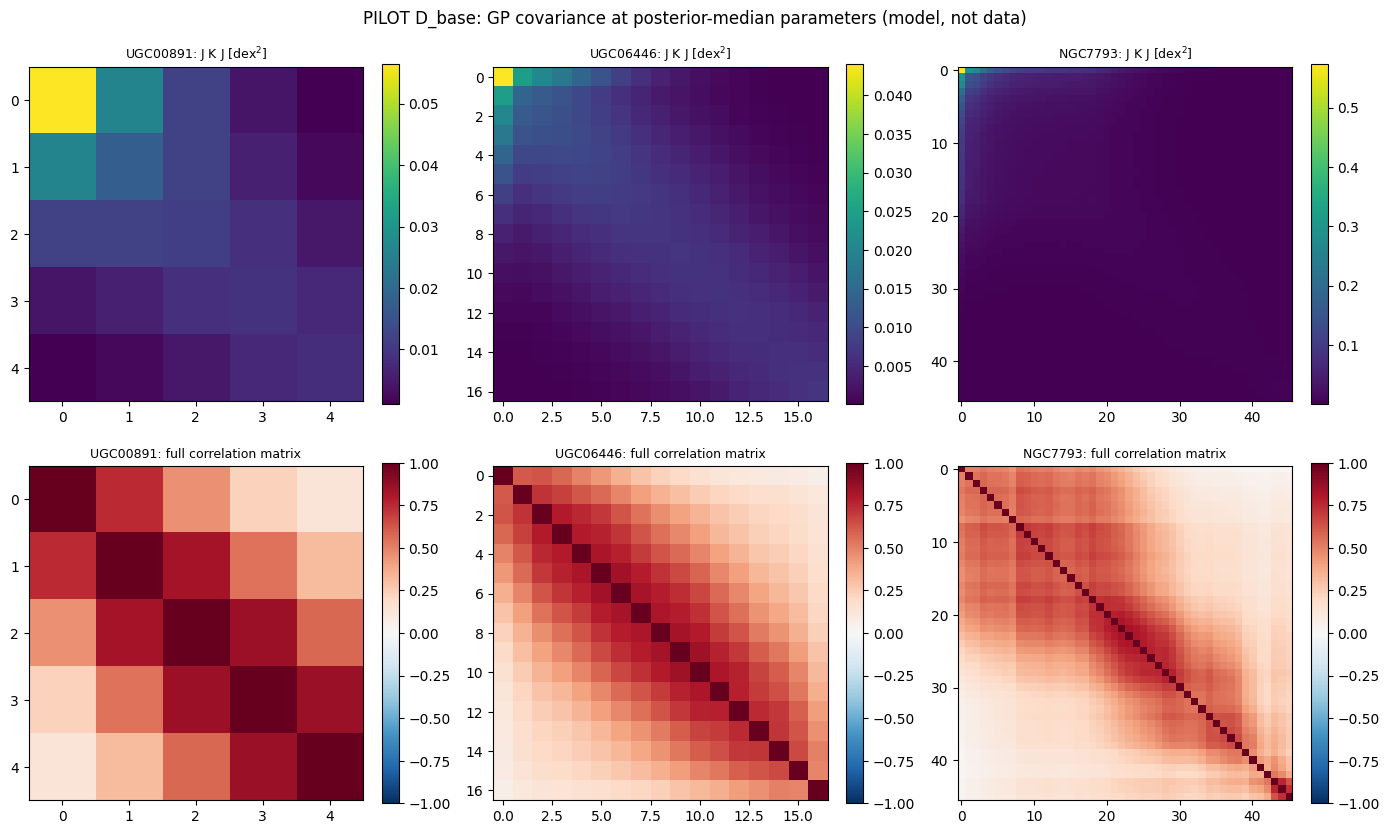

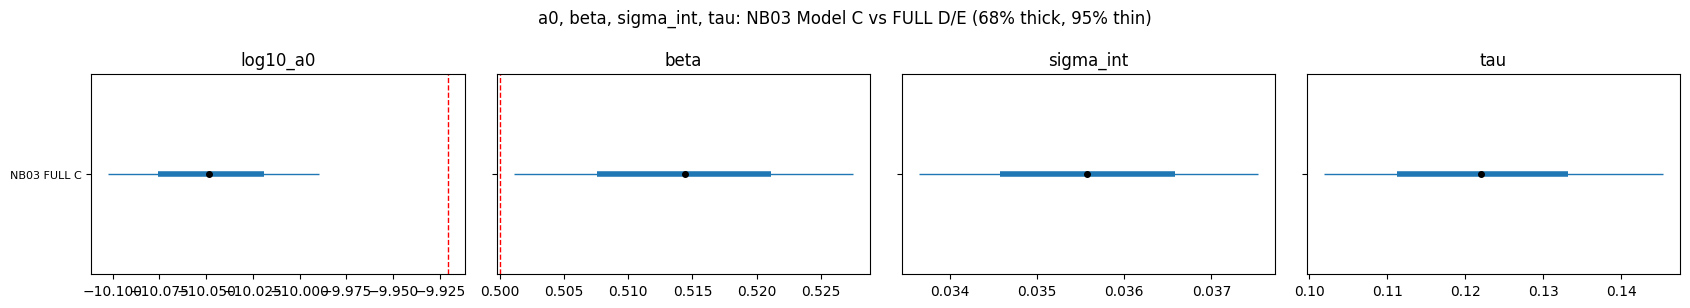

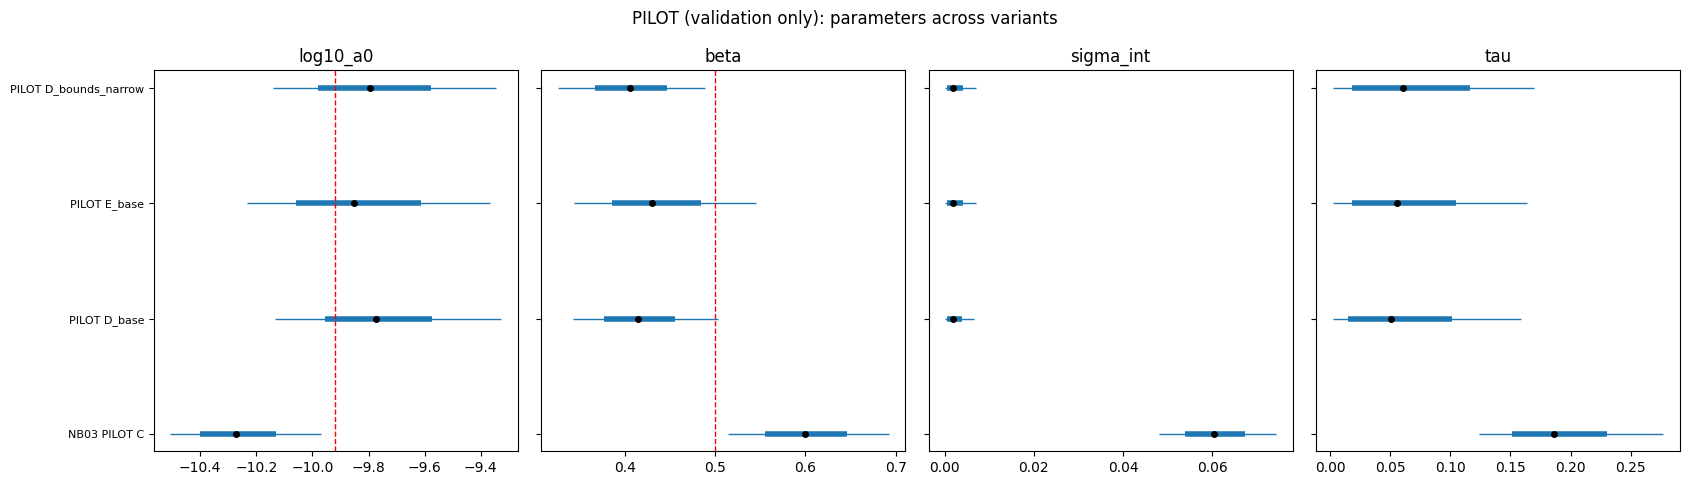

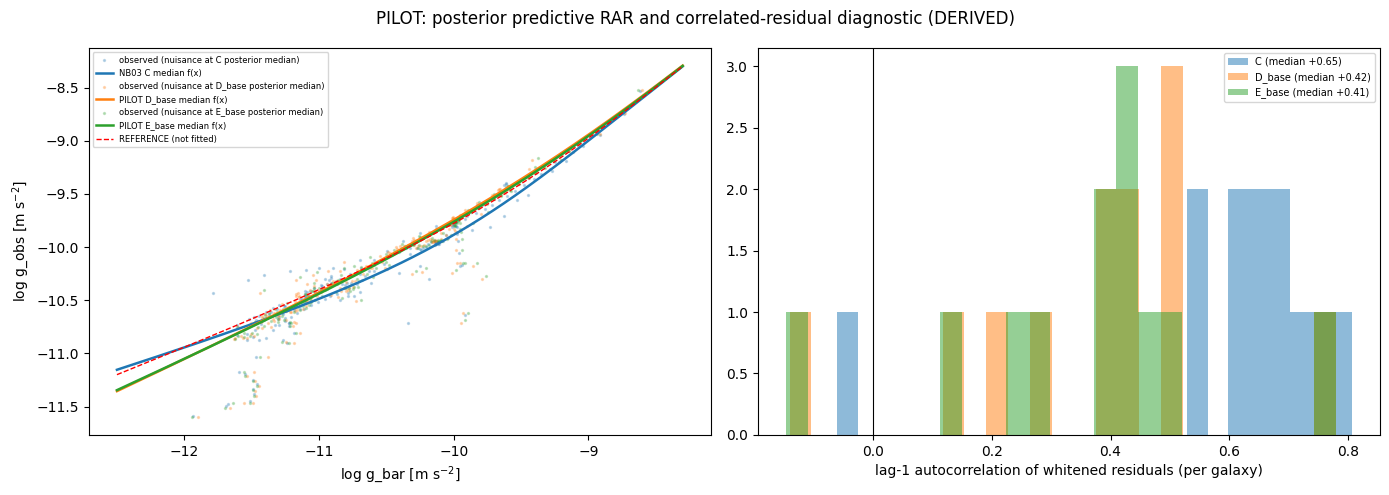

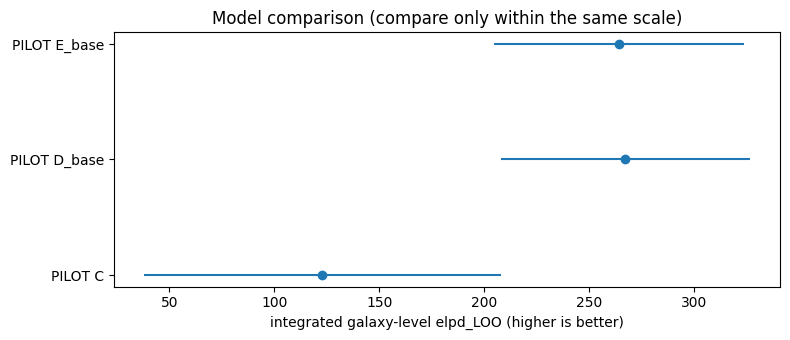

In [24]:
def choose_display(results_full, results_pilot):
    if "D" in results_full and "mcmc" in results_full["D"]: return results_full["D"], "FULL Model D"
    return results_pilot.get("D_base"), "PILOT D_base"
disp, disp_label = choose_display(FULL_RESULTS, PILOT_RESULTS)

# (1) Covariance heatmaps for three representative galaxies (few / median / many points)
if disp and "mcmc" in disp:
    smp = disp["mcmc"].get_samples(); data = disp["data"]; cfg = disp["cfg"]
    med = lambda k: jnp.asarray(np.median(np.asarray(smp[k]), axis=0))
    th = tuple(float(np.median(np.asarray(smp[k]))) for k in ("log10_a0", "beta", "sigma_int", "tau")) + (1.0,)
    ub = jnp.full(data["G"], REF["upsilon_bulge"])
    if data["n_bulge"]: ub = ub.at[data["bulge_local"]].set(med("ups_bulge"))
    nuis = (med("D"), med("inc"), med("ups_disk"), ub)
    gp = {"ell": med("ell"), **({"A": med("A")} if cfg["mode"] == "additive" else {"phi": float(np.median(np.asarray(smp["phi"])))})}
    r, x, y, mu, d_ind, cvec, ell, kind = covariance_parts(th, nuis, gp, data, cfg)
    order = np.argsort(data["npts"]); picks = [order[0], order[len(order) // 2], order[-1]]
    fig, ax = plt.subplots(2, 3, figsize=(14, 8.5))
    for j, g in enumerate(picks):
        b = next(b for b in data["buckets"] if g in np.asarray(b["gal"])); a = int(np.where(np.asarray(b["gal"]) == g)[0][0]); n = int(b["n"][a])
        S = np.asarray(bucket_cov(b, d_ind, cvec, ell, th[3], kind, 0.0))[a, :n, :n]
        JKJ = np.asarray(bucket_cov(b, jnp.zeros_like(d_ind), cvec, ell, 0.0, kind, 0.0))[a, :n, :n]
        name = gtab.galaxy.iloc[data["gal_ids"][g]]
        im = ax[0, j].imshow(JKJ, cmap="viridis"); fig.colorbar(im, ax=ax[0, j], fraction=0.046); ax[0, j].set_title(f"{name}: J K J [dex$^2$]", fontsize=9)
        Cn = S / np.sqrt(np.outer(np.diag(S), np.diag(S)))
        im = ax[1, j].imshow(Cn, cmap="RdBu_r", vmin=-1, vmax=1); fig.colorbar(im, ax=ax[1, j], fraction=0.046); ax[1, j].set_title(f"{name}: full correlation matrix", fontsize=9)
    fig.suptitle(f"{disp_label}: GP covariance at posterior-median parameters (model, not data)"); fig.tight_layout()
    fig.savefig(safe_path(OUT["figures"] / "04d_gp_covariance_heatmaps.png"), dpi=130); plt.show()

# (4)+(5)+(10) parameter comparison across models
def fig_param_compare(df_list, fname, title):
    rows = []
    for lab, s in df_list:
        for p in ("log10_a0", "beta", "sigma_int", "tau"):
            r = s[s.parameter == p]
            if len(r): rows.append((lab, p, r["median"].iloc[0], r["ci68_low"].iloc[0], r["ci68_high"].iloc[0], r["ci95_low"].iloc[0], r["ci95_high"].iloc[0]))
    if not rows: return
    t = pd.DataFrame(rows, columns=["label", "p", "med", "l68", "h68", "l95", "h95"])
    fig, ax = plt.subplots(1, 4, figsize=(17, 0.6 * t.label.nunique() + 2.5))
    for a, p in zip(ax, ("log10_a0", "beta", "sigma_int", "tau")):
        tt = t[t.p == p].reset_index(drop=True)
        a.hlines(range(len(tt)), tt.l95, tt.h95, color="C0", lw=1); a.hlines(range(len(tt)), tt.l68, tt.h68, color="C0", lw=4); a.plot(tt.med, range(len(tt)), "ko", ms=4)
        a.set_yticks(range(len(tt))); a.set_yticklabels(tt.label if p == "log10_a0" else [""] * len(tt), fontsize=8); a.set_title(p)
        if p == "log10_a0": a.axvline(np.log10(REF["a0"]), color="r", ls="--", lw=1, label="REFERENCE")
        if p == "beta": a.axvline(REF["beta"], color="r", ls="--", lw=1)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(safe_path(OUT["figures"] / fname), dpi=130); plt.show()

lst = [("NB03 FULL C", sumC)] + [(f"FULL {m}", r["summary"]) for m, r in FULL_RESULTS.items() if "summary" in r]
fig_param_compare(lst, "04d_gp_full_parameter_comparison_C_D_E.png", "a0, beta, sigma_int, tau: NB03 Model C vs FULL D/E (68% thick, 95% thin)")
lstp = ([("NB03 PILOT C", pilot_models["C"]["summary"])] if "C" in pilot_models else []) + [(f"PILOT {v}", r["summary"]) for v, r in PILOT_RESULTS.items() if "summary" in r]
fig_param_compare(lstp, "04d_gp_pilot_parameter_comparison.png", "PILOT (validation only): parameters across variants")

# (6)+(7) predictive RAR and correlated-residual diagnostics
cov_src, cov_label = (full_cov, "FULL") if full_cov else (pilot_cov, "PILOT")
if cov_src:
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    lg = np.linspace(-12.5, -8.3, 200)
    for m, pw in cov_src.items():
        ax[0].scatter(pw["x_med"], pw["y_med"], s=2, alpha=0.25, label=f"observed (nuisance at {m} posterior median)")
        info = (models_here if cov_src is full_cov else pilot_models)[m]; smp = info["samples"]
        la0, bb = np.median(np.asarray(smp["log10_a0"])), np.median(np.asarray(smp["beta"]))
        ax[0].plot(lg, np.asarray(f_rar(lg, la0, bb)), lw=1.8, label=(f"NB03 {m}" if m == "C" else f"{cov_label} {m}") + " median f(x)")
        ax[1].hist(pw["lag1_per_galaxy"][np.isfinite(pw["lag1_per_galaxy"])], bins=25, alpha=0.5, label=f"{m} (median {pw['lag1_whitened_median_over_galaxies']:+.2f})")
    ax[0].plot(lg, np.asarray(f_rar(lg, np.log10(REF["a0"]), REF["beta"])), "r--", lw=1, label="REFERENCE (not fitted)")
    ax[0].set_xlabel("log g_bar [m s$^{-2}$]"); ax[0].set_ylabel("log g_obs [m s$^{-2}$]"); ax[0].legend(fontsize=6)
    ax[1].axvline(0, color="k", lw=0.8); ax[1].set_xlabel("lag-1 autocorrelation of whitened residuals (per galaxy)"); ax[1].legend(fontsize=7)
    fig.suptitle(f"{cov_label}: posterior predictive RAR and correlated-residual diagnostic (DERIVED)"); fig.tight_layout()
    fig.savefig(safe_path(OUT["figures"] / f"04d_gp_{cov_label.lower()}_ppc_and_whitened_residuals.png"), dpi=130); plt.show()

# (10) model comparison summary: integrated elpd
mc_df = model_comparison.dropna(subset=["elpd_integrated_loo"]) if "elpd_integrated_loo" in model_comparison else pd.DataFrame()
if len(mc_df):
    fig, ax = plt.subplots(figsize=(8, 0.5 * len(mc_df) + 2))
    labels = mc_df.scale.str.split(" ").str[0] + " " + mc_df.model
    ax.errorbar(mc_df.elpd_integrated_loo, range(len(mc_df)), xerr=mc_df.elpd_se, fmt="o")
    ax.set_yticks(range(len(mc_df))); ax.set_yticklabels(labels); ax.set_xlabel("integrated galaxy-level elpd_LOO (higher is better)")
    ax.set_title("Model comparison (compare only within the same scale)"); fig.tight_layout()
    fig.savefig(safe_path(OUT["figures"] / "04d_gp_model_comparison_summary.png"), dpi=130); plt.show()
if "D" in FULL_RESULTS and "mcmc" in FULL_RESULTS["D"]:
    fig_traces(FULL_RESULTS["D"], "FULL Model D", "04d_gp_full_model_D_traces.png")
    fig_gp_prior_post(FULL_RESULTS["D"], "FULL Model D", "04d_gp_full_model_D_gp_prior_vs_posterior.png")
    fig_pairs(FULL_RESULTS["D"], "FULL Model D", "04d_gp_full_model_D_pair_correlations.png")

## 18. Results Export and Reproducibility (all under the versioned debug directory)

In [25]:
diag_all = [r["diag"].assign(stage=f"PILOT {v}") for v, r in PILOT_RESULTS.items() if "diag" in r] + \
           [r["diag"].assign(stage=f"FULL Model {m}") for m, r in FULL_RESULTS.items() if "diag" in r]
pd.concat(diag_all).to_csv(safe_path(OUT["diagnostics"] / "04d_gp_mcmc_diagnostics.csv"), index=False) if diag_all else None
param_all = [r["summary"] for r in PILOT_RESULTS.values() if "summary" in r] + [r["summary"] for r in FULL_RESULTS.values() if "summary" in r] + [sumC.assign(stage="NB03 FULL Model C (read, not refitted)")]
pd.concat(param_all).to_csv(safe_path(OUT["tables"] / "04d_gp_parameter_summary.csv"), index=False)
model_comparison.to_csv(safe_path(OUT["tables"] / "04d_gp_model_comparison.csv"), index=False)
pd.concat([pilot_loo.assign(scale="PILOT"), full_loo.assign(scale="FULL")]).to_csv(safe_path(OUT["diagnostics"] / "04d_gp_integrated_loo_per_galaxy.csv"), index=False)
cov_checks.to_csv(safe_path(OUT["diagnostics"] / "04d_covariance_checks.csv"), index=False)
ident_full = []
for m, r in FULL_RESULTS.items():
    if "mcmc" in r: t, c = identifiability(r, f"FULL Model {m}"); ident_full.append(t)
pd.concat([ident_pilot] + ident_full).to_csv(safe_path(OUT["diagnostics"] / "04d_identifiability_diagnostics.csv"), index=False)
gp_prior_table.to_csv(safe_path(OUT["tables"] / "04d_gp_prior_summary.csv"), index=False)
pd.DataFrame(CHECKS).to_csv(safe_path(OUT["diagnostics"] / "04d_integrity_checks.csv"), index=False)
config = {"run_id": RUN_ID, "created_utc": RUN_TIMESTAMP, "versions": VERSIONS, "seed": SEED, "notebook03_run_id": RUN03,
          "notebook03_posteriors": {m: str(p) for m, p in NC03.items()}, "gp": GP, "bound_variants": BOUND_VARIANTS, "gp_priors": GP_PRIORS,
          "ups_sigma_dex": UPS_SIGMA_DEX, "shared_priors_from_nb03": P03, "target_accept": TARGET_ACCEPT, "max_tree_depth": MAX_TREE_DEPTH,
          "sampler_revised": SAMPLER, "sampler_original": ORIGINAL_SAMPLER, "reparameterisation": REPARAM, "bfmi_min": BFMI_MIN,
          "stage_switches": {"RUN_PILOT": RUN_PILOT, "RUN_FULL_D": RUN_FULL_D, "RUN_FULL_E": RUN_FULL_E, "RUN_SENSITIVITY_PILOTS": RUN_SENSITIVITY_PILOTS,
                             "RUN_TARGET_098_TEST": RUN_TARGET_098_TEST, "RUN_ORIGINAL_SETTINGS_REPLAY": RUN_ORIGINAL_SETTINGS_REPLAY},
          "original_nb04_run_id": (ORIG04 or {}).get("run_id"), "equivalence_tests": EQUIV, "output_root": str(OUT_ROOT),
          "pilot": {**PILOT, "galaxies": pilot_names, "variants": {v: {"cfg": r["cfg"], "seconds": r.get("seconds"), "stats": r.get("stats"), "error": r.get("error"),
                    "netcdf": str(r.get("nc")), "warnings": r.get("warnings", [])[:10]} for v, r in PILOT_RESULTS.items()}},
          "run_full": RUN_FULL, "forced_full": bool(FORCE_FULL_DESPITE_PILOT and not (PILOT_OK and PILOT_OK_E)),
          "full": {**FULL, "completed": {m: {"seconds": r.get("seconds"), "stats": r.get("stats"), "netcdf": str(r.get("nc")), "error": r.get("error")} for m, r in FULL_RESULTS.items()}},
          "convergence_criteria": {"rank_r_hat_max": RHAT_MAX, "ess_bulk_min": ESS_BULK_MIN, "ess_tail_min": ESS_TAIL_MIN, "divergences_max": DIVERGENCES_MAX, "tree_depth_hits_max": 0, "bfmi_min": BFMI_MIN},
          "integrated_loo": ILOO, "ppc_draws": PPC_DRAWS, "benchmark": BENCH, "regression_test": regression,
          "data_checksums": {NB02[k].name: sha256_of(NB02[k]) for k in NB02}, "n_points": int(include_mask.sum()), "n_galaxies": G,
          "beam_sizes": "not available for SPARC in the project files; correlation-length bounds use radial spacing and extent only",
          "resume_note": "No sampler-state checkpointing; interrupted chains cannot be resumed."}
(safe_path(OUT["config"] / "04d_gp_sampler_config.json")).write_text(json.dumps(config, indent=2, default=str))
print("Exports written.")
pd.DataFrame([{"package": k, "version": str(v)} for k, v in VERSIONS.items()]).to_csv(OUT["config"] / "04d_package_versions.csv", index=False)
reparam_table.to_csv(OUT["tables"] / "04d_reparameterisation_table.csv", index=False)
manifest = pd.DataFrame([{"file": str(p.relative_to(OUT_ROOT)), "bytes": p.stat().st_size} for p in sorted(OUT_ROOT.rglob("*")) if p.is_file()])
manifest.to_csv(OUT["config"] / "04d_output_manifest.csv", index=False)
print(f"Exports written under {OUT_ROOT} ({len(manifest)} files).")

Exports written.
Exports written under /content/drive/MyDrive/RAR_Universality_Research/05_Results/Diagnostics/04_GP_Debugged/20261023T095057Z (44 files).


## 19. Debugging and Validation Report

In [26]:
chk = pd.DataFrame(CHECKS)
def ptab(s):
    keep = s[s.parameter.isin(["log10_a0", "beta", "sigma_int", "tau", "A_pop", "phi", "ell_median_kpc"])]
    return "\n".join(f"| {r.parameter} | {r.median:.4f} | [{r.ci68_low:.4f}, {r.ci68_high:.4f}] | [{r.ci95_low:.4f}, {r.ci95_high:.4f}] |" for r in keep.itertuples())
def stline(v, r):
    if "error" in r: return f"* {v}: ERROR {r['error']}"
    s = r["stats"]
    return (f"* {v}: **{'converged by all criteria' if s['converged_by_all_criteria'] else 'NOT converged'}**; max R-hat {s['max_r_hat_all']:.4f}; "
            f"min ESS bulk/tail {s['min_ess_bulk_all']:.0f}/{s['min_ess_tail_all']:.0f}; divergences {s['divergences']} {s['divergences_per_chain']}; "
            f"tree-depth hits {s['max_tree_depth_hits']}; mean accept {s['mean_accept_prob']:.3f}; step sizes {np.round(s['step_size_per_chain'], 4).tolist()}; "
            f"min BFMI {min(s['bfmi_per_chain']):.2f}; {r['seconds']/60:.1f} min")
pilot_lines = "\n".join(stline(v, r) for v, r in PILOT_RESULTS.items()) or "* No pilot run in this session (RUN_PILOT = False)."
orig_lines = "\n".join(f"* {r['variant']}: divergences {r['divergences']} {r.get('divergences_per_chain')}, tree-depth hits {r.get('max_tree_depth_hits')}, "
                       f"accept per chain {r.get('accept_per_chain')}, max R-hat {r['max_r_hat_all']:.4f}" for r in ORIG_STATS) or "* original run not found"
def hyp_lines(df):
    if df is None or not len(df): return "* (none)"
    out = []
    for r in df.itertuples():
        if r.n_divergent == 0: out.append(f"* {r.stage}: no divergences"); continue
        tag = "SUPPORTED (p < 0.01, >= 2 draws)" if (r.binomial_p_one_sided < 0.01 and r.n_div_meeting_condition >= 2) else "not supported by this test"
        out.append(f"* {r.stage} | {r.hypothesis}: {r.n_div_meeting_condition}/{r.n_divergent} vs {r.expected_if_random:.2f} expected (p = {r.binomial_p_one_sided:.3g}) — {tag}")
    return "\n".join(out)
full_lines = "\n\n".join(f"### FULL Model {m} — " + ("FAILED: " + r["error"] if "error" in r else
                          ("converged by all criteria" if r["stats"]["converged_by_all_criteria"] else "NOT CONVERGED: do not interpret")
                          + f"\n\n| parameter | median | 68% | 95% |\n|---|---|---|---|\n{ptab(r['summary'])}") for m, r in FULL_RESULTS.items()) or \
             "**Full Models D and E were not run in this session (RUN_FULL_D = RUN_FULL_E = False); no full-sample GP results exist.**"
ident_all = pd.concat([ident_pilot] + ident_full) if len(ident_pilot) else pd.DataFrame(columns=["stage", "quantity", "value"])
gate = {"D": PILOT_OK, "E": PILOT_OK_E}
report = f"""# Notebook 04 (Debugged) — Debugging and Validation Report

*Run {RUN_ID} ({RUN_TIMESTAMP} UTC). Builds on Notebook 03 run {RUN03} and diagnoses original Notebook 04 run {(ORIG04 or {}).get("run_id")}. This file exists only if the notebook ran.*

## Scope
Numerical inference reliability only. The proposal, research questions, hypotheses, equations, data selection, likelihood, GP structure, pooling and priors are unchanged (tests below).

## Original pilot (read from the earlier run)
{orig_lines}

### Divergence localisation, original pilots
{hyp_lines(pd.concat(ORIG_DIAG, ignore_index=True) if ORIG_DIAG else None)}

## Changes (numerical only)
* Sampler: target_accept {ORIGINAL_SAMPLER["target_accept"]} -> {SAMPLER["target_accept"]}; pilot warmup {ORIGINAL_SAMPLER["pilot_warmup"]} -> {PILOT["warmup"]}; dense mass block for globals = {SAMPLER["dense_mass_globals"]}; independent dispersed chain starts (jitter {SAMPLER["init_jitter"]}); max tree depth {SAMPLER["max_tree_depth"]} (unchanged).
* Exact reparameterisations: {json.dumps(REPARAM)}. Jitter: {GP["jitter_dex2"]} (not required; condition numbers below 1e10).

## Equivalence tests (original vs revised)
{chr(10).join(f"* {r['test']} [{r['model']}]: max deviation {r['max_abs_deviation']:.3e} (tol {r['tolerance']}) {r['unit']} -> {'PASS' if r['pass'] else 'FAIL'}" for r in EQUIV)}
* Zero-GP vs Notebook 03 saved Model C: max |diff| = {regression["max_abs_diff_vs_saved_NB03"]:.2e}.

## Revised pilot (validation only)
{pilot_lines}

### Divergence localisation, revised pilots
{hyp_lines(rev_div if len(rev_div) else None)}

## Identifiability (preliminary; formal injection-recovery in Notebook 06)
{chr(10).join(f"* {r.stage}: {r.value}" for r in ident_all.query("quantity == 'non_identifiability_flags'").itertuples())}

Convergence of the sampler does not make sigma_int, tau, A and l separately identifiable. Section 13 reports their joint posteriors and contraction. No astrophysical claim follows from the pilot.

## Full-run gate
* Model D: {"OPEN" if gate["D"] else "CLOSED"} (PILOT D_base debugged converged by all criteria = {gate["D"]}); RUN_FULL_D = {RUN_FULL_D}.
* Model E: {"OPEN" if gate["E"] else "CLOSED"} (PILOT E_base debugged converged by all criteria = {gate["E"]}); RUN_FULL_E = {RUN_FULL_E}.

## FULL
{full_lines}

## Intrinsic scatter: independent vs correlated errors
{REDUCTION_TEXT}

## Checks
{len(chk)} checks: {int((chk.status=="FAIL").sum())} FAIL, {int((chk.status=="WARN").sum())} WARN.
"""
rep = OUT["tables"] / "04d_GP_Debugging_and_Validation_Report.md"; rep.write_text(report, encoding="utf-8")
chk.to_csv(OUT["diagnostics"] / "04d_integrity_checks_final.csv", index=False)
print("=" * 72); print("NOTEBOOK 04 (DEBUGGED) SUMMARY"); print("=" * 72)
print(f"Sample: {G} galaxies, {int(include_mask.sum())} points (Notebook 03 run {RUN03})")
print("Equivalence:", f"{sum(r['pass'] for r in EQUIV)}/{len(EQUIV)} pass")
print(pilot_lines)
print("Full-run gate:", {k: ("open" if v else "closed") for k, v in gate.items()}, "| RUN_FULL_D", RUN_FULL_D, "| RUN_FULL_E", RUN_FULL_E)
print(f"Checks: {len(chk)} | FAIL {int((chk.status=='FAIL').sum())} | WARN {int((chk.status=='WARN').sum())}")
print("Report:", rep); print("Outputs:", OUT_ROOT); print("Log:", LOG_PATH)

NOTEBOOK 04 (DEBUGGED) SUMMARY
Sample: 153 galaxies, 3164 points (Notebook 03 run 20261022T095735Z)
Equivalence: 6/6 pass
* D_base: **converged by all criteria**; max R-hat 1.0042; min ESS bulk/tail 980/1328; divergences 0 [0, 0, 0, 0]; tree-depth hits 0; mean accept 0.955; step sizes [0.0842, 0.0838, 0.0909, 0.0961]; min BFMI 0.72; 22.1 min
* E_base: **converged by all criteria**; max R-hat 1.0049; min ESS bulk/tail 884/1291; divergences 0 [0, 0, 0, 0]; tree-depth hits 0; mean accept 0.964; step sizes [0.0979, 0.0588, 0.0735, 0.0707]; min BFMI 0.68; 22.9 min
* D_bounds_narrow: **converged by all criteria**; max R-hat 1.0051; min ESS bulk/tail 620/1654; divergences 0 [0, 0, 0, 0]; tree-depth hits 0; mean accept 0.965; step sizes [0.0636, 0.0933, 0.0691, 0.071]; min BFMI 0.73; 21.5 min
Full-run gate: {'D': 'open', 'E': 'open'} | RUN_FULL_D False | RUN_FULL_E False
Checks: 45 | FAIL 0 | WARN 1
Report: /content/drive/MyDrive/RAR_Universality_Research/05_Results/Diagnostics/04_GP_Debugged/